# CGAN - Aula Prática


## Configurações

Importando módulos necessários e baixando os datasets.


In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt

import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, random_split
from torchvision.datasets import ImageFolder, CIFAR10
import torchvision.transforms.v2 as transforms
import torchvision.transforms.v2.functional as K

from tqdm.notebook import tqdm
from sklearn.preprocessing import LabelEncoder

## Introdução

GANs (Generative Adversarial Networks) são uma arquitetura de rede neural que tem como objetivo gerar novos dados a partir de um conjunto de dados de treinamento. A ideia é que a rede neural seja capaz de aprender a distribuição dos dados de treinamento e, a partir disso, gerar novos dados que sejam semelhantes aos dados de treinamento. Neste notebook, vamos implementar uma GAN para gerar imagens de personagens de anime.


## Dataset

O dataset que vamos utilizar é o [CiFAR10](https://pytorch.org/vision/main/generated/torchvision.datasets.CIFAR10.html) que é composto por 60.000 imagens coloridas de 32x32 pixels divididas em 10 classes. As classes são: 'airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship' e 'truck'.

Esse dataset é muito utilizado para treinar modelos de redes neurais convolucionais, mas também pode ser utilizado para treinar GANs.

In [ ]:
cifar10_path = '/pgeoprj2/ciag2024/dados'

In [3]:
# function to plot samples and metadata of a dataset
def plot_dataset(
    dataset,
    n_rows=4,
    n_cols=4,
    figsize=(6, 6),
    denormalize=False,
    label_decoder=lambda x: [x],
):
    print(f'Number of samples: {len(dataset)}')
    print(f'Sample shape: {dataset[0][0].shape}')

    samples = np.random.randint(0, len(dataset), size=(n_rows, n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=figsize)

    for i in range(n_rows):
        for j in range(n_cols):
            image, label = dataset[samples[i, j]]
            label = label_decoder(label)[0]
            if denormalize:
                image = K.normalize(image, -1, 2)
                image = image.clamp(0, 1)
            image = image.permute(1, 2, 0)
            im = axes[i, j].imshow(image)
            if image.shape[2] == 1:
                im.set_cmap('gray')
            axes[i, j].set_title(label)
            axes[i, j].axis('off')

    plt.show()

In [4]:
cifar10 = CIFAR10(
    root=cifar10_path,
    train=True,
    download=True,
    transform=transforms.Compose(
        [
            transforms.ToImage(),
            transforms.ToDtype(torch.float32, scale=True),
            transforms.Resize((32, 32)),
            transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
        ]
    ),
)

Files already downloaded and verified


In [5]:
class DatasetLabelMapper(object):
    def __init__(self, dataset):
        self.mapping = {
            i: label for i, label in enumerate(dataset.classes)
        }

        self.label_encoder = LabelEncoder()
        self.label_encoder.fit(list(self.mapping.values()))
        # make sure the classes are in order
        self.label_encoder.classes_ = np.array(list(self.mapping.values()))

    def __getitem__(self, label):
        return self.mapping[label]

    def __call__(self, label):
        return self.label_encoder.inverse_transform(
            [label] if isinstance(label, int) else label
        )


label_mapper = DatasetLabelMapper(cifar10)

Number of samples: 50000
Sample shape: torch.Size([3, 32, 32])


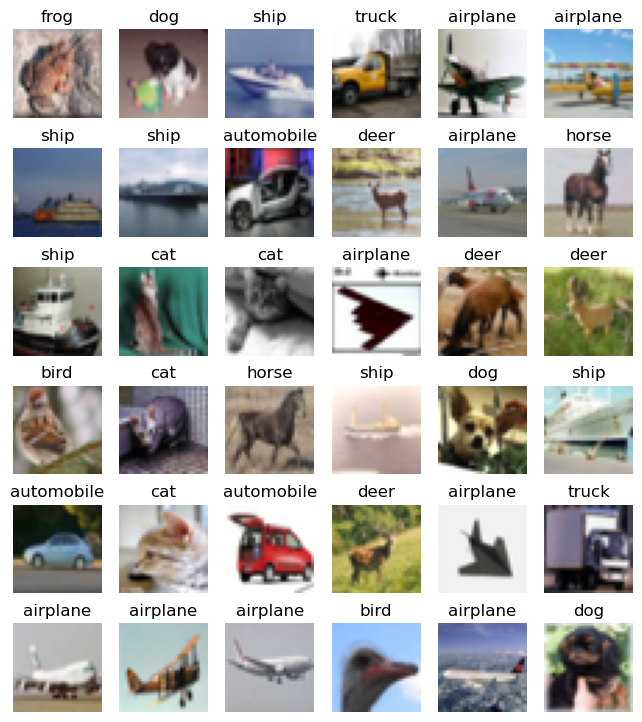

In [6]:
plot_dataset(
    cifar10,
    n_cols=6,
    n_rows=6,
    denormalize=True,
    figsize=(8, 9),
    label_decoder=label_mapper,
)

## Modelo

A CGAN (Conditional Generative Adversarial Network) é uma extensão da GAN que permite a geração de imagens condicionadas a uma label. A ideia é que a rede geradora receba uma label como entrada e gere uma imagem correspondente a essa label. A rede discriminadora, por sua vez, recebe a imagem gerada e a label correspondente e tem como objetivo distinguir entre imagens reais e imagens geradas.

A arquitetura da CGAN é semelhante à arquitetura da GAN, mas com a adição de uma label como entrada. A label é concatenada com a entrada da rede geradora e com a entrada da rede discriminadora. Como podemos ver na imagem abaixo:


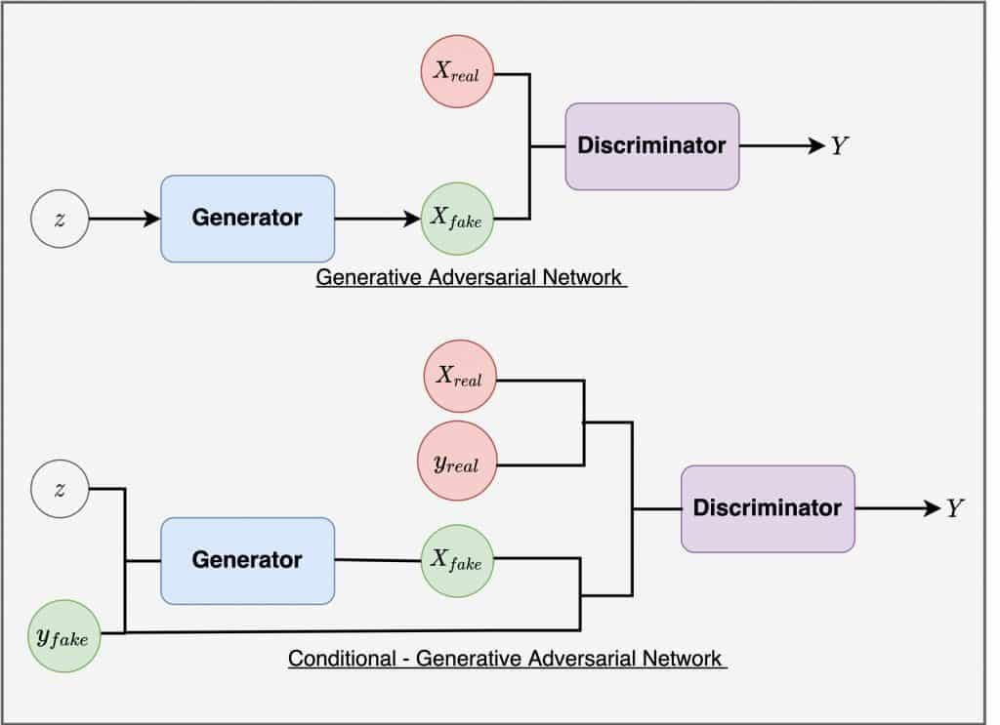


### Gerador

O gerador é uma rede neural que recebe um vetor de valores aleatórios como entrada (a semente da geração) e gera uma imagem como saída. A ideia é que o gerador aprenda a mapear vetores de números aleatórios para imagens que sejam semelhantes às imagens de treinamento. O gerador é treinado para enganar o discriminador, ou seja, para gerar imagens que o discriminador classifica como reais.


In [7]:
def plot_generated_images(
    generator,
    num_images=64,
    num_classes=10,
    latent_dim=128,
    figsize=(6, 6),
    device='cpu',
    denormalize=False,
    label_decoder=lambda x: x,
):

    # generator.eval()

    with torch.no_grad():
        labels = torch.randint(0, num_classes, (num_images,)).to(device)
        noise = torch.randn(num_images, latent_dim, 1, 1).to(device)
        generated_images = generator(labels, noise).cpu()

    labels = label_decoder(labels.cpu())

    generated_images = generated_images.permute(0, 2, 3, 1)
    if denormalize:
        generated_images = K.normalize(generated_images, -1, 2)  # Normalize to (0, 1)

    n_rows = int(math.sqrt(num_images))
    n_cols = int(math.sqrt(num_images))

    fig, axes = plt.subplots(n_rows, n_cols, figsize=figsize)
    for i in range(n_rows):
        for j in range(n_cols):
            im = axes[i, j].imshow(generated_images[i * n_cols + j])
            if generated_images[i * n_cols + j].shape[-1] == 1:
                im.set_cmap('gray')
            axes[i, j].set_title(labels[i * n_cols + j].item())
            axes[i, j].axis('off')

    plt.show()

In [8]:
class Generator(nn.Module):
    def __init__(self, latent_size=128, n_classes=10, output_dim=3):
        super(Generator, self).__init__()

        # latent_size is the size of the input noise vector
        self.latent_size = latent_size
        self.embedding = nn.Sequential(
            nn.Embedding(n_classes, latent_size), 
            nn.Unflatten(1, (latent_size, 1, 1))
        )

        self.net = nn.Sequential(
            nn.ConvTranspose2d(latent_size*2, 512, kernel_size=4, stride=1, bias=False),  # (512, 4, 4)
            nn.BatchNorm2d(512),
            nn.GELU(),
            nn.ConvTranspose2d(512, 256, kernel_size=4, stride=2, padding=1, bias=False),  # (256, 8, 8)
            nn.BatchNorm2d(256),
            nn.GELU(),
            nn.ConvTranspose2d(256, 128, kernel_size=4, stride=2, padding=1, bias=False),  # (128, 16, 16)
            nn.BatchNorm2d(128),
            nn.GELU(),
            nn.ConvTranspose2d(128, output_dim, kernel_size=4, stride=2, padding=1, bias=False),  # (output_dim, 32, 32)
            nn.Tanh()
        )
    
    def forward(self, y, x=None, batch_size=1):
        if x is None:
            device = next(self.parameters()).device
            x = torch.randn(batch_size, self.latent_size, 1, 1, device=device)
        elif batch_size > 1:
            print('Warning: changing batch_size with x is not supported, the batch size will be the size of x')
        
        y = self.embedding(y)
        
        return self.net(torch.cat([x, y], dim=1))

In [9]:
generator = Generator(output_dim=3)
generator.to('cuda')
labels = torch.randint(0, 10, (256,), device='cuda')
noise = torch.randn(256, 128, 1, 1, device='cuda')
generator(labels, batch_size=256).shape

torch.Size([256, 3, 32, 32])

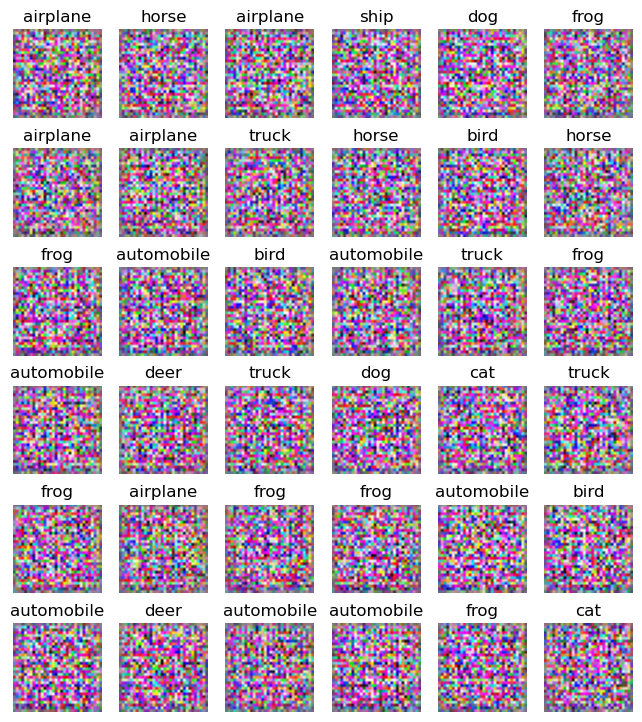

In [10]:
plot_generated_images(
    generator,
    device='cuda',
    num_images=36,
    denormalize=True,
    figsize=(8, 9),
    label_decoder=label_mapper,
)

### Discriminador

O discriminador é uma rede neural que recebe uma imagem como entrada e classifica se a imagem é real (vinda do conjunto de treinamento) ou falsa (gerada). O discriminador é treinado para distinguir entre imagens reais e falsas.


In [11]:
class Discriminator(nn.Module):
    def __init__(self, in_channels=3, n_classes=10):
        super(Discriminator, self).__init__()

        self.embedding = nn.Sequential(
            nn.Embedding(n_classes, 32*32),
            nn.Unflatten(1, (1, 32, 32))
        )

        self.net = nn.Sequential(
            # +1 for the label channel
            nn.Conv2d(in_channels+1, 64, kernel_size=4, stride=2, padding=1, bias=False), # (64, 16, 16)
            nn.BatchNorm2d(64),
            nn.LeakyReLU(0.2),
            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1, bias=False),  # (128, 8, 8)
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2),
            nn.Conv2d(128, 256, kernel_size=4, stride=2, padding=1, bias=False),  # (256, 4, 4)
            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2),
            nn.Conv2d(256, 1, kernel_size=4, bias=False),  # (1, 1, 1)
            nn.Flatten(),
            nn.Sigmoid()
        )

    def forward(self, x, y):
        y = self.embedding(y)
        return self.net(torch.cat([x, y], dim=1))

In [12]:
discriminator = Discriminator()
discriminator.to('cuda')
discriminator(
    torch.randn(256, 3, 32, 32, device='cuda'), torch.randint(0, 10, (256,), device='cuda')
).shape

torch.Size([256, 1])

## Treinando o modelo

Vamos treinar o modelo para reconstruir imagens do dataset. O modelo será treinado por 32 épocas, com batch size 128 e otimizador Adam.


In [48]:
def train(
    generator,
    discriminator,
    train_loader,
    val_loader,
    g_optimizer,
    d_optimizer,
    criterion,
    device,
    num_classes=10,
    epochs=24,
    plot_frequency=None,
    label_mapper=lambda x: x,
):
    generator.to(device)
    discriminator.to(device)

    g_losses_train = []
    d_losses_train = []
    d_accuracies_train = []
    real_scores_train = []
    fake_scores_train = []

    if val_loader is not None:
        g_losses_val = []
        d_losses_val = []
        d_accuracies_val = []
        real_scores_val = []
        fake_scores_val = []

    for epoch in range(epochs):
        generator.train()
        discriminator.train()

        g_loss_train = 0.0
        d_loss_train = 0.0
        d_batch_accuracy = 0.0
        real_score = 0.0
        fake_score = 0.0

        for i, (images, labels) in (
            pbar := tqdm(enumerate(train_loader), total=len(train_loader), unit='batch')
        ):
            real_images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            batch_size = real_images.size(0)

            # Train discriminator
            d_optimizer.zero_grad()

            real_outputs = discriminator(real_images, labels)
            real_labels = torch.ones_like(real_outputs, device=device)
            real_loss = criterion(real_outputs, real_labels)

            noise = torch.randn(batch_size, generator.latent_size, 1, 1, device=device)
            fake_images = generator(labels, noise)
            fake_outputs = discriminator(fake_images.detach(), labels)
            fake_labels = torch.zeros_like(fake_outputs, device=device)
            fake_loss = criterion(fake_outputs, fake_labels)

            batch_accuracy = (
                torch.mean(real_outputs >= 0.5, dtype=torch.float32)
                + torch.mean(fake_outputs < 0.5, dtype=torch.float32)
            ) / 2
            d_batch_accuracy += batch_accuracy.item()

            d_loss = real_loss + fake_loss
            d_loss_train += d_loss.item()
            real_score += real_outputs.mean().item()
            fake_score += fake_outputs.mean().item()

            d_loss.backward()
            d_optimizer.step()

            # Train generator
            g_optimizer.zero_grad()

            noise = torch.randn(batch_size, generator.latent_size, 1, 1, device=device)
            fake_images = generator(labels, noise)
            fake_outputs = discriminator(fake_images, labels)

            g_loss = criterion(fake_outputs, real_labels)
            g_loss_train += g_loss.item()

            g_loss.backward()
            g_optimizer.step()

            pbar.set_description(
                f'Epoch {epoch+1}/{epochs} G_Loss: {g_loss_train/((i+1)):.4f} D_Loss: {d_loss_train/(i+1):.4f}'
            )

        g_loss_train /= len(train_loader)
        d_loss_train /= len(train_loader)
        d_accuracy_train = d_batch_accuracy / (len(train_loader))
        real_score /= len(train_loader)
        fake_score /= len(train_loader)

        g_losses_train.append(g_loss_train)
        d_losses_train.append(d_loss_train)
        d_accuracies_train.append(d_accuracy_train)
        real_scores_train.append(real_score)
        fake_scores_train.append(fake_score)

        if val_loader is not None:
            with torch.no_grad():
                generator.eval()
                discriminator.eval()

                g_loss_val = 0.0
                d_loss_val = 0.0
                d_batch_accuracy = 0.0
                real_score = 0.0
                fake_score = 0.0

                for images, labels in val_loader:
                    real_images = images.to(device, non_blocking=True)
                    labels = labels.to(device, non_blocking=True)
                    batch_size = real_images.size(0)

                    # Evaluate discriminator

                    real_outputs = discriminator(real_images, labels)
                    real_labels = torch.ones_like(real_outputs, device=device)
                    real_loss = criterion(real_outputs, real_labels)

                    # Generate fake images
                    noise = torch.randn(
                        batch_size, generator.latent_size, 1, 1, device=device
                    )
                    fake_images = generator(labels, noise)

                    fake_outputs = discriminator(fake_images, labels)
                    fake_labels = torch.zeros_like(fake_outputs, device=device)
                    fake_loss = criterion(fake_outputs, fake_labels)

                    batch_accuracy = (
                        torch.mean(real_outputs >= 0.5, dtype=torch.float32)
                        + torch.mean(fake_outputs < 0.5, dtype=torch.float32)
                    ) / 2
                    d_batch_accuracy += batch_accuracy.item()

                    d_loss = real_loss + fake_loss
                    d_loss_val += d_loss.item()
                    real_score += real_outputs.mean().item()
                    fake_score += 1 - fake_outputs.mean().item()

                    # Evaluate generator

                    # reuse fake_images and fake_outputs to save computation
                    g_loss = criterion(fake_outputs, real_labels)

                    g_loss_val += g_loss.item()

                g_loss_val /= len(val_loader)
                d_loss_val /= len(val_loader)
                d_accuracy_val = d_batch_accuracy / len(val_loader)
                real_score /= len(val_loader)
                fake_score /= len(val_loader)

                g_losses_val.append(g_loss_val)
                d_losses_val.append(d_loss_val)
                d_accuracies_val.append(d_accuracy_val)
                real_scores_val.append(real_score)
                fake_scores_val.append(fake_score)
        print(
            f'[Epoch {epoch+1}/{epochs}]\n\tG_Trn_Loss: {g_loss_train:.4f}\tD_Trn_Loss: {d_loss_train:.4f}\tD_Trn_Real: {real_score:.4f}\tD_Trn_Fake: {fake_score:.4f}\tD_Trn_Acc: {d_accuracy_train*100:.2f}%',
            (
                ''
                if val_loader is None
                else f'\n\tG_Val_Loss: {g_loss_val:.4f}\tD_Val_Loss: {d_loss_val:.4f}\tD_Val_Real: {real_score:.4f}\tD_Val_Fake: {fake_score:.4f}\tD_Val_Acc: {d_accuracy_val*100:.2f}%'
            ),
        )

        if plot_frequency is not None and (epoch + 1) % plot_frequency == 0:
            plot_generated_images(
                generator, latent_dim=generator.latent_size, num_images=25, num_classes=num_classes, device=device, denormalize=True, label_decoder=label_mapper, figsize=(6, 7)
            )

    train_stats = {
        'g_losses': g_losses_train,
        'd_losses': d_losses_train,
        'd_accuracies': d_accuracies_train,
        'real_scores': real_scores_train,
        'fake_scores': fake_scores_train,
    }

    if val_loader is not None:
        val_stats = {
            'g_losses': g_losses_val,
            'd_losses': d_losses_val,
            'd_accuracies': d_accuracies_val,
            'real_scores': real_scores_val,
            'fake_scores': fake_scores_val,
        }

        return train_stats, val_stats

    return train_stats

Number of samples: 50000
Sample shape: torch.Size([3, 32, 32])


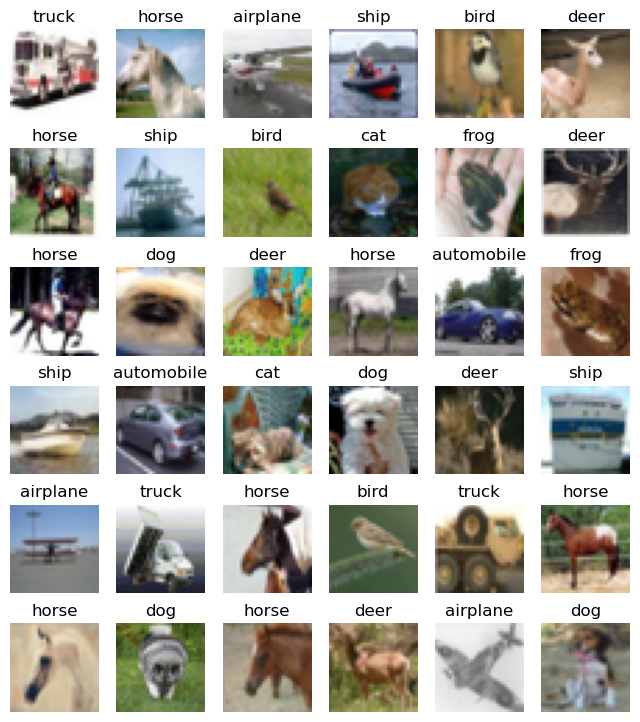

In [16]:
train_dataset = CIFAR10(
    root=cifar10_path,
    train=True,
    download=False,
    transform=transforms.Compose(
        [
            transforms.ToImage(),
            transforms.ToDtype(torch.float32, scale=True),
            transforms.Resize((32, 32)),
            transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
        ]
    ),
)

val_dataset = CIFAR10(
    root=cifar10_path,
    train=False,
    download=False,
    transform=transforms.Compose(
        [
            transforms.ToImage(),
            transforms.ToDtype(torch.float32, scale=True),
            transforms.Resize((32, 32)),
            transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
        ]
    ),
)

train_loader = DataLoader(
    train_dataset, batch_size=128, shuffle=True, num_workers=1, pin_memory=True
)
val_loader = DataLoader(
    val_dataset, batch_size=128, shuffle=False, num_workers=1, pin_memory=True
)

plot_dataset(train_dataset, n_cols=6, n_rows=6, denormalize=True, figsize=(8, 9), label_decoder=label_mapper)

In [17]:
epochs = 64
latent_dim = 128
num_classes = 10
dataset_dim = 3
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

generator = Generator(latent_dim, output_dim=dataset_dim, n_classes=num_classes)
discriminator = Discriminator(in_channels=dataset_dim, n_classes=num_classes)

g_optimizer = torch.optim.Adam(generator.parameters(), lr=0.0002, betas=(0.5, 0.999))
d_optimizer = torch.optim.Adam(
    discriminator.parameters(), lr=0.0002, betas=(0.5, 0.999)
)
criterion = nn.BCELoss()

  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 1/64]
	G_Trn_Loss: 1.3096	D_Trn_Loss: 1.2986	D_Trn_Real: 0.4512	D_Trn_Fake: 0.6901	D_Trn_Acc: 67.83% 
	G_Val_Loss: 1.2117	D_Val_Loss: 1.2767	D_Val_Real: 0.4512	D_Val_Fake: 0.6901	D_Val_Acc: 69.72%


  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 2/64]
	G_Trn_Loss: 1.7827	D_Trn_Loss: 1.0468	D_Trn_Real: 0.6034	D_Trn_Fake: 0.6295	D_Trn_Acc: 79.26% 
	G_Val_Loss: 1.0239	D_Val_Loss: 1.0450	D_Val_Real: 0.6034	D_Val_Fake: 0.6295	D_Val_Acc: 82.37%


  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 3/64]
	G_Trn_Loss: 1.9704	D_Trn_Loss: 0.9214	D_Trn_Real: 0.5937	D_Trn_Fake: 0.6109	D_Trn_Acc: 83.42% 
	G_Val_Loss: 0.9813	D_Val_Loss: 1.1365	D_Val_Real: 0.5937	D_Val_Fake: 0.6109	D_Val_Acc: 74.26%


  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 4/64]
	G_Trn_Loss: 2.2053	D_Trn_Loss: 0.8234	D_Trn_Real: 0.5446	D_Trn_Fake: 0.7025	D_Trn_Acc: 86.44% 
	G_Val_Loss: 1.3238	D_Val_Loss: 1.1404	D_Val_Real: 0.5446	D_Val_Fake: 0.7025	D_Val_Acc: 78.72%


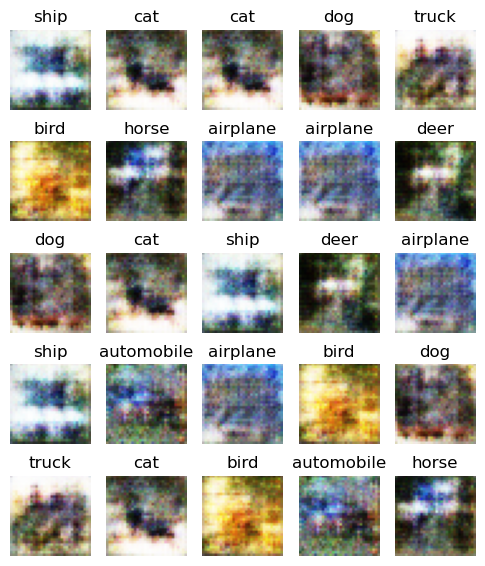

  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 5/64]
	G_Trn_Loss: 2.2953	D_Trn_Loss: 0.7973	D_Trn_Real: 0.6119	D_Trn_Fake: 0.7608	D_Trn_Acc: 87.08% 
	G_Val_Loss: 1.4839	D_Val_Loss: 0.9207	D_Val_Real: 0.6119	D_Val_Fake: 0.7608	D_Val_Acc: 83.80%


  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 6/64]
	G_Trn_Loss: 2.4602	D_Trn_Loss: 0.7193	D_Trn_Real: 0.6161	D_Trn_Fake: 0.8177	D_Trn_Acc: 88.73% 
	G_Val_Loss: 1.7526	D_Val_Loss: 0.8078	D_Val_Real: 0.6161	D_Val_Fake: 0.8177	D_Val_Acc: 83.31%


  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 7/64]
	G_Trn_Loss: 2.5811	D_Trn_Loss: 0.7040	D_Trn_Real: 0.6885	D_Trn_Fake: 0.6898	D_Trn_Acc: 88.75% 
	G_Val_Loss: 1.2532	D_Val_Loss: 0.8454	D_Val_Real: 0.6885	D_Val_Fake: 0.6898	D_Val_Acc: 89.22%


  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 8/64]
	G_Trn_Loss: 2.5377	D_Trn_Loss: 0.7319	D_Trn_Real: 0.6526	D_Trn_Fake: 0.6873	D_Trn_Acc: 88.04% 
	G_Val_Loss: 1.3097	D_Val_Loss: 0.9540	D_Val_Real: 0.6526	D_Val_Fake: 0.6873	D_Val_Acc: 78.16%


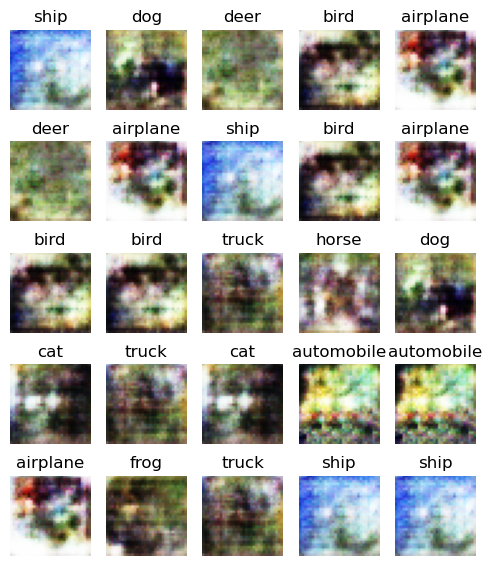

  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 9/64]
	G_Trn_Loss: 2.5903	D_Trn_Loss: 0.7227	D_Trn_Real: 0.7382	D_Trn_Fake: 0.8244	D_Trn_Acc: 88.03% 
	G_Val_Loss: 1.7831	D_Val_Loss: 0.6075	D_Val_Real: 0.7382	D_Val_Fake: 0.8244	D_Val_Acc: 90.42%


  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 10/64]
	G_Trn_Loss: 2.6273	D_Trn_Loss: 0.7311	D_Trn_Real: 0.6634	D_Trn_Fake: 0.7490	D_Trn_Acc: 87.66% 
	G_Val_Loss: 1.9297	D_Val_Loss: 0.8636	D_Val_Real: 0.6634	D_Val_Fake: 0.7490	D_Val_Acc: 80.91%


  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 11/64]
	G_Trn_Loss: 2.6238	D_Trn_Loss: 0.7091	D_Trn_Real: 0.5033	D_Trn_Fake: 0.8850	D_Trn_Acc: 88.31% 
	G_Val_Loss: 2.2427	D_Val_Loss: 1.0915	D_Val_Real: 0.5033	D_Val_Fake: 0.8850	D_Val_Acc: 75.30%


  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 12/64]
	G_Trn_Loss: 2.7260	D_Trn_Loss: 0.6861	D_Trn_Real: 0.7518	D_Trn_Fake: 0.6547	D_Trn_Acc: 88.32% 
	G_Val_Loss: 1.1015	D_Val_Loss: 0.7875	D_Val_Real: 0.7518	D_Val_Fake: 0.6547	D_Val_Acc: 90.18%


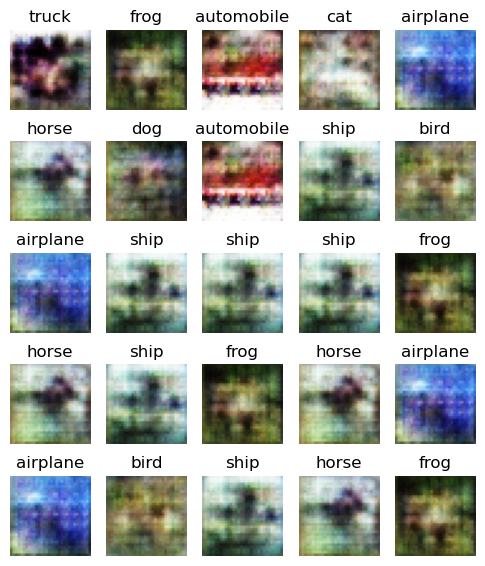

  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 13/64]
	G_Trn_Loss: 2.8488	D_Trn_Loss: 0.6599	D_Trn_Real: 0.7088	D_Trn_Fake: 0.7718	D_Trn_Acc: 88.94% 
	G_Val_Loss: 1.7150	D_Val_Loss: 0.7129	D_Val_Real: 0.7088	D_Val_Fake: 0.7718	D_Val_Acc: 88.81%


  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 14/64]
	G_Trn_Loss: 2.8495	D_Trn_Loss: 0.6347	D_Trn_Real: 0.7678	D_Trn_Fake: 0.6901	D_Trn_Acc: 89.30% 
	G_Val_Loss: 1.3735	D_Val_Loss: 0.7551	D_Val_Real: 0.7678	D_Val_Fake: 0.6901	D_Val_Acc: 83.86%


  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 15/64]
	G_Trn_Loss: 2.7514	D_Trn_Loss: 0.6496	D_Trn_Real: 0.6129	D_Trn_Fake: 0.7766	D_Trn_Acc: 88.75% 
	G_Val_Loss: 1.6141	D_Val_Loss: 0.9772	D_Val_Real: 0.6129	D_Val_Fake: 0.7766	D_Val_Acc: 81.56%


  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 16/64]
	G_Trn_Loss: 2.8261	D_Trn_Loss: 0.6483	D_Trn_Real: 0.7296	D_Trn_Fake: 0.8117	D_Trn_Acc: 88.43% 
	G_Val_Loss: 1.9409	D_Val_Loss: 0.6538	D_Val_Real: 0.7296	D_Val_Fake: 0.8117	D_Val_Acc: 87.31%


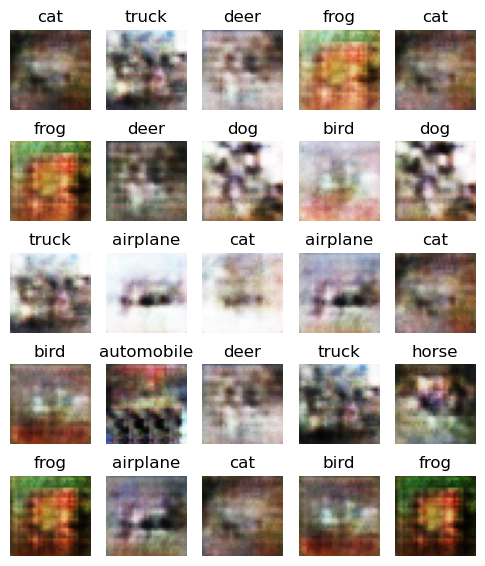

  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 17/64]
	G_Trn_Loss: 2.9035	D_Trn_Loss: 0.6186	D_Trn_Real: 0.8027	D_Trn_Fake: 0.7349	D_Trn_Acc: 89.18% 
	G_Val_Loss: 1.6960	D_Val_Loss: 0.6513	D_Val_Real: 0.8027	D_Val_Fake: 0.7349	D_Val_Acc: 85.57%


  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 18/64]
	G_Trn_Loss: 2.9880	D_Trn_Loss: 0.6086	D_Trn_Real: 0.6140	D_Trn_Fake: 0.8892	D_Trn_Acc: 89.28% 
	G_Val_Loss: 3.4174	D_Val_Loss: 0.8718	D_Val_Real: 0.6140	D_Val_Fake: 0.8892	D_Val_Acc: 81.79%


  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 19/64]
	G_Trn_Loss: 2.9734	D_Trn_Loss: 0.6015	D_Trn_Real: 0.7742	D_Trn_Fake: 0.7742	D_Trn_Acc: 89.54% 
	G_Val_Loss: 1.6550	D_Val_Loss: 0.5987	D_Val_Real: 0.7742	D_Val_Fake: 0.7742	D_Val_Acc: 92.17%


  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 20/64]
	G_Trn_Loss: 3.0276	D_Trn_Loss: 0.6168	D_Trn_Real: 0.6713	D_Trn_Fake: 0.8349	D_Trn_Acc: 88.50% 
	G_Val_Loss: 2.1289	D_Val_Loss: 0.7379	D_Val_Real: 0.6713	D_Val_Fake: 0.8349	D_Val_Acc: 85.12%


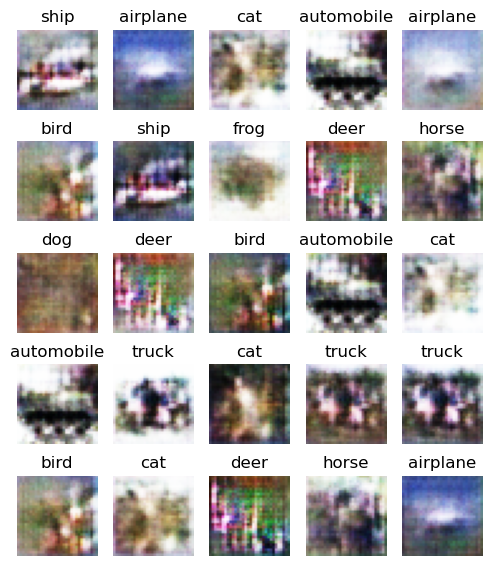

  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 21/64]
	G_Trn_Loss: 2.9483	D_Trn_Loss: 0.5887	D_Trn_Real: 0.6162	D_Trn_Fake: 0.8794	D_Trn_Acc: 89.92% 
	G_Val_Loss: 2.3173	D_Val_Loss: 0.7912	D_Val_Real: 0.6162	D_Val_Fake: 0.8794	D_Val_Acc: 83.40%


  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 22/64]
	G_Trn_Loss: 3.0841	D_Trn_Loss: 0.5603	D_Trn_Real: 0.5278	D_Trn_Fake: 0.8626	D_Trn_Acc: 90.19% 
	G_Val_Loss: 2.3558	D_Val_Loss: 1.0663	D_Val_Real: 0.5278	D_Val_Fake: 0.8626	D_Val_Acc: 76.38%


  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 23/64]
	G_Trn_Loss: 3.1214	D_Trn_Loss: 0.5775	D_Trn_Real: 0.6550	D_Trn_Fake: 0.8361	D_Trn_Acc: 89.90% 
	G_Val_Loss: 2.0429	D_Val_Loss: 0.7940	D_Val_Real: 0.6550	D_Val_Fake: 0.8361	D_Val_Acc: 85.00%


  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 24/64]
	G_Trn_Loss: 3.0663	D_Trn_Loss: 0.5862	D_Trn_Real: 0.6421	D_Trn_Fake: 0.7216	D_Trn_Acc: 89.37% 
	G_Val_Loss: 1.5902	D_Val_Loss: 1.0982	D_Val_Real: 0.6421	D_Val_Fake: 0.7216	D_Val_Acc: 77.10%


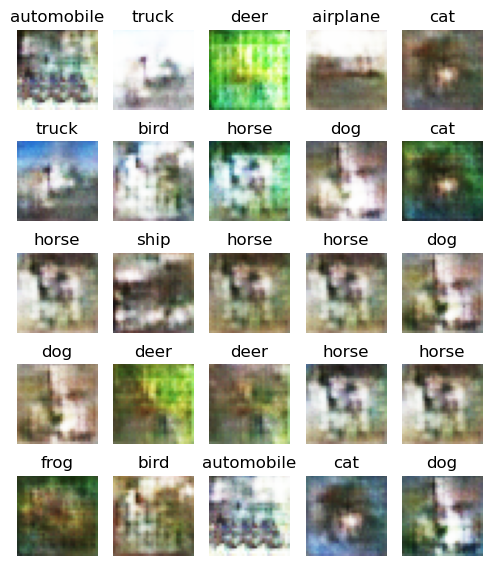

  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 25/64]
	G_Trn_Loss: 3.1381	D_Trn_Loss: 0.5574	D_Trn_Real: 0.6836	D_Trn_Fake: 0.7931	D_Trn_Acc: 90.13% 
	G_Val_Loss: 2.1307	D_Val_Loss: 0.7920	D_Val_Real: 0.6836	D_Val_Fake: 0.7931	D_Val_Acc: 85.16%


  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 26/64]
	G_Trn_Loss: 3.0758	D_Trn_Loss: 0.5796	D_Trn_Real: 0.6520	D_Trn_Fake: 0.8456	D_Trn_Acc: 89.36% 
	G_Val_Loss: 2.1922	D_Val_Loss: 0.8018	D_Val_Real: 0.6520	D_Val_Fake: 0.8456	D_Val_Acc: 83.64%


  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 27/64]
	G_Trn_Loss: 3.1465	D_Trn_Loss: 0.5749	D_Trn_Real: 0.7082	D_Trn_Fake: 0.5224	D_Trn_Acc: 89.64% 
	G_Val_Loss: 0.8930	D_Val_Loss: 1.2496	D_Val_Real: 0.7082	D_Val_Fake: 0.5224	D_Val_Acc: 66.19%


  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 28/64]
	G_Trn_Loss: 3.1827	D_Trn_Loss: 0.5436	D_Trn_Real: 0.7518	D_Trn_Fake: 0.8137	D_Trn_Acc: 90.21% 
	G_Val_Loss: 1.9280	D_Val_Loss: 0.5775	D_Val_Real: 0.7518	D_Val_Fake: 0.8137	D_Val_Acc: 91.74%


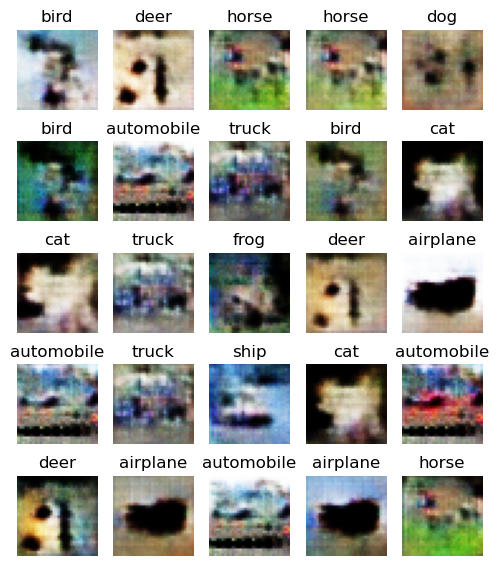

  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 29/64]
	G_Trn_Loss: 3.0836	D_Trn_Loss: 0.6034	D_Trn_Real: 0.6585	D_Trn_Fake: 0.8729	D_Trn_Acc: 88.67% 
	G_Val_Loss: 2.4818	D_Val_Loss: 0.7632	D_Val_Real: 0.6585	D_Val_Fake: 0.8729	D_Val_Acc: 84.13%


  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 30/64]
	G_Trn_Loss: 3.1118	D_Trn_Loss: 0.5622	D_Trn_Real: 0.7013	D_Trn_Fake: 0.8849	D_Trn_Acc: 89.88% 
	G_Val_Loss: 2.5628	D_Val_Loss: 0.6275	D_Val_Real: 0.7013	D_Val_Fake: 0.8849	D_Val_Acc: 88.24%


  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 31/64]
	G_Trn_Loss: 3.1176	D_Trn_Loss: 0.5508	D_Trn_Real: 0.7720	D_Trn_Fake: 0.6884	D_Trn_Acc: 90.32% 
	G_Val_Loss: 1.5103	D_Val_Loss: 0.7956	D_Val_Real: 0.7720	D_Val_Fake: 0.6884	D_Val_Acc: 83.14%


  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 32/64]
	G_Trn_Loss: 3.3038	D_Trn_Loss: 0.5160	D_Trn_Real: 0.6193	D_Trn_Fake: 0.8496	D_Trn_Acc: 90.57% 
	G_Val_Loss: 2.1566	D_Val_Loss: 0.8618	D_Val_Real: 0.6193	D_Val_Fake: 0.8496	D_Val_Acc: 82.05%


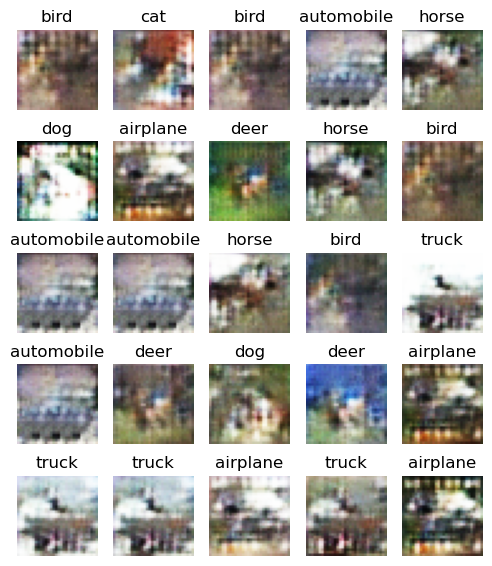

  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 33/64]
	G_Trn_Loss: 3.1953	D_Trn_Loss: 0.5539	D_Trn_Real: 0.6596	D_Trn_Fake: 0.8601	D_Trn_Acc: 89.90% 
	G_Val_Loss: 2.3279	D_Val_Loss: 0.7715	D_Val_Real: 0.6596	D_Val_Fake: 0.8601	D_Val_Acc: 85.37%


  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 34/64]
	G_Trn_Loss: 3.1752	D_Trn_Loss: 0.5505	D_Trn_Real: 0.7346	D_Trn_Fake: 0.7671	D_Trn_Acc: 90.10% 
	G_Val_Loss: 1.7647	D_Val_Loss: 0.7264	D_Val_Real: 0.7346	D_Val_Fake: 0.7671	D_Val_Acc: 86.22%


  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 35/64]
	G_Trn_Loss: 3.3380	D_Trn_Loss: 0.4948	D_Trn_Real: 0.7502	D_Trn_Fake: 0.7820	D_Trn_Acc: 91.41% 
	G_Val_Loss: 1.7966	D_Val_Loss: 0.6766	D_Val_Real: 0.7502	D_Val_Fake: 0.7820	D_Val_Acc: 89.07%


  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 36/64]
	G_Trn_Loss: 3.3253	D_Trn_Loss: 0.5012	D_Trn_Real: 0.7849	D_Trn_Fake: 0.8038	D_Trn_Acc: 91.32% 
	G_Val_Loss: 1.8403	D_Val_Loss: 0.5649	D_Val_Real: 0.7849	D_Val_Fake: 0.8038	D_Val_Acc: 91.35%


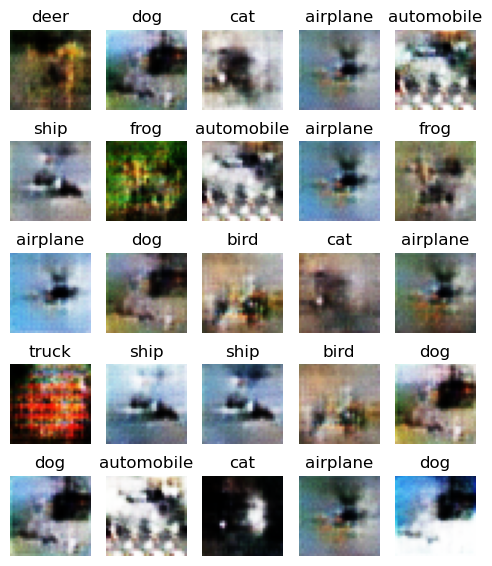

  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 37/64]
	G_Trn_Loss: 3.3244	D_Trn_Loss: 0.5140	D_Trn_Real: 0.6440	D_Trn_Fake: 0.8257	D_Trn_Acc: 90.74% 
	G_Val_Loss: 2.1471	D_Val_Loss: 0.8521	D_Val_Real: 0.6440	D_Val_Fake: 0.8257	D_Val_Acc: 84.07%


  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 38/64]
	G_Trn_Loss: 3.2790	D_Trn_Loss: 0.5129	D_Trn_Real: 0.7508	D_Trn_Fake: 0.7388	D_Trn_Acc: 90.94% 
	G_Val_Loss: 1.7992	D_Val_Loss: 0.7546	D_Val_Real: 0.7508	D_Val_Fake: 0.7388	D_Val_Acc: 84.38%


  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 39/64]
	G_Trn_Loss: 3.4469	D_Trn_Loss: 0.4711	D_Trn_Real: 0.6208	D_Trn_Fake: 0.8692	D_Trn_Acc: 91.90% 
	G_Val_Loss: 2.4827	D_Val_Loss: 0.8217	D_Val_Real: 0.6208	D_Val_Fake: 0.8692	D_Val_Acc: 82.32%


  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 40/64]
	G_Trn_Loss: 3.4288	D_Trn_Loss: 0.4379	D_Trn_Real: 0.7125	D_Trn_Fake: 0.8977	D_Trn_Acc: 92.72% 
	G_Val_Loss: 3.0316	D_Val_Loss: 0.6354	D_Val_Real: 0.7125	D_Val_Fake: 0.8977	D_Val_Acc: 86.63%


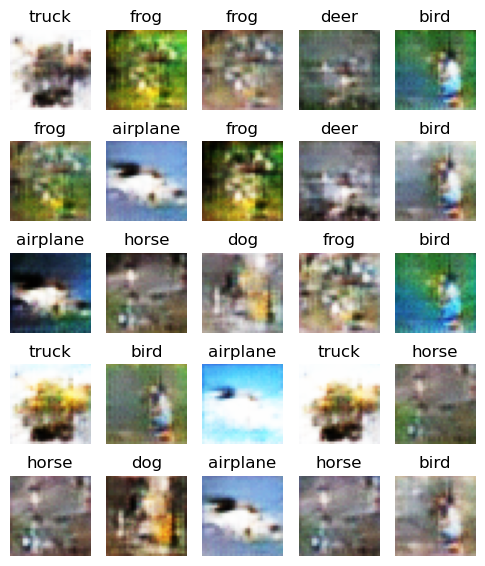

  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 41/64]
	G_Trn_Loss: 3.6037	D_Trn_Loss: 0.4168	D_Trn_Real: 0.7654	D_Trn_Fake: 0.9375	D_Trn_Acc: 93.13% 
	G_Val_Loss: 3.5648	D_Val_Loss: 0.4750	D_Val_Real: 0.7654	D_Val_Fake: 0.9375	D_Val_Acc: 90.97%


  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 42/64]
	G_Trn_Loss: 3.5347	D_Trn_Loss: 0.4578	D_Trn_Real: 0.7657	D_Trn_Fake: 0.7560	D_Trn_Acc: 91.82% 
	G_Val_Loss: 1.6993	D_Val_Loss: 0.6821	D_Val_Real: 0.7657	D_Val_Fake: 0.7560	D_Val_Acc: 87.77%


  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 43/64]
	G_Trn_Loss: 3.5001	D_Trn_Loss: 0.4517	D_Trn_Real: 0.8391	D_Trn_Fake: 0.7756	D_Trn_Acc: 92.34% 
	G_Val_Loss: 1.7274	D_Val_Loss: 0.5364	D_Val_Real: 0.8391	D_Val_Fake: 0.7756	D_Val_Acc: 92.11%


  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 44/64]
	G_Trn_Loss: 3.6407	D_Trn_Loss: 0.4480	D_Trn_Real: 0.7421	D_Trn_Fake: 0.7974	D_Trn_Acc: 92.12% 
	G_Val_Loss: 1.9077	D_Val_Loss: 0.6911	D_Val_Real: 0.7421	D_Val_Fake: 0.7974	D_Val_Acc: 87.57%


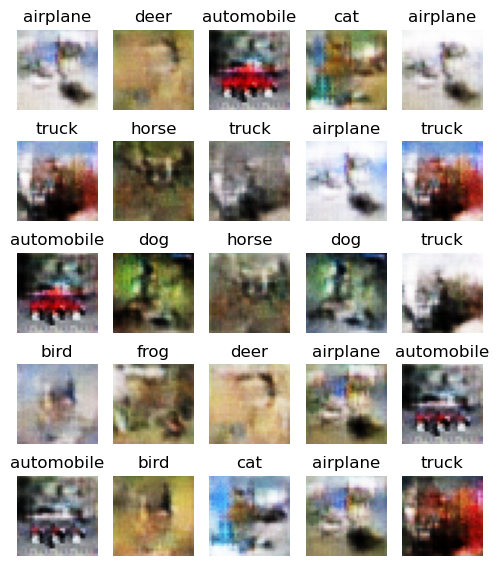

  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 45/64]
	G_Trn_Loss: 3.5012	D_Trn_Loss: 0.4482	D_Trn_Real: 0.7123	D_Trn_Fake: 0.8297	D_Trn_Acc: 92.19% 
	G_Val_Loss: 2.1276	D_Val_Loss: 0.7010	D_Val_Real: 0.7123	D_Val_Fake: 0.8297	D_Val_Acc: 86.79%


  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 46/64]
	G_Trn_Loss: 3.7437	D_Trn_Loss: 0.4077	D_Trn_Real: 0.6358	D_Trn_Fake: 0.9032	D_Trn_Acc: 93.05% 
	G_Val_Loss: 2.9526	D_Val_Loss: 0.8087	D_Val_Real: 0.6358	D_Val_Fake: 0.9032	D_Val_Acc: 83.48%


  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 47/64]
	G_Trn_Loss: 3.7134	D_Trn_Loss: 0.4273	D_Trn_Real: 0.6798	D_Trn_Fake: 0.7819	D_Trn_Acc: 92.85% 
	G_Val_Loss: 2.1607	D_Val_Loss: 0.8750	D_Val_Real: 0.6798	D_Val_Fake: 0.7819	D_Val_Acc: 81.20%


  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 48/64]
	G_Trn_Loss: 3.7382	D_Trn_Loss: 0.3956	D_Trn_Real: 0.6740	D_Trn_Fake: 0.8664	D_Trn_Acc: 93.34% 
	G_Val_Loss: 2.5313	D_Val_Loss: 0.7413	D_Val_Real: 0.6740	D_Val_Fake: 0.8664	D_Val_Acc: 84.59%


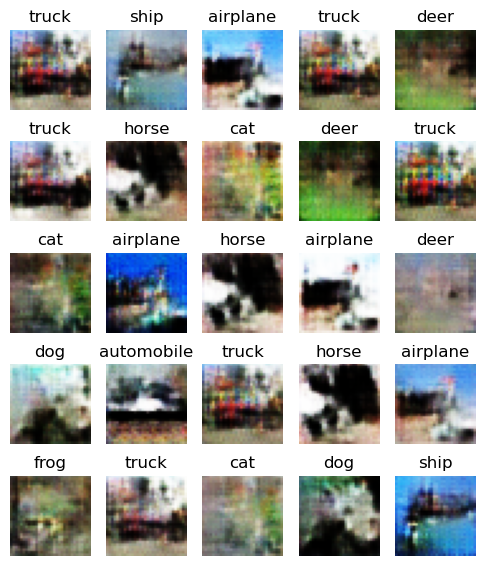

  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 49/64]
	G_Trn_Loss: 3.6735	D_Trn_Loss: 0.3999	D_Trn_Real: 0.6101	D_Trn_Fake: 0.9288	D_Trn_Acc: 93.39% 
	G_Val_Loss: 3.0777	D_Val_Loss: 0.8368	D_Val_Real: 0.6101	D_Val_Fake: 0.9288	D_Val_Acc: 82.12%


  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 50/64]
	G_Trn_Loss: 3.7406	D_Trn_Loss: 0.3790	D_Trn_Real: 0.6885	D_Trn_Fake: 0.9278	D_Trn_Acc: 93.73% 
	G_Val_Loss: 3.1367	D_Val_Loss: 0.6164	D_Val_Real: 0.6885	D_Val_Fake: 0.9278	D_Val_Acc: 87.34%


  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 51/64]
	G_Trn_Loss: 3.8051	D_Trn_Loss: 0.3734	D_Trn_Real: 0.7751	D_Trn_Fake: 0.8129	D_Trn_Acc: 93.86% 
	G_Val_Loss: 2.0205	D_Val_Loss: 0.5829	D_Val_Real: 0.7751	D_Val_Fake: 0.8129	D_Val_Acc: 90.29%


  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 52/64]
	G_Trn_Loss: 3.9161	D_Trn_Loss: 0.3435	D_Trn_Real: 0.7926	D_Trn_Fake: 0.7902	D_Trn_Acc: 94.57% 
	G_Val_Loss: 1.9568	D_Val_Loss: 0.6180	D_Val_Real: 0.7926	D_Val_Fake: 0.7902	D_Val_Acc: 88.10%


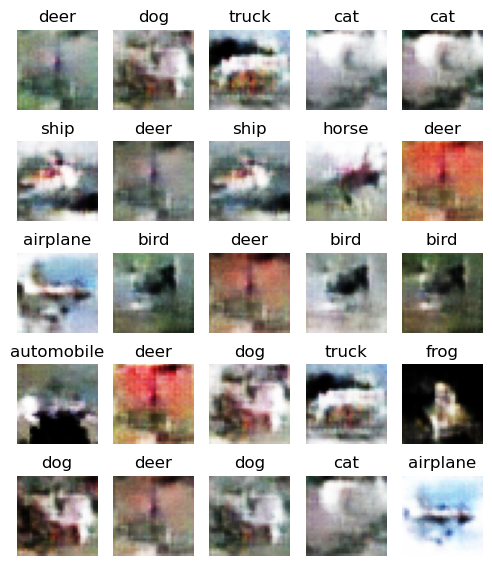

  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 53/64]
	G_Trn_Loss: 4.1011	D_Trn_Loss: 0.3354	D_Trn_Real: 0.7150	D_Trn_Fake: 0.8853	D_Trn_Acc: 94.26% 
	G_Val_Loss: 2.7473	D_Val_Loss: 0.6271	D_Val_Real: 0.7150	D_Val_Fake: 0.8853	D_Val_Acc: 87.59%


  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 54/64]
	G_Trn_Loss: 3.8991	D_Trn_Loss: 0.3608	D_Trn_Real: 0.6790	D_Trn_Fake: 0.8335	D_Trn_Acc: 94.14% 
	G_Val_Loss: 2.4263	D_Val_Loss: 0.7625	D_Val_Real: 0.6790	D_Val_Fake: 0.8335	D_Val_Acc: 84.77%


  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 55/64]
	G_Trn_Loss: 3.9622	D_Trn_Loss: 0.3648	D_Trn_Real: 0.8106	D_Trn_Fake: 0.8278	D_Trn_Acc: 93.62% 
	G_Val_Loss: 2.2031	D_Val_Loss: 0.4969	D_Val_Real: 0.8106	D_Val_Fake: 0.8278	D_Val_Acc: 91.89%


  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 56/64]
	G_Trn_Loss: 4.1165	D_Trn_Loss: 0.3330	D_Trn_Real: 0.6695	D_Trn_Fake: 0.8840	D_Trn_Acc: 94.51% 
	G_Val_Loss: 2.4874	D_Val_Loss: 0.7058	D_Val_Real: 0.6695	D_Val_Fake: 0.8840	D_Val_Acc: 85.64%


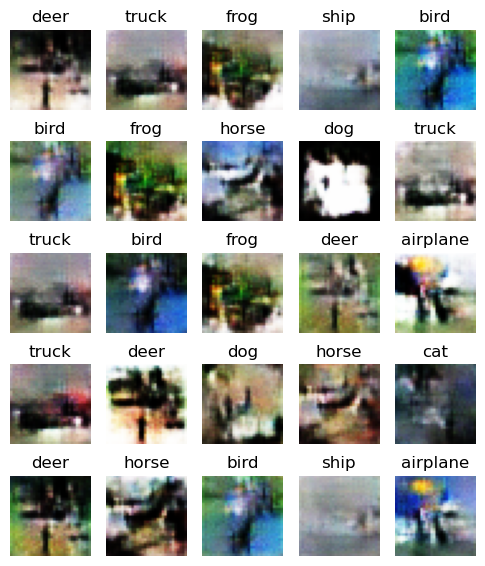

  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 57/64]
	G_Trn_Loss: 4.1782	D_Trn_Loss: 0.3423	D_Trn_Real: 0.6748	D_Trn_Fake: 0.8362	D_Trn_Acc: 94.35% 
	G_Val_Loss: 2.1214	D_Val_Loss: 0.7881	D_Val_Real: 0.6748	D_Val_Fake: 0.8362	D_Val_Acc: 84.98%


  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 58/64]
	G_Trn_Loss: 4.0014	D_Trn_Loss: 0.3808	D_Trn_Real: 0.7100	D_Trn_Fake: 0.7812	D_Trn_Acc: 93.42% 
	G_Val_Loss: 2.3951	D_Val_Loss: 0.8005	D_Val_Real: 0.7100	D_Val_Fake: 0.7812	D_Val_Acc: 83.92%


  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 59/64]
	G_Trn_Loss: 3.8444	D_Trn_Loss: 0.3724	D_Trn_Real: 0.7134	D_Trn_Fake: 0.8148	D_Trn_Acc: 93.71% 
	G_Val_Loss: 2.1759	D_Val_Loss: 0.7499	D_Val_Real: 0.7134	D_Val_Fake: 0.8148	D_Val_Acc: 86.38%


  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 60/64]
	G_Trn_Loss: 3.9483	D_Trn_Loss: 0.3966	D_Trn_Real: 0.7207	D_Trn_Fake: 0.9014	D_Trn_Acc: 93.12% 
	G_Val_Loss: 2.7533	D_Val_Loss: 0.5944	D_Val_Real: 0.7207	D_Val_Fake: 0.9014	D_Val_Acc: 88.25%


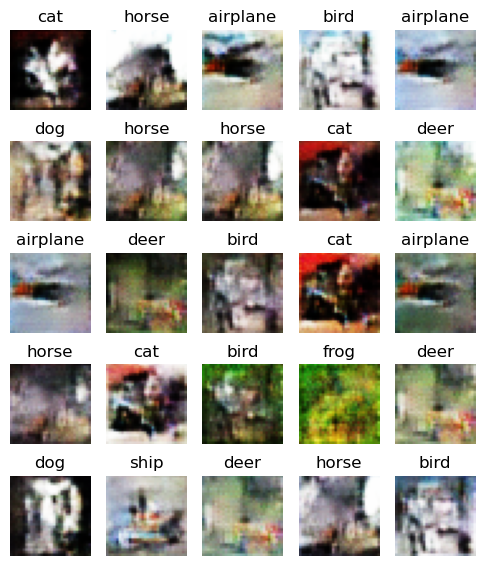

  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 61/64]
	G_Trn_Loss: 4.0377	D_Trn_Loss: 0.3869	D_Trn_Real: 0.5705	D_Trn_Fake: 0.8919	D_Trn_Acc: 93.18% 
	G_Val_Loss: 2.5826	D_Val_Loss: 0.9741	D_Val_Real: 0.5705	D_Val_Fake: 0.8919	D_Val_Acc: 79.23%


  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 62/64]
	G_Trn_Loss: 4.0359	D_Trn_Loss: 0.4221	D_Trn_Real: 0.7746	D_Trn_Fake: 0.8183	D_Trn_Acc: 92.49% 
	G_Val_Loss: 2.0363	D_Val_Loss: 0.5711	D_Val_Real: 0.7746	D_Val_Fake: 0.8183	D_Val_Acc: 90.86%


  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 63/64]
	G_Trn_Loss: 3.8172	D_Trn_Loss: 0.4181	D_Trn_Real: 0.6823	D_Trn_Fake: 0.9111	D_Trn_Acc: 92.57% 
	G_Val_Loss: 2.8453	D_Val_Loss: 0.6550	D_Val_Real: 0.6823	D_Val_Fake: 0.9111	D_Val_Acc: 86.31%


  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 64/64]
	G_Trn_Loss: 3.9314	D_Trn_Loss: 0.3709	D_Trn_Real: 0.5750	D_Trn_Fake: 0.8580	D_Trn_Acc: 93.89% 
	G_Val_Loss: 2.2375	D_Val_Loss: 1.0302	D_Val_Real: 0.5750	D_Val_Fake: 0.8580	D_Val_Acc: 78.67%


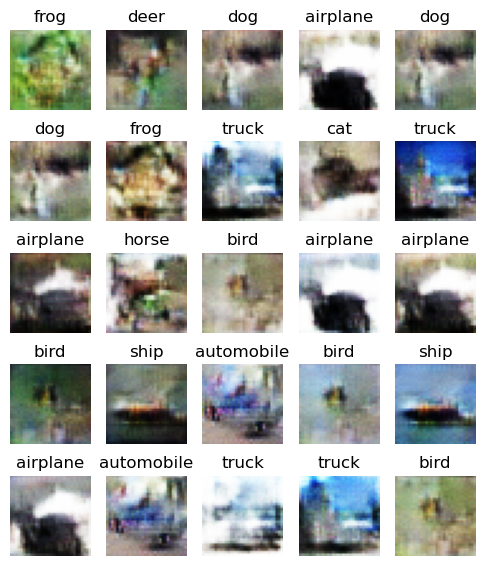

In [50]:
train_stats, val_stats = train(
    generator,
    discriminator,
    train_loader,
    val_loader,
    g_optimizer,
    d_optimizer,
    criterion,
    device,
    epochs=epochs,
    plot_frequency=4,
    label_mapper=label_mapper,
)

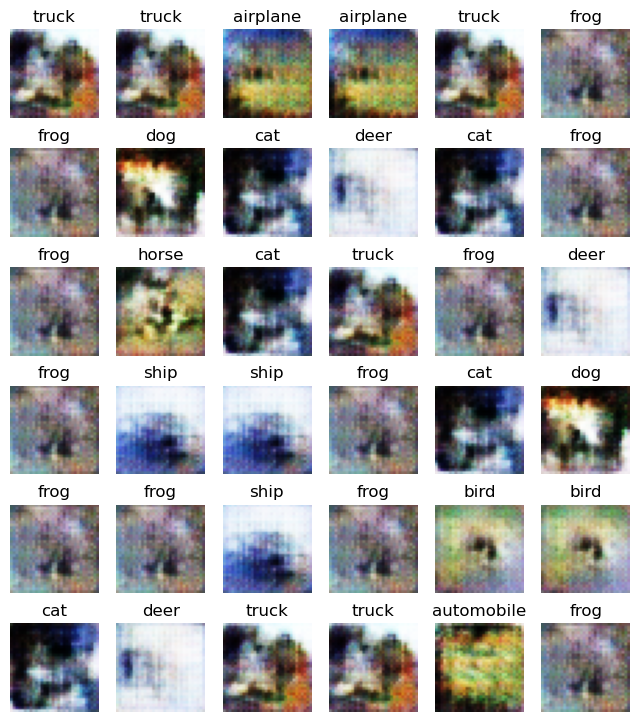

In [46]:
plot_generated_images(
    generator,
    device=device,
    num_images=36,
    denormalize=True,
    figsize=(8, 9),
    label_decoder=label_mapper,
    num_classes=10,
)

# Exercícios


## Exercício 1

Vamos explorar a função do embedding no gerador. Experimente alterar o tamanho do embedding e o treine com o dataset que preferir. Experimente também remover o embedding do gerador substituindo-o por um OneHotEncoding.

<details>
<summary>Dica:</summary>

Inclua um parâmetro `embedding_size` no construtor do gerador. Utilize o parâmetro para definir o tamanho do embedding.

</details>


Number of samples: 50000
Sample shape: torch.Size([3, 32, 32])


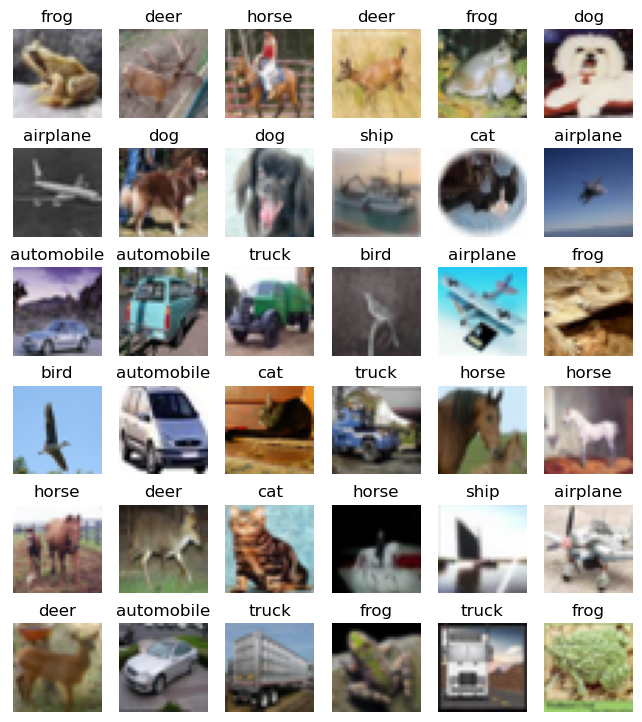

In [18]:
train_dataset = CIFAR10(
    root=cifar10_path,
    train=True,
    download=False,
    transform=transforms.Compose(
        [
            transforms.ToImage(),
            transforms.ToDtype(torch.float32, scale=True),
            transforms.Resize((32, 32)),
            transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
        ]
    ),
)

val_dataset = CIFAR10(
    root=cifar10_path,
    train=False,
    download=False,
    transform=transforms.Compose(
        [
            transforms.ToImage(),
            transforms.ToDtype(torch.float32, scale=True),
            transforms.Resize((32, 32)),
            transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
        ]
    ),
)

train_loader = DataLoader(
    train_dataset, batch_size=128, shuffle=True, num_workers=1, pin_memory=True
)
val_loader = DataLoader(
    val_dataset, batch_size=128, shuffle=False, num_workers=1, pin_memory=True
)

plot_dataset(train_dataset, n_cols=6, n_rows=6, denormalize=True, figsize=(8, 9), label_decoder=label_mapper)

### Embedding Variável

In [19]:
class EmbeddingGenerator(nn.Module):
    def __init__(self, latent_size=128, embedding_size=128, n_classes=10, output_dim=3, arch='large'):
        super(EmbeddingGenerator, self).__init__()

        # latent_size is the size of the input noise vector
        self.latent_size = latent_size
        self.embedding_size = embedding_size
        self.embedding = nn.Sequential(
            nn.Embedding(n_classes, embedding_size), 
            nn.Unflatten(1, (embedding_size, 1, 1))
        )

        self.net = nn.Sequential(
            nn.ConvTranspose2d(latent_size + embedding_size, 512, kernel_size=4, stride=1, bias=False),  # (512, 4, 4)
            nn.BatchNorm2d(512),
            nn.GELU(),
            nn.ConvTranspose2d(512, 256, kernel_size=4, stride=2, padding=1, bias=False),  # (256, 8, 8)
            nn.BatchNorm2d(256),
            nn.GELU(),
            nn.ConvTranspose2d(256, 128, kernel_size=4, stride=2, padding=1, bias=False),  # (128, 16, 16)
            nn.BatchNorm2d(128),
            nn.GELU(),
            nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1, bias=False),  # (64, 32, 32)
            nn.BatchNorm2d(64),
            nn.GELU(),
        ) 
        
        if arch == 'large':
            self.net.append(nn.ConvTranspose2d(64, output_dim, kernel_size=4, stride=2, padding=1, bias=False))  # (output_dim, 64, 64)
        else:
            self.net.append(nn.Conv2d(64, output_dim, kernel_size=3, stride=1, padding=1, bias=False))  # (output_dim, 32, 32)
        
        self.net.append(nn.Tanh())

    def forward(self, y, x=None, batch_size=1):
        if x is None:
            device = next(self.parameters()).device
            x = torch.randn(batch_size, self.latent_size, 1, 1, device=device)
        elif batch_size > 1:
            print('Warning: changing batch_size with x is not supported, the batch size will be the size of x')
        
        y = self.embedding(y)
        
        return self.net(torch.cat([x, y], dim=1))

In [20]:
class EmbeddingDiscriminator(nn.Module):
    def __init__(self, in_channels=3, n_classes=10, embedding_size=128, arch='large'):
        super(EmbeddingDiscriminator, self).__init__()

        self.embedding = nn.Sequential(
            nn.Embedding(n_classes, embedding_size),
            nn.Linear(embedding_size, 64*64 if arch == 'large' else 32*32),
            nn.LeakyReLU(0.2),
            nn.Unflatten(1, (1, 64, 64) if arch == 'large' else (1, 32, 32))
        )

        self.net = nn.Sequential(
            nn.Conv2d(in_channels+1, 64, kernel_size=4, stride=2, padding=1, bias=False), # (64, 32, 32) / (64, 16, 16)
            nn.BatchNorm2d(64),
            nn.LeakyReLU(0.2),
            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1, bias=False),  # (128, 16, 16) / (128, 8, 8)
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2),
            nn.Conv2d(128, 256, kernel_size=4, stride=2, padding=1, bias=False),  # (256, 8, 8) / (256, 4, 4)
            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2),
        )

        if arch == 'large':
            self.net.append(nn.Conv2d(256, 512, kernel_size=4, stride=2, padding=1, bias=False)) # (512, 4, 4)
            self.net.append(nn.BatchNorm2d(512))
            self.net.append(nn.LeakyReLU(0.2))
            self.net.append(nn.Conv2d(512, 1, kernel_size=4, bias=False)) # (1, 1, 1)
        else:
            self.net.append(nn.Conv2d(256, 1, kernel_size=4, bias=False)) # (1, 1, 1)
        
        self.net.append(nn.Flatten())
        self.net.append(nn.Sigmoid())

    def forward(self, x, y):
        y = self.embedding(y)
        return self.net(torch.cat([x, y], dim=1))

In [22]:
epochs = 32
latent_dim = 128
num_classes = 10
dataset_dim = 3
embedding_size = 32
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

generator = EmbeddingGenerator(latent_dim, n_classes=num_classes, embedding_size=embedding_size, output_dim=dataset_dim, arch='small')
discriminator = EmbeddingDiscriminator(in_channels=dataset_dim, n_classes=num_classes, embedding_size=embedding_size, arch='small')

g_optimizer = torch.optim.Adam(generator.parameters(), lr=0.0002, betas=(0.5, 0.999))
d_optimizer = torch.optim.Adam(
    discriminator.parameters(), lr=0.0002, betas=(0.5, 0.999)
)
criterion = nn.BCELoss()

In [23]:
train_stats, val_stats = train(
    generator,
    discriminator,
    train_loader,
    val_loader,
    g_optimizer,
    d_optimizer,
    criterion,
    device,
    epochs=epochs,
    plot_frequency=4,
    label_mapper=label_mapper,
)

  0%|          | 0/391 [00:00<?, ?batch/s]

KeyboardInterrupt: 

In [48]:
plot_generated_images(
    generator,
    device=device,
    num_images=36,
    denormalize=True,
    figsize=(6, 7),
    label_decoder=label_mapper,
)

RuntimeError: GET was unable to find an engine to execute this computation

### Modelo OneHotEncoding

In [24]:
class OneHotGenerator(nn.Module):
    def __init__(self, latent_size=128, n_classes=10, output_dim=3, arch='large'):
        super(OneHotGenerator, self).__init__()

        # latent_size is the size of the input noise vector
        self.latent_size = latent_size
        self.n_classes = n_classes
        self.embedding = nn.Sequential(
            nn.Unflatten(1, (n_classes, 1, 1))
        )

        self.net = nn.Sequential(
            nn.ConvTranspose2d(latent_size + n_classes, 512, kernel_size=4, stride=1, bias=False),  # (512, 4, 4)
            nn.BatchNorm2d(512),
            nn.GELU(),
            nn.ConvTranspose2d(512, 256, kernel_size=4, stride=2, padding=1, bias=False),  # (256, 8, 8)
            nn.BatchNorm2d(256),
            nn.GELU(),
            nn.ConvTranspose2d(256, 128, kernel_size=4, stride=2, padding=1, bias=False),  # (128, 16, 16)
            nn.BatchNorm2d(128),
            nn.GELU(),
            nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1, bias=False),  # (64, 32, 32)
            nn.BatchNorm2d(64),
            nn.GELU(),
        ) 
        
        if arch == 'large':
            self.net.append(nn.ConvTranspose2d(64, output_dim, kernel_size=4, stride=2, padding=1, bias=False))  # (output_dim, 64, 64)
        else:
            self.net.append(nn.Conv2d(64, output_dim, kernel_size=3, stride=1, padding=1, bias=False))  # (output_dim, 32, 32)
        
        self.net.append(nn.Tanh())
    
    def forward(self, y, x=None, batch_size=1):
        if x is None:
            device = next(self.parameters()).device
            x = torch.randn(batch_size, self.latent_size, 1, 1, device=device)
        elif batch_size > 1:
            print('Warning: changing batch_size with x is not supported, the batch size will be the size of x')

        y = F.one_hot(y, num_classes=self.n_classes).float()
        y = self.embedding(y)
        
        return self.net(torch.cat([x, y], dim=1))

In [25]:
class OneHotDiscriminator(nn.Module):
    def __init__(self, in_channels=3, n_classes=10, arch='large'):
        super(OneHotDiscriminator, self).__init__()

        self.n_classes = n_classes

        self.embedding = nn.Sequential(
            nn.Linear(n_classes, 64*64 if arch == 'large' else 32*32),
            nn.LeakyReLU(0.2),
            nn.Unflatten(1, (1, 64, 64) if arch == 'large' else (1, 32, 32))
        )

        
        self.net = nn.Sequential(
            nn.Conv2d(in_channels+1, 64, kernel_size=4, stride=2, padding=1, bias=False), # (64, 32, 32) / (64, 16, 16)
            nn.BatchNorm2d(64),
            nn.LeakyReLU(0.2),
            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1, bias=False),  # (128, 16, 16) / (128, 8, 8)
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2),
            nn.Conv2d(128, 256, kernel_size=4, stride=2, padding=1, bias=False),  # (256, 8, 8) / (256, 4, 4)
            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2),
        )

        if arch == 'large':
            self.net.append(nn.Conv2d(256, 512, kernel_size=4, stride=2, padding=1, bias=False)) # (512, 4, 4)
            self.net.append(nn.BatchNorm2d(512))
            self.net.append(nn.LeakyReLU(0.2))
            self.net.append(nn.Conv2d(512, 1, kernel_size=4, bias=False)) # (1, 1, 1)
        else:
            self.net.append(nn.Conv2d(256, 1, kernel_size=4, bias=False)) # (1, 1, 1)
        
        self.net.append(nn.Flatten())
        self.net.append(nn.Sigmoid())

    def forward(self, x, y):
        y = F.one_hot(y, num_classes=self.n_classes).float()
        y = self.embedding(y)
        return self.net(torch.cat([x, y], dim=1))

In [26]:
epochs = 32
latent_dim = 128
num_classes = 10
dataset_dim = 3
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

generator = OneHotGenerator(latent_dim, n_classes=num_classes, output_dim=dataset_dim, arch='small')
discriminator = OneHotDiscriminator(in_channels=dataset_dim, n_classes=num_classes, arch='small')

g_optimizer = torch.optim.Adam(generator.parameters(), lr=0.0002, betas=(0.5, 0.999))
d_optimizer = torch.optim.Adam(
    discriminator.parameters(), lr=0.0002, betas=(0.5, 0.999)
)
criterion = nn.BCELoss()

  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 1/32]
	G_Trn_Loss: 1.8283	D_Trn_Loss: 1.1128	D_Trn_Real: 0.4505	D_Trn_Fake: 0.5009	D_Trn_Acc: 73.90% 
	G_Val_Loss: 0.7742	D_Val_Loss: 1.6555	D_Val_Real: 0.4505	D_Val_Fake: 0.5009	D_Val_Acc: 43.32%


  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 2/32]
	G_Trn_Loss: 1.5967	D_Trn_Loss: 1.1526	D_Trn_Real: 0.5166	D_Trn_Fake: 0.5071	D_Trn_Acc: 70.90% 
	G_Val_Loss: 0.7483	D_Val_Loss: 1.4375	D_Val_Real: 0.5166	D_Val_Fake: 0.5071	D_Val_Acc: 53.68%


  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 3/32]
	G_Trn_Loss: 1.3779	D_Trn_Loss: 1.1893	D_Trn_Real: 0.5187	D_Trn_Fake: 0.5953	D_Trn_Acc: 68.87% 
	G_Val_Loss: 0.9755	D_Val_Loss: 1.2618	D_Val_Real: 0.5187	D_Val_Fake: 0.5953	D_Val_Acc: 65.05%


  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 4/32]
	G_Trn_Loss: 1.2817	D_Trn_Loss: 1.2325	D_Trn_Real: 0.4929	D_Trn_Fake: 0.5175	D_Trn_Acc: 66.62% 
	G_Val_Loss: 0.7867	D_Val_Loss: 1.4853	D_Val_Real: 0.4929	D_Val_Fake: 0.5175	D_Val_Acc: 51.29%


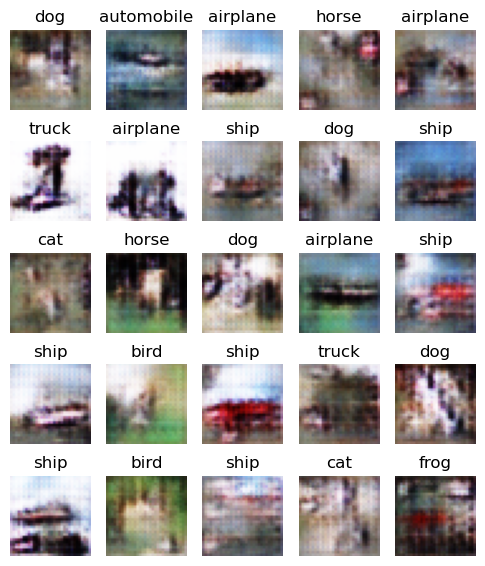

  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 5/32]
	G_Trn_Loss: 1.1309	D_Trn_Loss: 1.2929	D_Trn_Real: 0.5498	D_Trn_Fake: 0.5290	D_Trn_Acc: 62.64% 
	G_Val_Loss: 0.7914	D_Val_Loss: 1.3002	D_Val_Real: 0.5498	D_Val_Fake: 0.5290	D_Val_Acc: 62.24%


  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 6/32]
	G_Trn_Loss: 1.0060	D_Trn_Loss: 1.3304	D_Trn_Real: 0.5352	D_Trn_Fake: 0.4942	D_Trn_Acc: 59.72% 
	G_Val_Loss: 0.7160	D_Val_Loss: 1.4027	D_Val_Real: 0.5352	D_Val_Fake: 0.4942	D_Val_Acc: 54.77%


  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 7/32]
	G_Trn_Loss: 0.9569	D_Trn_Loss: 1.3342	D_Trn_Real: 0.4993	D_Trn_Fake: 0.5212	D_Trn_Acc: 59.61% 
	G_Val_Loss: 0.7673	D_Val_Loss: 1.4042	D_Val_Real: 0.4993	D_Val_Fake: 0.5212	D_Val_Acc: 53.40%


  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 8/32]
	G_Trn_Loss: 0.9569	D_Trn_Loss: 1.3314	D_Trn_Real: 0.5073	D_Trn_Fake: 0.5200	D_Trn_Acc: 59.51% 
	G_Val_Loss: 0.7614	D_Val_Loss: 1.3912	D_Val_Real: 0.5073	D_Val_Fake: 0.5200	D_Val_Acc: 54.76%


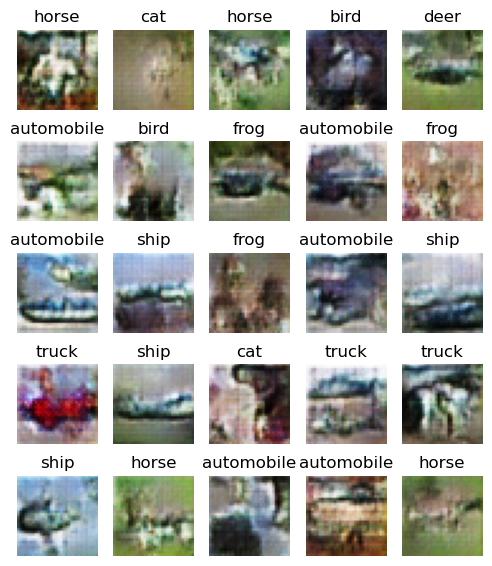

  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 9/32]
	G_Trn_Loss: 0.9545	D_Trn_Loss: 1.3295	D_Trn_Real: 0.4962	D_Trn_Fake: 0.5527	D_Trn_Acc: 59.73% 
	G_Val_Loss: 0.8399	D_Val_Loss: 1.3509	D_Val_Real: 0.4962	D_Val_Fake: 0.5527	D_Val_Acc: 57.75%


  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 10/32]
	G_Trn_Loss: 0.9431	D_Trn_Loss: 1.3143	D_Trn_Real: 0.4550	D_Trn_Fake: 0.5608	D_Trn_Acc: 61.01% 
	G_Val_Loss: 0.8578	D_Val_Loss: 1.4220	D_Val_Real: 0.4550	D_Val_Fake: 0.5608	D_Val_Acc: 52.97%


  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 11/32]
	G_Trn_Loss: 0.9572	D_Trn_Loss: 1.3119	D_Trn_Real: 0.4966	D_Trn_Fake: 0.5273	D_Trn_Acc: 61.02% 
	G_Val_Loss: 0.7723	D_Val_Loss: 1.3868	D_Val_Real: 0.4966	D_Val_Fake: 0.5273	D_Val_Acc: 54.45%


  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 12/32]
	G_Trn_Loss: 0.9190	D_Trn_Loss: 1.3229	D_Trn_Real: 0.5037	D_Trn_Fake: 0.5282	D_Trn_Acc: 60.00% 
	G_Val_Loss: 0.7847	D_Val_Loss: 1.3777	D_Val_Real: 0.5037	D_Val_Fake: 0.5282	D_Val_Acc: 55.03%


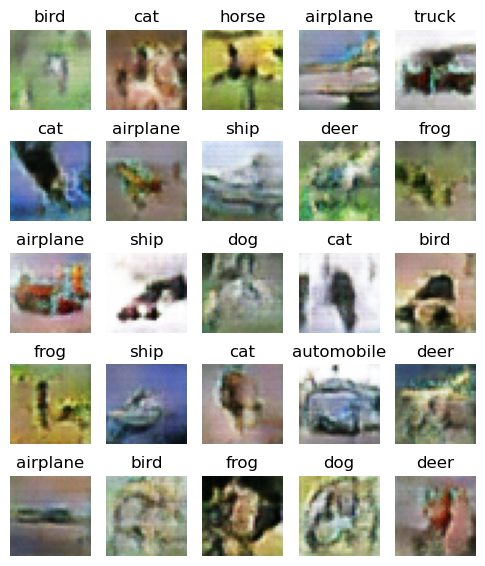

  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 13/32]
	G_Trn_Loss: 0.9103	D_Trn_Loss: 1.3241	D_Trn_Real: 0.5086	D_Trn_Fake: 0.5179	D_Trn_Acc: 60.12% 
	G_Val_Loss: 0.7556	D_Val_Loss: 1.3859	D_Val_Real: 0.5086	D_Val_Fake: 0.5179	D_Val_Acc: 54.90%


  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 14/32]
	G_Trn_Loss: 0.8967	D_Trn_Loss: 1.3216	D_Trn_Real: 0.4990	D_Trn_Fake: 0.5438	D_Trn_Acc: 60.47% 
	G_Val_Loss: 0.8157	D_Val_Loss: 1.3492	D_Val_Real: 0.4990	D_Val_Fake: 0.5438	D_Val_Acc: 57.65%


  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 15/32]
	G_Trn_Loss: 0.9006	D_Trn_Loss: 1.3303	D_Trn_Real: 0.5111	D_Trn_Fake: 0.5252	D_Trn_Acc: 59.45% 
	G_Val_Loss: 0.7688	D_Val_Loss: 1.3607	D_Val_Real: 0.5111	D_Val_Fake: 0.5252	D_Val_Acc: 56.66%


  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 16/32]
	G_Trn_Loss: 0.8745	D_Trn_Loss: 1.3202	D_Trn_Real: 0.5201	D_Trn_Fake: 0.5294	D_Trn_Acc: 60.56% 
	G_Val_Loss: 0.7832	D_Val_Loss: 1.3390	D_Val_Real: 0.5201	D_Val_Fake: 0.5294	D_Val_Acc: 59.00%


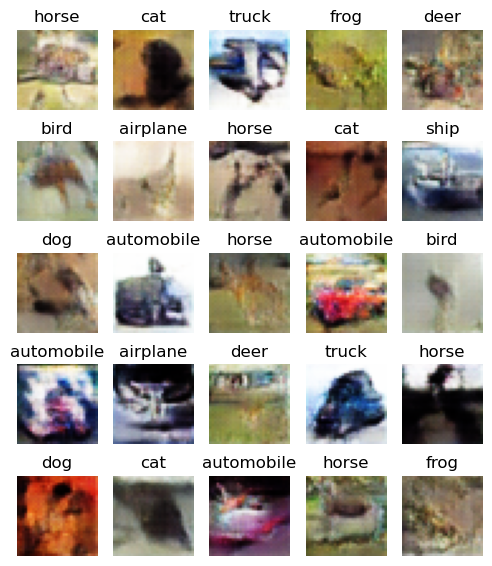

  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 17/32]
	G_Trn_Loss: 0.8808	D_Trn_Loss: 1.3263	D_Trn_Real: 0.4981	D_Trn_Fake: 0.5546	D_Trn_Acc: 59.75% 
	G_Val_Loss: 0.8399	D_Val_Loss: 1.3301	D_Val_Real: 0.4981	D_Val_Fake: 0.5546	D_Val_Acc: 59.42%


  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 18/32]
	G_Trn_Loss: 0.8749	D_Trn_Loss: 1.3238	D_Trn_Real: 0.4563	D_Trn_Fake: 0.5569	D_Trn_Acc: 60.03% 
	G_Val_Loss: 0.8561	D_Val_Loss: 1.4329	D_Val_Real: 0.4563	D_Val_Fake: 0.5569	D_Val_Acc: 51.96%


  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 19/32]
	G_Trn_Loss: 0.8737	D_Trn_Loss: 1.3198	D_Trn_Real: 0.5064	D_Trn_Fake: 0.5175	D_Trn_Acc: 60.61% 
	G_Val_Loss: 0.7523	D_Val_Loss: 1.3815	D_Val_Real: 0.5064	D_Val_Fake: 0.5175	D_Val_Acc: 53.99%


  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 20/32]
	G_Trn_Loss: 0.8813	D_Trn_Loss: 1.3197	D_Trn_Real: 0.4885	D_Trn_Fake: 0.5299	D_Trn_Acc: 60.58% 
	G_Val_Loss: 0.7847	D_Val_Loss: 1.4028	D_Val_Real: 0.4885	D_Val_Fake: 0.5299	D_Val_Acc: 53.42%


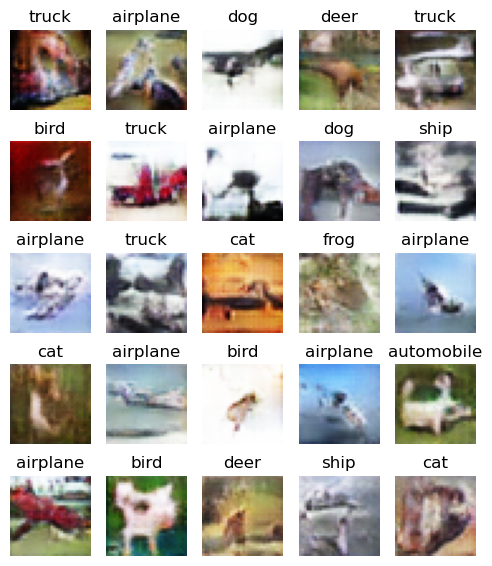

  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 21/32]
	G_Trn_Loss: 0.8787	D_Trn_Loss: 1.3097	D_Trn_Real: 0.4518	D_Trn_Fake: 0.5980	D_Trn_Acc: 61.23% 
	G_Val_Loss: 0.9543	D_Val_Loss: 1.3605	D_Val_Real: 0.4518	D_Val_Fake: 0.5980	D_Val_Acc: 56.74%


  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 22/32]
	G_Trn_Loss: 0.8828	D_Trn_Loss: 1.3039	D_Trn_Real: 0.4211	D_Trn_Fake: 0.6053	D_Trn_Acc: 61.79% 
	G_Val_Loss: 0.9658	D_Val_Loss: 1.4182	D_Val_Real: 0.4211	D_Val_Fake: 0.6053	D_Val_Acc: 54.22%


  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 23/32]
	G_Trn_Loss: 0.8881	D_Trn_Loss: 1.2994	D_Trn_Real: 0.5444	D_Trn_Fake: 0.4980	D_Trn_Acc: 62.13% 
	G_Val_Loss: 0.7121	D_Val_Loss: 1.3515	D_Val_Real: 0.5444	D_Val_Fake: 0.4980	D_Val_Acc: 57.12%


  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 24/32]
	G_Trn_Loss: 0.8990	D_Trn_Loss: 1.2907	D_Trn_Real: 0.5070	D_Trn_Fake: 0.5457	D_Trn_Acc: 62.82% 
	G_Val_Loss: 0.8244	D_Val_Loss: 1.3385	D_Val_Real: 0.5070	D_Val_Fake: 0.5457	D_Val_Acc: 59.10%


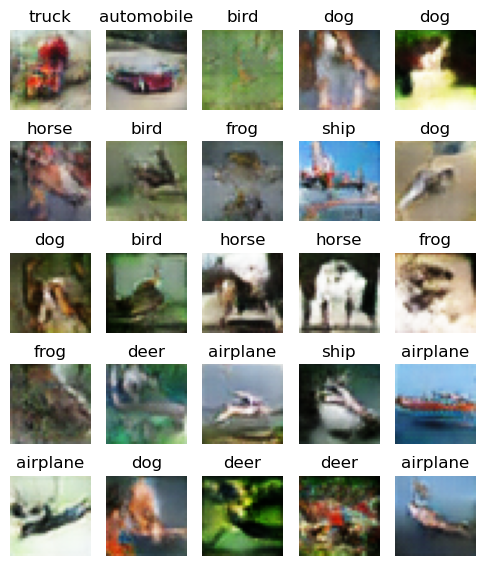

  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 25/32]
	G_Trn_Loss: 0.9066	D_Trn_Loss: 1.2823	D_Trn_Real: 0.5036	D_Trn_Fake: 0.5385	D_Trn_Acc: 63.55% 
	G_Val_Loss: 0.8067	D_Val_Loss: 1.3589	D_Val_Real: 0.5036	D_Val_Fake: 0.5385	D_Val_Acc: 57.65%


  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 26/32]
	G_Trn_Loss: 0.9024	D_Trn_Loss: 1.2730	D_Trn_Real: 0.5744	D_Trn_Fake: 0.4753	D_Trn_Acc: 64.30% 
	G_Val_Loss: 0.6728	D_Val_Loss: 1.3555	D_Val_Real: 0.5744	D_Val_Fake: 0.4753	D_Val_Acc: 57.64%


  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 27/32]
	G_Trn_Loss: 0.9138	D_Trn_Loss: 1.2624	D_Trn_Real: 0.5459	D_Trn_Fake: 0.5117	D_Trn_Acc: 64.89% 
	G_Val_Loss: 0.7509	D_Val_Loss: 1.3340	D_Val_Real: 0.5459	D_Val_Fake: 0.5117	D_Val_Acc: 59.39%


  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 28/32]
	G_Trn_Loss: 0.9286	D_Trn_Loss: 1.2575	D_Trn_Real: 0.5044	D_Trn_Fake: 0.5347	D_Trn_Acc: 65.23% 
	G_Val_Loss: 0.8024	D_Val_Loss: 1.3720	D_Val_Real: 0.5044	D_Val_Fake: 0.5347	D_Val_Acc: 56.42%


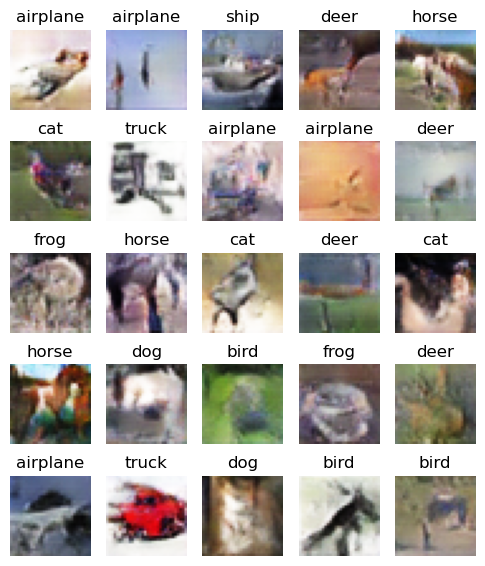

  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 29/32]
	G_Trn_Loss: 0.9342	D_Trn_Loss: 1.2453	D_Trn_Real: 0.5005	D_Trn_Fake: 0.5520	D_Trn_Acc: 65.85% 
	G_Val_Loss: 0.8471	D_Val_Loss: 1.3525	D_Val_Real: 0.5005	D_Val_Fake: 0.5520	D_Val_Acc: 58.18%


  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 30/32]
	G_Trn_Loss: 0.9433	D_Trn_Loss: 1.2283	D_Trn_Real: 0.4287	D_Trn_Fake: 0.6075	D_Trn_Acc: 67.15% 
	G_Val_Loss: 0.9960	D_Val_Loss: 1.4225	D_Val_Real: 0.4287	D_Val_Fake: 0.6075	D_Val_Acc: 54.70%


  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 31/32]
	G_Trn_Loss: 0.9539	D_Trn_Loss: 1.2323	D_Trn_Real: 0.4809	D_Trn_Fake: 0.5796	D_Trn_Acc: 66.69% 
	G_Val_Loss: 0.9220	D_Val_Loss: 1.3570	D_Val_Real: 0.4809	D_Val_Fake: 0.5796	D_Val_Acc: 58.92%


  0%|          | 0/391 [00:00<?, ?batch/s]

[Epoch 32/32]
	G_Trn_Loss: 0.9645	D_Trn_Loss: 1.2136	D_Trn_Real: 0.5707	D_Trn_Fake: 0.4933	D_Trn_Acc: 67.95% 
	G_Val_Loss: 0.7208	D_Val_Loss: 1.3397	D_Val_Real: 0.5707	D_Val_Fake: 0.4933	D_Val_Acc: 59.05%


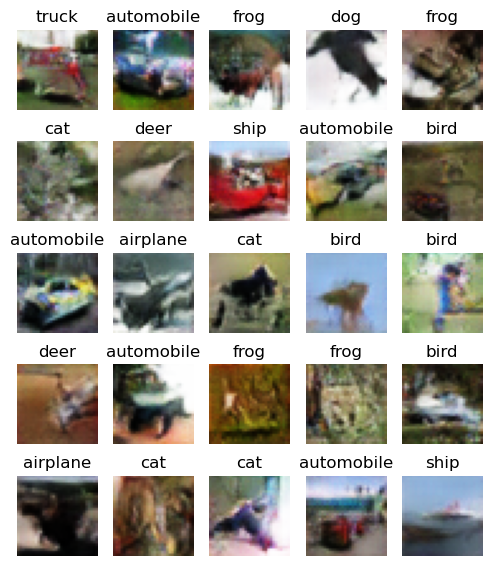

In [67]:
train_stats, val_stats = train(
    generator,
    discriminator,
    train_loader,
    val_loader,
    g_optimizer,
    d_optimizer,
    criterion,
    device,
    epochs=epochs,
    plot_frequency=4,
    label_mapper=label_mapper,
)

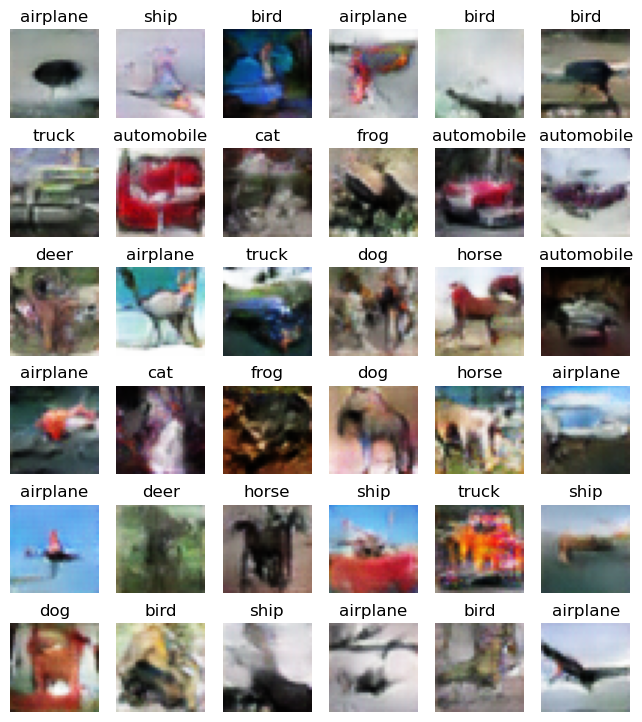

In [68]:
plot_generated_images(
    generator,
    device=device,
    num_images=36,
    denormalize=True,
    figsize=(8, 9),
    label_decoder=label_mapper,
)

## Exercício 2

Treine uma GAN no dataset [Stanford Dogs Dataset](http://vision.stanford.edu/aditya86/ImageNetDogs/). O dataset contém imagens de Cachorros de 120 raças diferentes e suas respectivas anotações.

<details>
<summary>Dica:</summary>

Utilize a classe ImageFolder do torchvision.datasets para carregar o dataset. O nome das pastas deve ser o nome da raça do cachorro.

As imagens do dataset possuem tamanhos diferentes, você pode redimensionar as imagens para um tamanho fixo utilizando a classe Resize do torchvision.transforms.

</details>


In [ ]:
dogs_path = '/pgeoprj2/ciag2024/dados/GAN/dogs'

### Dataset

O dataset contém imagens de cachorros de 120 raças diferentes. As imagens estão organizadas em pastas, onde o nome da pasta é o nome da raça do cachorro. Vamos importar o dataset e visualizar algumas imagens.

In [28]:
dogs_dataset = ImageFolder(
    dogs_path,
    transform=transforms.Compose(
        [
            transforms.ToImage(),
            transforms.ToDtype(torch.float32, scale=True),
            # center crop images to 64x64 so they are closer to the camera
            transforms.Resize((96, 96)),
            transforms.RandomCrop(64),
            transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
        ]
    ),
)

dogs_dataset.classes = [c.split('-')[-1].replace('_', ' ') for c in dogs_dataset.classes]
dogs_mapper = DatasetLabelMapper(dogs_dataset)

FileNotFoundError: [WinError 3] The system cannot find the path specified: './data/dogs'

In [29]:
plot_dataset(dogs_dataset, n_cols=6, n_rows=6, denormalize=True, figsize=(12, 12), label_decoder=dogs_mapper)

NameError: name 'dogs_dataset' is not defined

Number of samples: 16464
Sample shape: torch.Size([3, 64, 64])


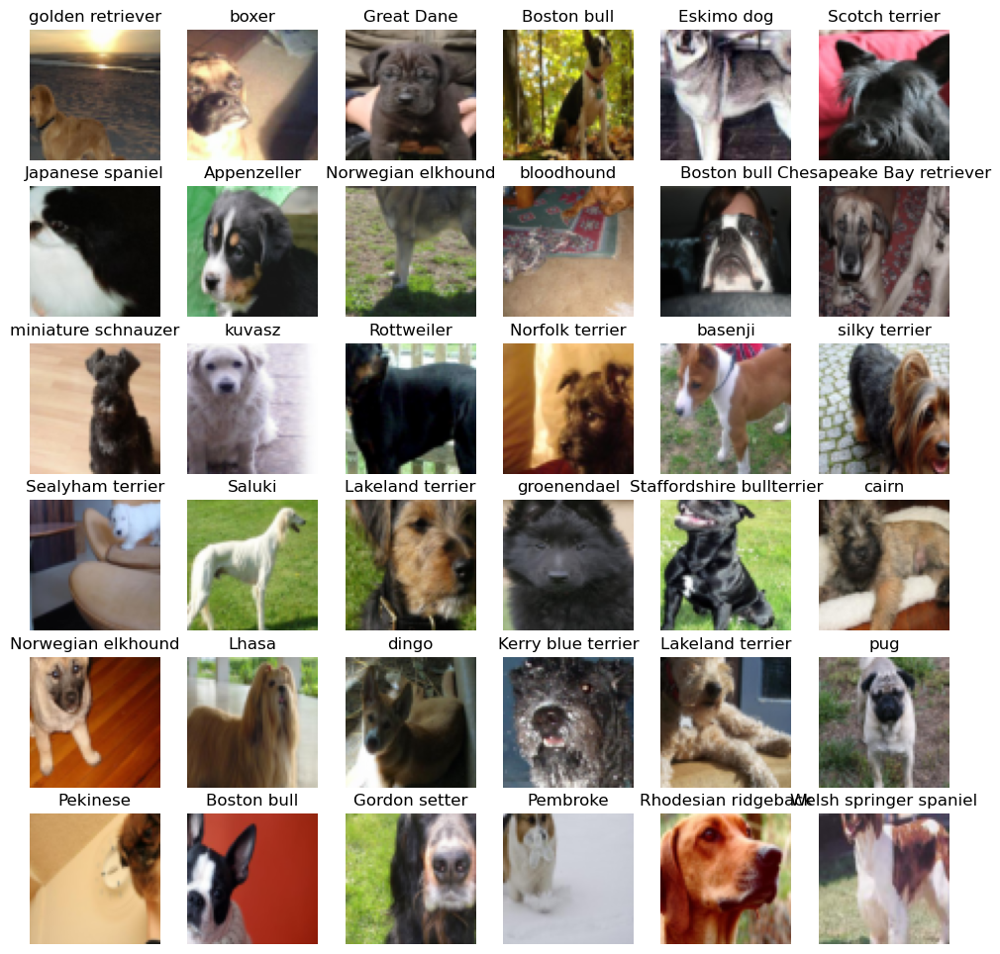

In [76]:
# Separando em dataset de treino e validação
train_dataset, val_dataset = random_split(
    dogs_dataset, [0.8, 0.2], generator=torch.Generator().manual_seed(42)
)

train_loader = DataLoader(
    train_dataset, batch_size=128, shuffle=True, num_workers=4, pin_memory=True
)
val_loader = DataLoader(
    val_dataset, batch_size=128, shuffle=False, num_workers=2, pin_memory=True
)

plot_dataset(train_dataset, n_cols=6, n_rows=6, denormalize=True, figsize=(12, 12), label_decoder=dogs_mapper)

### Treinamento

In [77]:
epochs = 48
latent_dim = 128
num_classes = len(dogs_dataset.classes)
dataset_dim = 3
embedding_size = 64
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

generator = EmbeddingGenerator(latent_dim, output_dim=dataset_dim, embedding_size=embedding_size, n_classes=num_classes)
discriminator = EmbeddingDiscriminator(in_channels=dataset_dim, embedding_size=embedding_size, n_classes=num_classes)

g_optimizer = torch.optim.Adam(generator.parameters(), lr=0.0002, betas=(0.5, 0.999))
d_optimizer = torch.optim.Adam(
    discriminator.parameters(), lr=0.0002, betas=(0.5, 0.999)
)
criterion = nn.BCELoss()

  0%|          | 0/129 [00:00<?, ?batch/s]

[Epoch 1/48]
	G_Trn_Loss: 3.5076	D_Trn_Loss: 0.8337	D_Trn_Real: 0.6512	D_Trn_Fake: 0.3856	D_Trn_Acc: 82.02% 
	G_Val_Loss: 0.5261	D_Val_Loss: 1.5274	D_Val_Real: 0.6512	D_Val_Fake: 0.3856	D_Val_Acc: 51.15%


  0%|          | 0/129 [00:00<?, ?batch/s]

[Epoch 2/48]
	G_Trn_Loss: 3.0201	D_Trn_Loss: 0.8988	D_Trn_Real: 0.6153	D_Trn_Fake: 0.4692	D_Trn_Acc: 79.75% 
	G_Val_Loss: 0.6966	D_Val_Loss: 1.3734	D_Val_Real: 0.6153	D_Val_Fake: 0.4692	D_Val_Acc: 59.31%


  0%|          | 0/129 [00:00<?, ?batch/s]

[Epoch 3/48]
	G_Trn_Loss: 2.8673	D_Trn_Loss: 0.8896	D_Trn_Real: 0.4447	D_Trn_Fake: 0.6263	D_Trn_Acc: 79.45% 
	G_Val_Loss: 1.1022	D_Val_Loss: 1.4381	D_Val_Real: 0.4447	D_Val_Fake: 0.6263	D_Val_Acc: 57.85%


  0%|          | 0/129 [00:00<?, ?batch/s]

[Epoch 4/48]
	G_Trn_Loss: 2.8213	D_Trn_Loss: 0.8925	D_Trn_Real: 0.4265	D_Trn_Fake: 0.5875	D_Trn_Acc: 79.21% 
	G_Val_Loss: 1.0218	D_Val_Loss: 1.6126	D_Val_Real: 0.4265	D_Val_Fake: 0.5875	D_Val_Acc: 51.58%


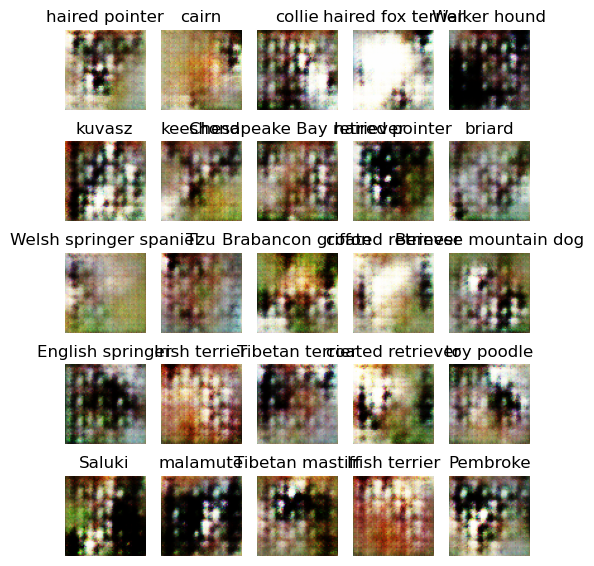

  0%|          | 0/129 [00:00<?, ?batch/s]

[Epoch 5/48]
	G_Trn_Loss: 2.8370	D_Trn_Loss: 0.8854	D_Trn_Real: 0.2985	D_Trn_Fake: 0.7101	D_Trn_Acc: 79.87% 
	G_Val_Loss: 1.4571	D_Val_Loss: 1.8470	D_Val_Real: 0.2985	D_Val_Fake: 0.7101	D_Val_Acc: 51.43%


  0%|          | 0/129 [00:00<?, ?batch/s]

[Epoch 6/48]
	G_Trn_Loss: 2.8279	D_Trn_Loss: 0.8746	D_Trn_Real: 0.1585	D_Trn_Fake: 0.9558	D_Trn_Acc: 80.53% 
	G_Val_Loss: 3.5873	D_Val_Loss: 2.2418	D_Val_Real: 0.1585	D_Val_Fake: 0.9558	D_Val_Acc: 51.20%


  0%|          | 0/129 [00:00<?, ?batch/s]

[Epoch 7/48]
	G_Trn_Loss: 2.6629	D_Trn_Loss: 0.9661	D_Trn_Real: 0.5208	D_Trn_Fake: 0.7142	D_Trn_Acc: 76.88% 
	G_Val_Loss: 1.4122	D_Val_Loss: 1.1258	D_Val_Real: 0.5208	D_Val_Fake: 0.7142	D_Val_Acc: 72.01%


  0%|          | 0/129 [00:00<?, ?batch/s]

[Epoch 8/48]
	G_Trn_Loss: 2.7073	D_Trn_Loss: 0.8943	D_Trn_Real: 0.6058	D_Trn_Fake: 0.6271	D_Trn_Acc: 79.76% 
	G_Val_Loss: 1.1249	D_Val_Loss: 1.1094	D_Val_Real: 0.6058	D_Val_Fake: 0.6271	D_Val_Acc: 72.17%


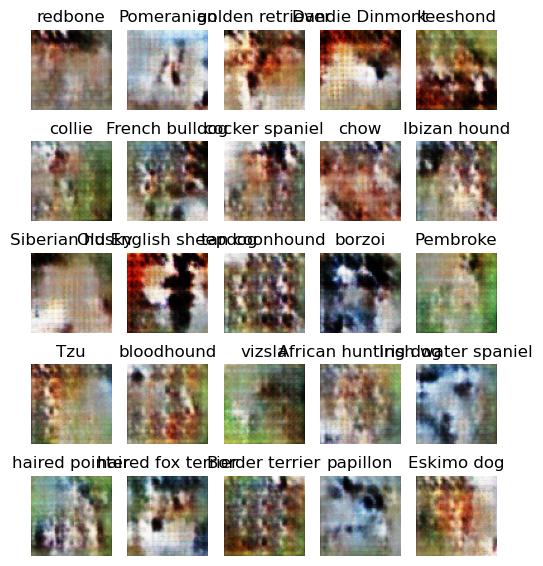

  0%|          | 0/129 [00:00<?, ?batch/s]

[Epoch 9/48]
	G_Trn_Loss: 2.6839	D_Trn_Loss: 0.9054	D_Trn_Real: 0.5838	D_Trn_Fake: 0.7309	D_Trn_Acc: 79.79% 
	G_Val_Loss: 1.4918	D_Val_Loss: 0.9610	D_Val_Real: 0.5838	D_Val_Fake: 0.7309	D_Val_Acc: 77.53%


  0%|          | 0/129 [00:00<?, ?batch/s]

[Epoch 10/48]
	G_Trn_Loss: 2.6332	D_Trn_Loss: 0.9114	D_Trn_Real: 0.4418	D_Trn_Fake: 0.8747	D_Trn_Acc: 78.94% 
	G_Val_Loss: 2.3780	D_Val_Loss: 1.1113	D_Val_Real: 0.4418	D_Val_Fake: 0.8747	D_Val_Acc: 68.44%


  0%|          | 0/129 [00:00<?, ?batch/s]

[Epoch 11/48]
	G_Trn_Loss: 2.6106	D_Trn_Loss: 0.9420	D_Trn_Real: 0.5972	D_Trn_Fake: 0.5724	D_Trn_Acc: 77.49% 
	G_Val_Loss: 0.9456	D_Val_Loss: 1.2076	D_Val_Real: 0.5972	D_Val_Fake: 0.5724	D_Val_Acc: 66.87%


  0%|          | 0/129 [00:00<?, ?batch/s]

[Epoch 12/48]
	G_Trn_Loss: 2.4480	D_Trn_Loss: 0.8823	D_Trn_Real: 0.4769	D_Trn_Fake: 0.7394	D_Trn_Acc: 80.45% 
	G_Val_Loss: 1.5121	D_Val_Loss: 1.1828	D_Val_Real: 0.4769	D_Val_Fake: 0.7394	D_Val_Acc: 68.63%


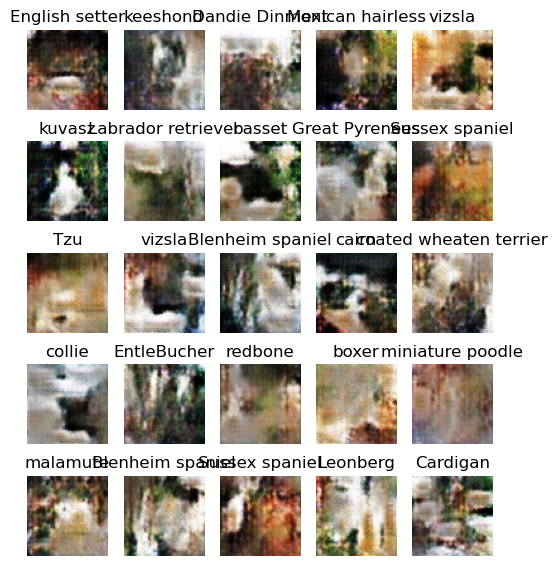

  0%|          | 0/129 [00:00<?, ?batch/s]

[Epoch 13/48]
	G_Trn_Loss: 2.2685	D_Trn_Loss: 0.9704	D_Trn_Real: 0.2806	D_Trn_Fake: 0.8591	D_Trn_Acc: 78.41% 
	G_Val_Loss: 2.1526	D_Val_Loss: 1.6277	D_Val_Real: 0.2806	D_Val_Fake: 0.8591	D_Val_Acc: 55.55%


  0%|          | 0/129 [00:00<?, ?batch/s]

[Epoch 14/48]
	G_Trn_Loss: 2.1419	D_Trn_Loss: 0.9579	D_Trn_Real: 0.3345	D_Trn_Fake: 0.8737	D_Trn_Acc: 77.69% 
	G_Val_Loss: 2.3159	D_Val_Loss: 1.4136	D_Val_Real: 0.3345	D_Val_Fake: 0.8737	D_Val_Acc: 59.64%


  0%|          | 0/129 [00:00<?, ?batch/s]

[Epoch 15/48]
	G_Trn_Loss: 2.1549	D_Trn_Loss: 0.9888	D_Trn_Real: 0.6023	D_Trn_Fake: 0.6148	D_Trn_Acc: 76.58% 
	G_Val_Loss: 1.1100	D_Val_Loss: 1.1231	D_Val_Real: 0.6023	D_Val_Fake: 0.6148	D_Val_Acc: 71.59%


  0%|          | 0/129 [00:00<?, ?batch/s]

[Epoch 16/48]
	G_Trn_Loss: 2.1034	D_Trn_Loss: 0.9559	D_Trn_Real: 0.6174	D_Trn_Fake: 0.5690	D_Trn_Acc: 77.95% 
	G_Val_Loss: 0.9515	D_Val_Loss: 1.1820	D_Val_Real: 0.6174	D_Val_Fake: 0.5690	D_Val_Acc: 68.07%


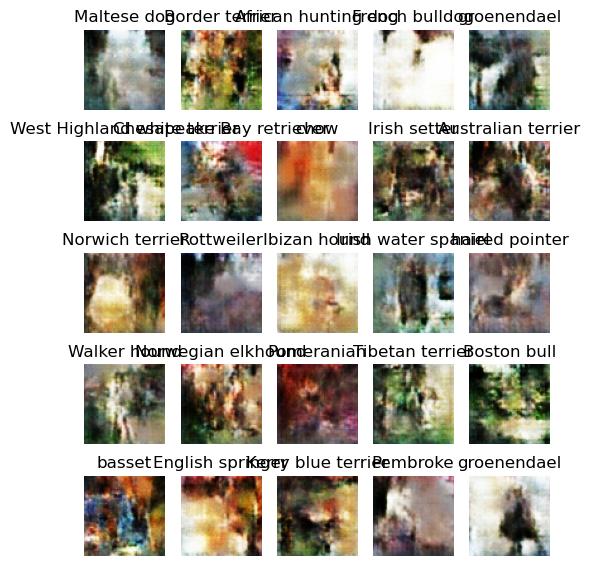

  0%|          | 0/129 [00:00<?, ?batch/s]

[Epoch 17/48]
	G_Trn_Loss: 2.0298	D_Trn_Loss: 0.9199	D_Trn_Real: 0.5041	D_Trn_Fake: 0.7357	D_Trn_Acc: 79.22% 
	G_Val_Loss: 1.4578	D_Val_Loss: 1.0998	D_Val_Real: 0.5041	D_Val_Fake: 0.7357	D_Val_Acc: 72.63%


  0%|          | 0/129 [00:00<?, ?batch/s]

[Epoch 18/48]
	G_Trn_Loss: 2.0060	D_Trn_Loss: 0.9214	D_Trn_Real: 0.6355	D_Trn_Fake: 0.6184	D_Trn_Acc: 80.15% 
	G_Val_Loss: 1.0871	D_Val_Loss: 1.0369	D_Val_Real: 0.6355	D_Val_Fake: 0.6184	D_Val_Acc: 75.30%


  0%|          | 0/129 [00:00<?, ?batch/s]

[Epoch 19/48]
	G_Trn_Loss: 1.9959	D_Trn_Loss: 0.8862	D_Trn_Real: 0.6654	D_Trn_Fake: 0.6055	D_Trn_Acc: 80.37% 
	G_Val_Loss: 1.0438	D_Val_Loss: 1.0017	D_Val_Real: 0.6654	D_Val_Fake: 0.6055	D_Val_Acc: 76.69%


  0%|          | 0/129 [00:00<?, ?batch/s]

[Epoch 20/48]
	G_Trn_Loss: 1.9857	D_Trn_Loss: 0.8831	D_Trn_Real: 0.3700	D_Trn_Fake: 0.8455	D_Trn_Acc: 81.36% 
	G_Val_Loss: 2.0676	D_Val_Loss: 1.3201	D_Val_Real: 0.3700	D_Val_Fake: 0.8455	D_Val_Acc: 61.66%


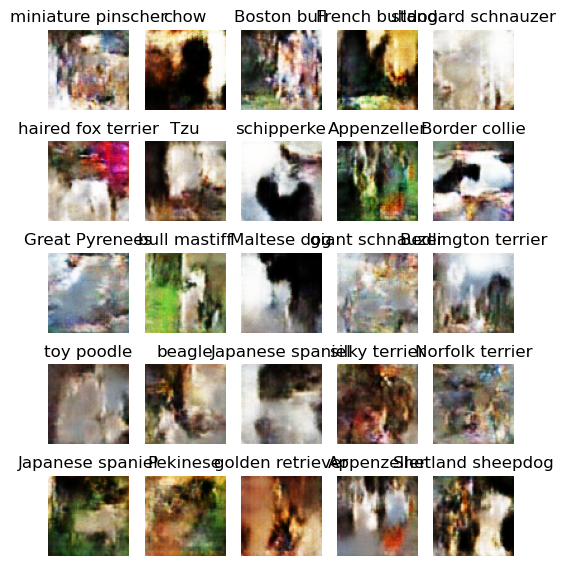

  0%|          | 0/129 [00:00<?, ?batch/s]

[Epoch 21/48]
	G_Trn_Loss: 2.0286	D_Trn_Loss: 0.8978	D_Trn_Real: 0.6125	D_Trn_Fake: 0.6298	D_Trn_Acc: 79.87% 
	G_Val_Loss: 1.1037	D_Val_Loss: 1.0583	D_Val_Real: 0.6125	D_Val_Fake: 0.6298	D_Val_Acc: 74.79%


  0%|          | 0/129 [00:00<?, ?batch/s]

[Epoch 22/48]
	G_Trn_Loss: 2.0111	D_Trn_Loss: 0.8635	D_Trn_Real: 0.5869	D_Trn_Fake: 0.7283	D_Trn_Acc: 81.37% 
	G_Val_Loss: 1.4720	D_Val_Loss: 0.9470	D_Val_Real: 0.5869	D_Val_Fake: 0.7283	D_Val_Acc: 79.91%


  0%|          | 0/129 [00:00<?, ?batch/s]

[Epoch 23/48]
	G_Trn_Loss: 2.0336	D_Trn_Loss: 0.8797	D_Trn_Real: 0.6447	D_Trn_Fake: 0.6333	D_Trn_Acc: 81.10% 
	G_Val_Loss: 1.1074	D_Val_Loss: 0.9829	D_Val_Real: 0.6447	D_Val_Fake: 0.6333	D_Val_Acc: 78.74%


  0%|          | 0/129 [00:00<?, ?batch/s]

[Epoch 24/48]
	G_Trn_Loss: 2.0927	D_Trn_Loss: 0.8616	D_Trn_Real: 0.6683	D_Trn_Fake: 0.5971	D_Trn_Acc: 80.29% 
	G_Val_Loss: 1.0326	D_Val_Loss: 1.0204	D_Val_Real: 0.6683	D_Val_Fake: 0.5971	D_Val_Acc: 75.81%


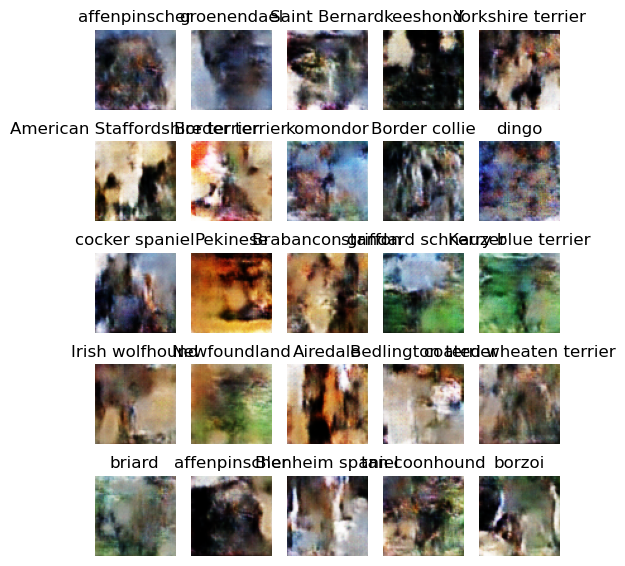

  0%|          | 0/129 [00:00<?, ?batch/s]

[Epoch 25/48]
	G_Trn_Loss: 2.0566	D_Trn_Loss: 0.8273	D_Trn_Real: 0.6013	D_Trn_Fake: 0.6962	D_Trn_Acc: 82.57% 
	G_Val_Loss: 1.3645	D_Val_Loss: 0.9747	D_Val_Real: 0.6013	D_Val_Fake: 0.6962	D_Val_Acc: 77.98%


  0%|          | 0/129 [00:00<?, ?batch/s]

[Epoch 26/48]
	G_Trn_Loss: 2.0242	D_Trn_Loss: 0.8554	D_Trn_Real: 0.6700	D_Trn_Fake: 0.6489	D_Trn_Acc: 82.48% 
	G_Val_Loss: 1.1689	D_Val_Loss: 0.9094	D_Val_Real: 0.6700	D_Val_Fake: 0.6489	D_Val_Acc: 82.17%


  0%|          | 0/129 [00:00<?, ?batch/s]

[Epoch 27/48]
	G_Trn_Loss: 2.0341	D_Trn_Loss: 0.7971	D_Trn_Real: 0.7133	D_Trn_Fake: 0.6064	D_Trn_Acc: 84.18% 
	G_Val_Loss: 1.0449	D_Val_Loss: 0.9263	D_Val_Real: 0.7133	D_Val_Fake: 0.6064	D_Val_Acc: 80.05%


  0%|          | 0/129 [00:00<?, ?batch/s]

[Epoch 28/48]
	G_Trn_Loss: 2.1414	D_Trn_Loss: 0.8234	D_Trn_Real: 0.7009	D_Trn_Fake: 0.5543	D_Trn_Acc: 82.02% 
	G_Val_Loss: 0.9372	D_Val_Loss: 1.0785	D_Val_Real: 0.7009	D_Val_Fake: 0.5543	D_Val_Acc: 71.33%


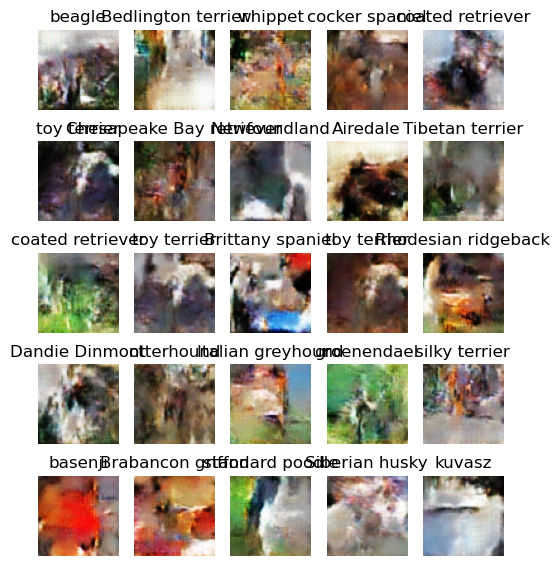

  0%|          | 0/129 [00:00<?, ?batch/s]

[Epoch 29/48]
	G_Trn_Loss: 2.1712	D_Trn_Loss: 0.8315	D_Trn_Real: 0.5363	D_Trn_Fake: 0.7275	D_Trn_Acc: 81.29% 
	G_Val_Loss: 1.5300	D_Val_Loss: 1.0975	D_Val_Real: 0.5363	D_Val_Fake: 0.7275	D_Val_Acc: 72.68%


  0%|          | 0/129 [00:00<?, ?batch/s]

[Epoch 30/48]
	G_Trn_Loss: 2.1162	D_Trn_Loss: 0.8105	D_Trn_Real: 0.5994	D_Trn_Fake: 0.6842	D_Trn_Acc: 83.05% 
	G_Val_Loss: 1.3589	D_Val_Loss: 1.0329	D_Val_Real: 0.5994	D_Val_Fake: 0.6842	D_Val_Acc: 75.64%


  0%|          | 0/129 [00:00<?, ?batch/s]

[Epoch 31/48]
	G_Trn_Loss: 2.1579	D_Trn_Loss: 0.8207	D_Trn_Real: 0.5490	D_Trn_Fake: 0.7018	D_Trn_Acc: 82.20% 
	G_Val_Loss: 1.3313	D_Val_Loss: 1.0801	D_Val_Real: 0.5490	D_Val_Fake: 0.7018	D_Val_Acc: 75.00%


  0%|          | 0/129 [00:00<?, ?batch/s]

[Epoch 32/48]
	G_Trn_Loss: 2.1530	D_Trn_Loss: 0.8403	D_Trn_Real: 0.7231	D_Trn_Fake: 0.5930	D_Trn_Acc: 82.45% 
	G_Val_Loss: 0.9926	D_Val_Loss: 0.9349	D_Val_Real: 0.7231	D_Val_Fake: 0.5930	D_Val_Acc: 79.24%


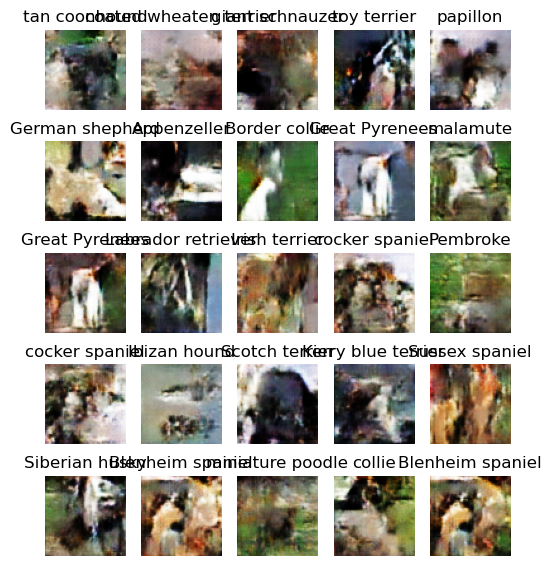

  0%|          | 0/129 [00:00<?, ?batch/s]

[Epoch 33/48]
	G_Trn_Loss: 2.2599	D_Trn_Loss: 0.8120	D_Trn_Real: 0.6300	D_Trn_Fake: 0.6637	D_Trn_Acc: 82.65% 
	G_Val_Loss: 1.2346	D_Val_Loss: 0.9932	D_Val_Real: 0.6300	D_Val_Fake: 0.6637	D_Val_Acc: 77.13%


  0%|          | 0/129 [00:00<?, ?batch/s]

[Epoch 34/48]
	G_Trn_Loss: 2.1854	D_Trn_Loss: 0.8126	D_Trn_Real: 0.6337	D_Trn_Fake: 0.7028	D_Trn_Acc: 82.48% 
	G_Val_Loss: 1.3771	D_Val_Loss: 0.9144	D_Val_Real: 0.6337	D_Val_Fake: 0.7028	D_Val_Acc: 81.10%


  0%|          | 0/129 [00:00<?, ?batch/s]

[Epoch 35/48]
	G_Trn_Loss: 2.1819	D_Trn_Loss: 0.7966	D_Trn_Real: 0.5675	D_Trn_Fake: 0.7666	D_Trn_Acc: 82.80% 
	G_Val_Loss: 1.6415	D_Val_Loss: 0.9556	D_Val_Real: 0.5675	D_Val_Fake: 0.7666	D_Val_Acc: 78.13%


  0%|          | 0/129 [00:00<?, ?batch/s]

[Epoch 36/48]
	G_Trn_Loss: 2.1922	D_Trn_Loss: 0.7856	D_Trn_Real: 0.6647	D_Trn_Fake: 0.6497	D_Trn_Acc: 83.19% 
	G_Val_Loss: 1.2382	D_Val_Loss: 0.9525	D_Val_Real: 0.6647	D_Val_Fake: 0.6497	D_Val_Acc: 77.96%


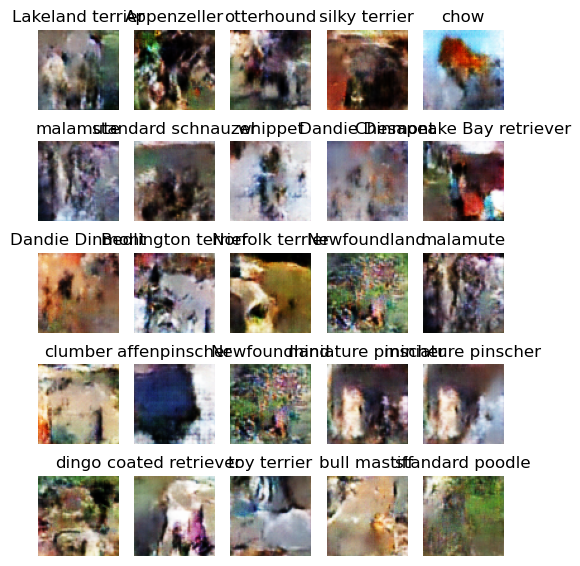

  0%|          | 0/129 [00:00<?, ?batch/s]

[Epoch 37/48]
	G_Trn_Loss: 2.1782	D_Trn_Loss: 0.8113	D_Trn_Real: 0.6163	D_Trn_Fake: 0.7106	D_Trn_Acc: 83.30% 
	G_Val_Loss: 1.4110	D_Val_Loss: 0.9510	D_Val_Real: 0.6163	D_Val_Fake: 0.7106	D_Val_Acc: 79.83%


  0%|          | 0/129 [00:00<?, ?batch/s]

[Epoch 38/48]
	G_Trn_Loss: 2.1651	D_Trn_Loss: 0.7984	D_Trn_Real: 0.6229	D_Trn_Fake: 0.7255	D_Trn_Acc: 83.88% 
	G_Val_Loss: 1.4374	D_Val_Loss: 0.8962	D_Val_Real: 0.6229	D_Val_Fake: 0.7255	D_Val_Acc: 81.97%


  0%|          | 0/129 [00:00<?, ?batch/s]

[Epoch 39/48]
	G_Trn_Loss: 2.1730	D_Trn_Loss: 0.7901	D_Trn_Real: 0.5504	D_Trn_Fake: 0.7901	D_Trn_Acc: 83.42% 
	G_Val_Loss: 1.7129	D_Val_Loss: 0.9688	D_Val_Real: 0.5504	D_Val_Fake: 0.7901	D_Val_Acc: 78.07%


  0%|          | 0/129 [00:00<?, ?batch/s]

[Epoch 40/48]
	G_Trn_Loss: 2.1866	D_Trn_Loss: 0.7995	D_Trn_Real: 0.6490	D_Trn_Fake: 0.7035	D_Trn_Acc: 83.06% 
	G_Val_Loss: 1.3870	D_Val_Loss: 0.8910	D_Val_Real: 0.6490	D_Val_Fake: 0.7035	D_Val_Acc: 82.12%


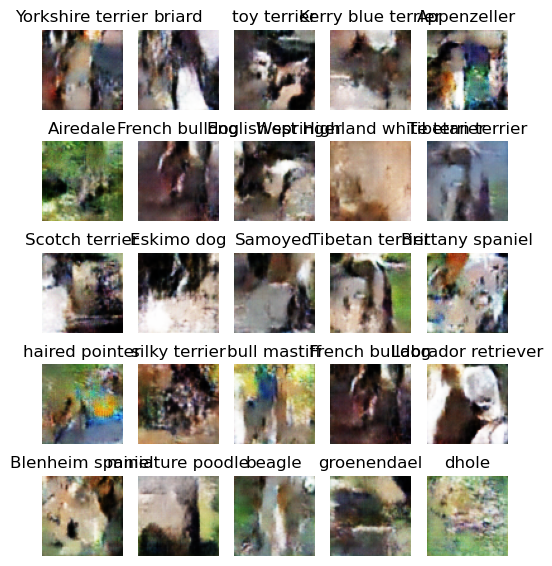

  0%|          | 0/129 [00:00<?, ?batch/s]

[Epoch 41/48]
	G_Trn_Loss: 2.1517	D_Trn_Loss: 0.7797	D_Trn_Real: 0.6176	D_Trn_Fake: 0.7175	D_Trn_Acc: 83.03% 
	G_Val_Loss: 1.4108	D_Val_Loss: 0.9316	D_Val_Real: 0.6176	D_Val_Fake: 0.7175	D_Val_Acc: 80.71%


  0%|          | 0/129 [00:00<?, ?batch/s]

[Epoch 42/48]
	G_Trn_Loss: 2.2849	D_Trn_Loss: 0.7912	D_Trn_Real: 0.6171	D_Trn_Fake: 0.7223	D_Trn_Acc: 82.69% 
	G_Val_Loss: 1.4786	D_Val_Loss: 0.9401	D_Val_Real: 0.6171	D_Val_Fake: 0.7223	D_Val_Acc: 79.84%


  0%|          | 0/129 [00:00<?, ?batch/s]

[Epoch 43/48]
	G_Trn_Loss: 2.2094	D_Trn_Loss: 0.7886	D_Trn_Real: 0.5331	D_Trn_Fake: 0.7709	D_Trn_Acc: 83.58% 
	G_Val_Loss: 1.8504	D_Val_Loss: 1.0938	D_Val_Real: 0.5331	D_Val_Fake: 0.7709	D_Val_Acc: 72.53%


  0%|          | 0/129 [00:00<?, ?batch/s]

[Epoch 44/48]
	G_Trn_Loss: 2.2347	D_Trn_Loss: 0.8177	D_Trn_Real: 0.3987	D_Trn_Fake: 0.8794	D_Trn_Acc: 81.90% 
	G_Val_Loss: 2.5625	D_Val_Loss: 1.3268	D_Val_Real: 0.3987	D_Val_Fake: 0.8794	D_Val_Acc: 66.47%


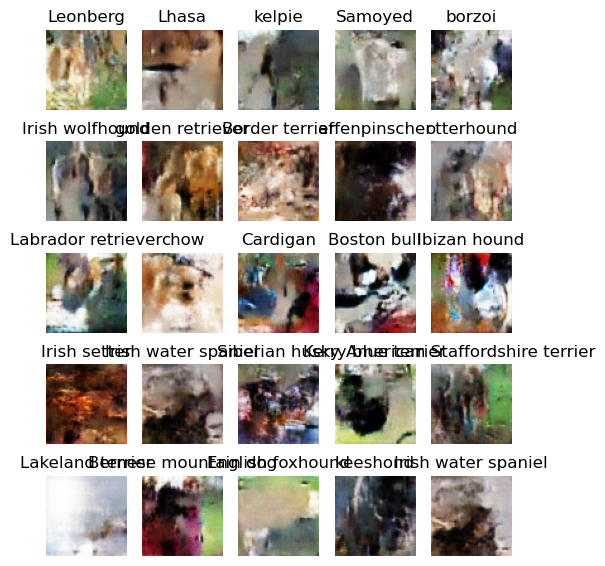

  0%|          | 0/129 [00:00<?, ?batch/s]

[Epoch 45/48]
	G_Trn_Loss: 2.1384	D_Trn_Loss: 0.7943	D_Trn_Real: 0.7465	D_Trn_Fake: 0.5596	D_Trn_Acc: 82.96% 
	G_Val_Loss: 0.8980	D_Val_Loss: 0.9779	D_Val_Real: 0.7465	D_Val_Fake: 0.5596	D_Val_Acc: 75.80%


  0%|          | 0/129 [00:00<?, ?batch/s]

[Epoch 46/48]
	G_Trn_Loss: 2.1609	D_Trn_Loss: 0.7716	D_Trn_Real: 0.5646	D_Trn_Fake: 0.7348	D_Trn_Acc: 83.53% 
	G_Val_Loss: 1.5484	D_Val_Loss: 1.0375	D_Val_Real: 0.5646	D_Val_Fake: 0.7348	D_Val_Acc: 77.43%


  0%|          | 0/129 [00:00<?, ?batch/s]

[Epoch 47/48]
	G_Trn_Loss: 2.1950	D_Trn_Loss: 0.8126	D_Trn_Real: 0.6115	D_Trn_Fake: 0.7824	D_Trn_Acc: 82.11% 
	G_Val_Loss: 1.7140	D_Val_Loss: 0.8499	D_Val_Real: 0.6115	D_Val_Fake: 0.7824	D_Val_Acc: 82.93%


  0%|          | 0/129 [00:00<?, ?batch/s]

[Epoch 48/48]
	G_Trn_Loss: 2.1833	D_Trn_Loss: 0.7953	D_Trn_Real: 0.6238	D_Trn_Fake: 0.7111	D_Trn_Acc: 82.74% 
	G_Val_Loss: 1.4345	D_Val_Loss: 0.9523	D_Val_Real: 0.6238	D_Val_Fake: 0.7111	D_Val_Acc: 79.46%


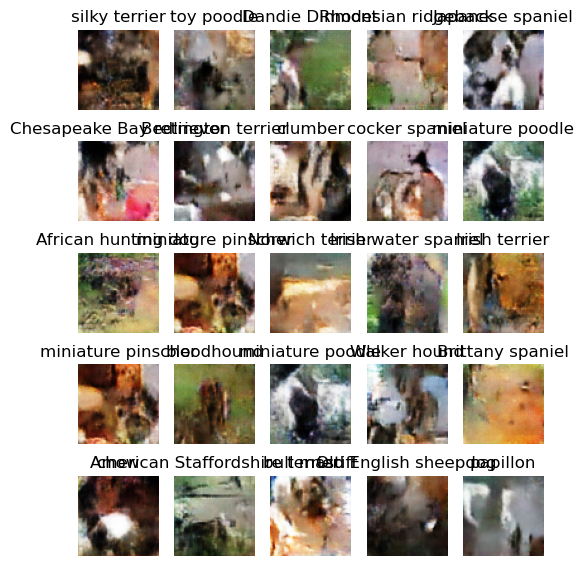

In [78]:
g_stats, d_stats = train(
    generator,
    discriminator,
    train_loader,
    val_loader,
    g_optimizer,
    d_optimizer,
    criterion,
    device,
    num_classes=num_classes,
    epochs=epochs,
    plot_frequency=4,
    label_mapper=dogs_mapper,
)

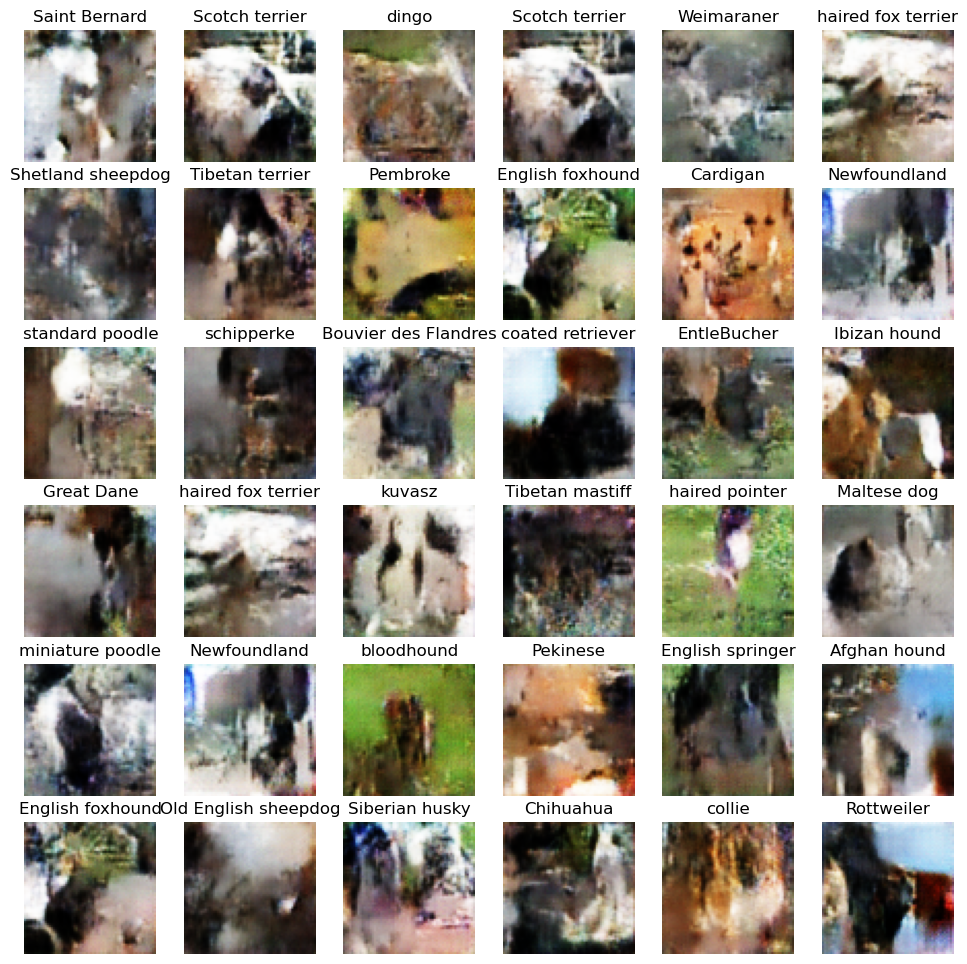

In [79]:
plot_generated_images(
    generator, device=device, num_images=36, denormalize=True, figsize=(12, 12), label_decoder=dogs_mapper, num_classes=num_classes
)

## Extra - [Dogs vs Cats](https://www.kaggle.com/datasets/karakaggle/kaggle-cat-vs-dog-dataset)

In [ ]:
dogs_vs_cats_path = '/pgeoprj2/ciag2024/dados/GAN/cats_dogs'

Number of samples: 24998
Sample shape: torch.Size([3, 64, 64])


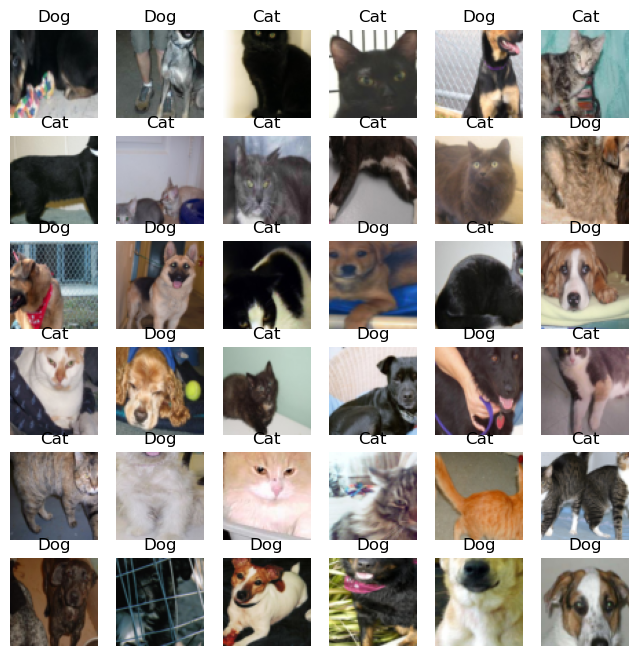

In [36]:
dogsvcats_dataset = ImageFolder(
    dogs_vs_cats_path,
    transform=transforms.Compose(
        [
            transforms.ToImage(),
            transforms.ToDtype(torch.float32, scale=True),
            # center crop images to 64x64 so they are closer to the camera
            transforms.Resize((96, 96)),
            transforms.RandomCrop(64),
            transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
        ]
    ),
)

dogscats_mapper = DatasetLabelMapper(dogsvcats_dataset)

plot_dataset(dogsvcats_dataset, n_cols=6, n_rows=6, denormalize=True, figsize=(8, 8), label_decoder=dogscats_mapper)

Number of samples: 22499
Sample shape: torch.Size([3, 64, 64])


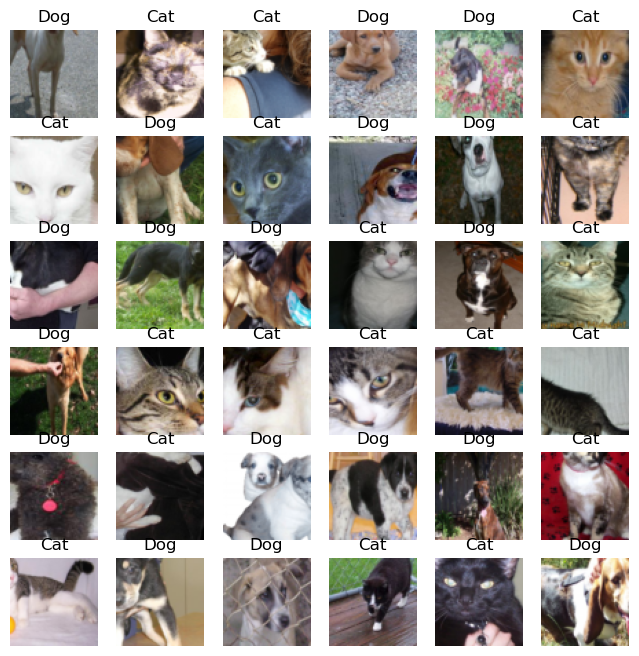

In [37]:
# Separando em dataset de treino e validação
train_dataset, val_dataset = random_split(
    dogsvcats_dataset, [0.9, 0.1], generator=torch.Generator().manual_seed(42)
)

train_loader = DataLoader(
    train_dataset, batch_size=128, shuffle=True, num_workers=4, pin_memory=True
)
val_loader = DataLoader(
    val_dataset, batch_size=128, shuffle=False, num_workers=2, pin_memory=True
)

plot_dataset(train_dataset, n_cols=6, n_rows=6, denormalize=True, figsize=(8, 8), label_decoder=dogscats_mapper)

In [38]:
epochs = 48
latent_dim = 128
num_classes = len(dogsvcats_dataset.classes)
dataset_dim = 3
embedding_size = 32
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

generator = EmbeddingGenerator(latent_dim, output_dim=dataset_dim, embedding_size=embedding_size, n_classes=num_classes)
discriminator = EmbeddingDiscriminator(in_channels=dataset_dim, embedding_size=embedding_size, n_classes=num_classes)

g_optimizer = torch.optim.Adam(generator.parameters(), lr=0.0002, betas=(0.5, 0.999))
d_optimizer = torch.optim.Adam(
    discriminator.parameters(), lr=0.0002, betas=(0.5, 0.999)
)
criterion = nn.BCELoss()

  0%|          | 0/176 [00:00<?, ?batch/s]

[Epoch 1/48]
	G_Trn_Loss: 6.2457	D_Trn_Loss: 0.4579	D_Trn_Real: 0.1878	D_Trn_Fake: 0.4641	D_Trn_Acc: 91.79% 
	G_Val_Loss: 0.8024	D_Val_Loss: 3.4516	D_Val_Real: 0.1878	D_Val_Fake: 0.4641	D_Val_Acc: 30.32%


  0%|          | 0/176 [00:00<?, ?batch/s]

[Epoch 2/48]
	G_Trn_Loss: 5.0094	D_Trn_Loss: 0.6386	D_Trn_Real: 0.3241	D_Trn_Fake: 0.9018	D_Trn_Acc: 87.28% 
	G_Val_Loss: 5.0626	D_Val_Loss: 1.7736	D_Val_Real: 0.3241	D_Val_Fake: 0.9018	D_Val_Acc: 63.38%


  0%|          | 0/176 [00:00<?, ?batch/s]

[Epoch 3/48]
	G_Trn_Loss: 4.9672	D_Trn_Loss: 0.5372	D_Trn_Real: 0.5642	D_Trn_Fake: 0.7930	D_Trn_Acc: 90.04% 
	G_Val_Loss: 2.3635	D_Val_Loss: 1.1106	D_Val_Real: 0.5642	D_Val_Fake: 0.7930	D_Val_Acc: 79.01%


  0%|          | 0/176 [00:00<?, ?batch/s]

[Epoch 4/48]
	G_Trn_Loss: 5.1774	D_Trn_Loss: 0.4783	D_Trn_Real: 0.6176	D_Trn_Fake: 0.7098	D_Trn_Acc: 92.00% 
	G_Val_Loss: 1.3840	D_Val_Loss: 1.1056	D_Val_Real: 0.6176	D_Val_Fake: 0.7098	D_Val_Acc: 78.74%


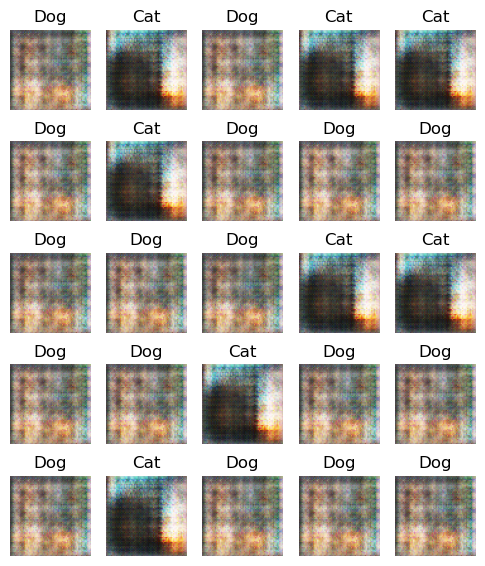

  0%|          | 0/176 [00:00<?, ?batch/s]

[Epoch 5/48]
	G_Trn_Loss: 5.2172	D_Trn_Loss: 0.3717	D_Trn_Real: 0.7132	D_Trn_Fake: 0.6867	D_Trn_Acc: 94.08% 
	G_Val_Loss: 1.2234	D_Val_Loss: 0.8449	D_Val_Real: 0.7132	D_Val_Fake: 0.6867	D_Val_Acc: 86.02%


  0%|          | 0/176 [00:00<?, ?batch/s]

[Epoch 6/48]
	G_Trn_Loss: 4.6061	D_Trn_Loss: 0.6077	D_Trn_Real: 0.1442	D_Trn_Fake: 0.9728	D_Trn_Acc: 88.01% 
	G_Val_Loss: 4.3406	D_Val_Loss: 2.9029	D_Val_Real: 0.1442	D_Val_Fake: 0.9728	D_Val_Acc: 53.31%


  0%|          | 0/176 [00:00<?, ?batch/s]

[Epoch 7/48]
	G_Trn_Loss: 4.1998	D_Trn_Loss: 0.6354	D_Trn_Real: 0.4923	D_Trn_Fake: 0.8167	D_Trn_Acc: 87.19% 
	G_Val_Loss: 1.9761	D_Val_Loss: 1.1166	D_Val_Real: 0.4923	D_Val_Fake: 0.8167	D_Val_Acc: 72.18%


  0%|          | 0/176 [00:00<?, ?batch/s]

[Epoch 8/48]
	G_Trn_Loss: 3.9909	D_Trn_Loss: 0.6521	D_Trn_Real: 0.2945	D_Trn_Fake: 0.8546	D_Trn_Acc: 86.58% 
	G_Val_Loss: 2.2037	D_Val_Loss: 1.7228	D_Val_Real: 0.2945	D_Val_Fake: 0.8546	D_Val_Acc: 58.69%


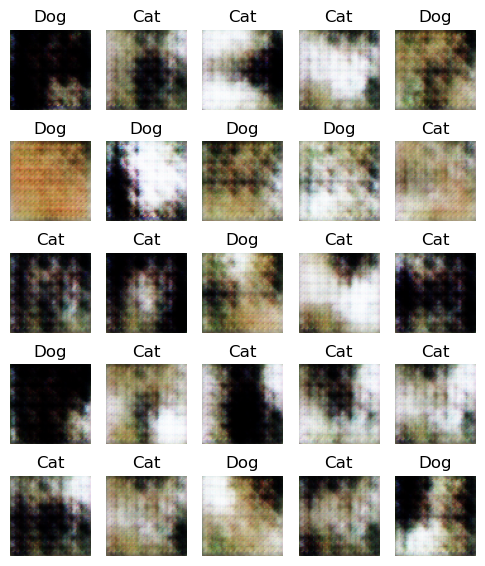

  0%|          | 0/176 [00:00<?, ?batch/s]

[Epoch 9/48]
	G_Trn_Loss: 3.8050	D_Trn_Loss: 0.7025	D_Trn_Real: 0.3654	D_Trn_Fake: 0.7096	D_Trn_Acc: 85.32% 
	G_Val_Loss: 1.4908	D_Val_Loss: 1.7960	D_Val_Real: 0.3654	D_Val_Fake: 0.7096	D_Val_Acc: 57.90%


  0%|          | 0/176 [00:00<?, ?batch/s]

[Epoch 10/48]
	G_Trn_Loss: 3.8320	D_Trn_Loss: 0.6870	D_Trn_Real: 0.5439	D_Trn_Fake: 0.8093	D_Trn_Acc: 86.18% 
	G_Val_Loss: 1.8311	D_Val_Loss: 0.9745	D_Val_Real: 0.5439	D_Val_Fake: 0.8093	D_Val_Acc: 77.49%


  0%|          | 0/176 [00:00<?, ?batch/s]

[Epoch 11/48]
	G_Trn_Loss: 3.8267	D_Trn_Loss: 0.6980	D_Trn_Real: 0.5034	D_Trn_Fake: 0.7525	D_Trn_Acc: 86.14% 
	G_Val_Loss: 1.6222	D_Val_Loss: 1.2000	D_Val_Real: 0.5034	D_Val_Fake: 0.7525	D_Val_Acc: 72.00%


  0%|          | 0/176 [00:00<?, ?batch/s]

[Epoch 12/48]
	G_Trn_Loss: 3.8581	D_Trn_Loss: 0.7224	D_Trn_Real: 0.5979	D_Trn_Fake: 0.7183	D_Trn_Acc: 84.80% 
	G_Val_Loss: 1.4506	D_Val_Loss: 1.0310	D_Val_Real: 0.5979	D_Val_Fake: 0.7183	D_Val_Acc: 77.37%


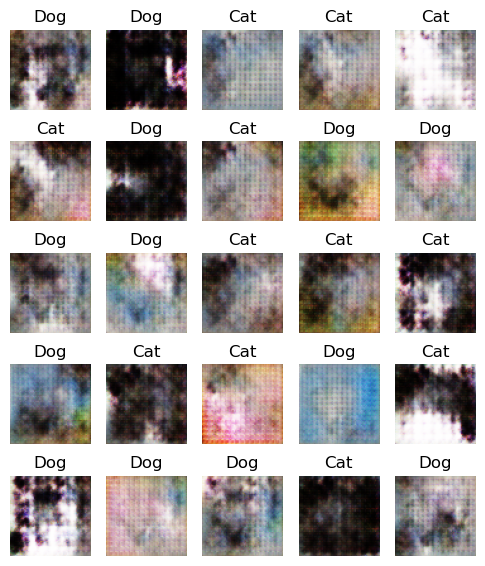

  0%|          | 0/176 [00:00<?, ?batch/s]

[Epoch 13/48]
	G_Trn_Loss: 3.6351	D_Trn_Loss: 0.7286	D_Trn_Real: 0.7102	D_Trn_Fake: 0.7623	D_Trn_Acc: 84.31% 
	G_Val_Loss: 1.7516	D_Val_Loss: 0.7014	D_Val_Real: 0.7102	D_Val_Fake: 0.7623	D_Val_Acc: 87.38%


  0%|          | 0/176 [00:00<?, ?batch/s]

[Epoch 14/48]
	G_Trn_Loss: 3.3863	D_Trn_Loss: 0.7903	D_Trn_Real: 0.6953	D_Trn_Fake: 0.7721	D_Trn_Acc: 82.29% 
	G_Val_Loss: 1.7259	D_Val_Loss: 0.7355	D_Val_Real: 0.6953	D_Val_Fake: 0.7721	D_Val_Acc: 86.04%


  0%|          | 0/176 [00:00<?, ?batch/s]

[Epoch 15/48]
	G_Trn_Loss: 3.0601	D_Trn_Loss: 0.8362	D_Trn_Real: 0.4508	D_Trn_Fake: 0.9058	D_Trn_Acc: 80.96% 
	G_Val_Loss: 2.8238	D_Val_Loss: 1.1220	D_Val_Real: 0.4508	D_Val_Fake: 0.9058	D_Val_Acc: 70.28%


  0%|          | 0/176 [00:00<?, ?batch/s]

[Epoch 16/48]
	G_Trn_Loss: 3.0924	D_Trn_Loss: 0.8495	D_Trn_Real: 0.5301	D_Trn_Fake: 0.6283	D_Trn_Acc: 80.17% 
	G_Val_Loss: 1.1606	D_Val_Loss: 1.3009	D_Val_Real: 0.5301	D_Val_Fake: 0.6283	D_Val_Acc: 64.56%


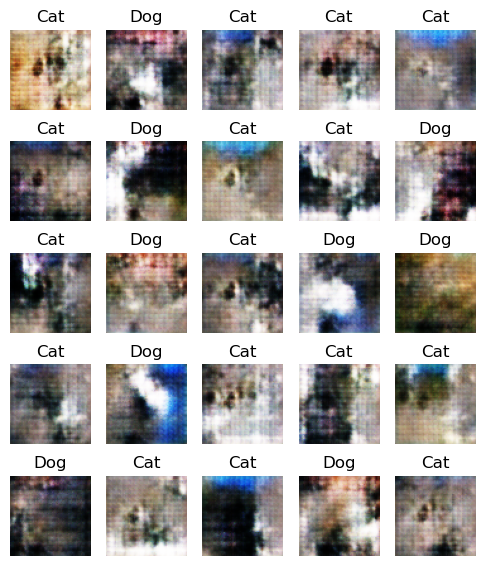

  0%|          | 0/176 [00:00<?, ?batch/s]

[Epoch 17/48]
	G_Trn_Loss: 3.1286	D_Trn_Loss: 0.8999	D_Trn_Real: 0.5904	D_Trn_Fake: 0.7480	D_Trn_Acc: 79.61% 
	G_Val_Loss: 1.7830	D_Val_Loss: 0.9997	D_Val_Real: 0.5904	D_Val_Fake: 0.7480	D_Val_Acc: 75.05%


  0%|          | 0/176 [00:00<?, ?batch/s]

[Epoch 18/48]
	G_Trn_Loss: 3.1610	D_Trn_Loss: 0.8141	D_Trn_Real: 0.7549	D_Trn_Fake: 0.5722	D_Trn_Acc: 81.80% 
	G_Val_Loss: 1.0756	D_Val_Loss: 1.0707	D_Val_Real: 0.7549	D_Val_Fake: 0.5722	D_Val_Acc: 73.71%


  0%|          | 0/176 [00:00<?, ?batch/s]

[Epoch 19/48]
	G_Trn_Loss: 3.3007	D_Trn_Loss: 0.8361	D_Trn_Real: 0.3389	D_Trn_Fake: 0.8449	D_Trn_Acc: 81.34% 
	G_Val_Loss: 2.2783	D_Val_Loss: 1.6570	D_Val_Real: 0.3389	D_Val_Fake: 0.8449	D_Val_Acc: 61.34%


  0%|          | 0/176 [00:00<?, ?batch/s]

[Epoch 20/48]
	G_Trn_Loss: 3.5224	D_Trn_Loss: 0.7629	D_Trn_Real: 0.4033	D_Trn_Fake: 0.7501	D_Trn_Acc: 83.78% 
	G_Val_Loss: 1.7021	D_Val_Loss: 1.5072	D_Val_Real: 0.4033	D_Val_Fake: 0.7501	D_Val_Acc: 61.20%


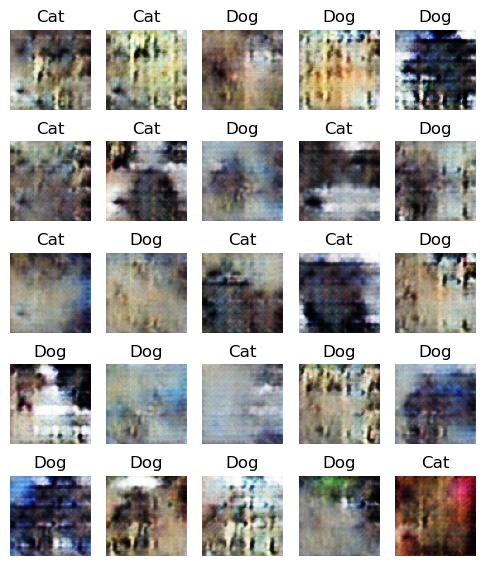

  0%|          | 0/176 [00:00<?, ?batch/s]

[Epoch 21/48]
	G_Trn_Loss: 3.4793	D_Trn_Loss: 0.7616	D_Trn_Real: 0.7016	D_Trn_Fake: 0.6682	D_Trn_Acc: 83.50% 
	G_Val_Loss: 1.3486	D_Val_Loss: 0.8863	D_Val_Real: 0.7016	D_Val_Fake: 0.6682	D_Val_Acc: 80.56%


  0%|          | 0/176 [00:00<?, ?batch/s]

[Epoch 22/48]
	G_Trn_Loss: 3.5377	D_Trn_Loss: 0.7595	D_Trn_Real: 0.5024	D_Trn_Fake: 0.7844	D_Trn_Acc: 83.43% 
	G_Val_Loss: 1.8335	D_Val_Loss: 1.1148	D_Val_Real: 0.5024	D_Val_Fake: 0.7844	D_Val_Acc: 71.43%


  0%|          | 0/176 [00:00<?, ?batch/s]

[Epoch 23/48]
	G_Trn_Loss: 3.7908	D_Trn_Loss: 0.6888	D_Trn_Real: 0.6037	D_Trn_Fake: 0.7070	D_Trn_Acc: 85.02% 
	G_Val_Loss: 1.5443	D_Val_Loss: 1.1026	D_Val_Real: 0.6037	D_Val_Fake: 0.7070	D_Val_Acc: 73.63%


  0%|          | 0/176 [00:00<?, ?batch/s]

[Epoch 24/48]
	G_Trn_Loss: 3.5636	D_Trn_Loss: 0.7379	D_Trn_Real: 0.4269	D_Trn_Fake: 0.8404	D_Trn_Acc: 83.88% 
	G_Val_Loss: 2.4981	D_Val_Loss: 1.3695	D_Val_Real: 0.4269	D_Val_Fake: 0.8404	D_Val_Acc: 65.60%


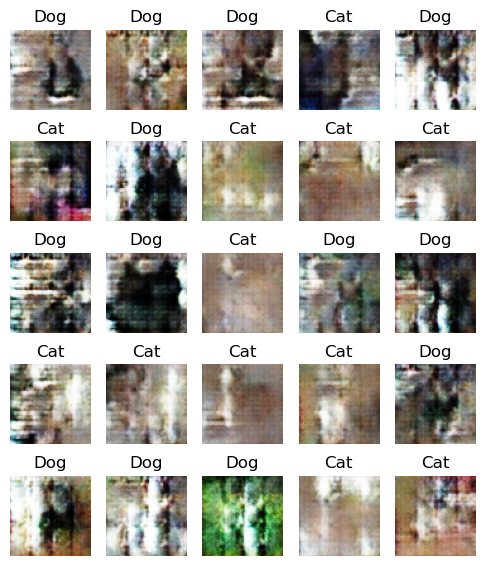

  0%|          | 0/176 [00:00<?, ?batch/s]

[Epoch 25/48]
	G_Trn_Loss: 3.0312	D_Trn_Loss: 0.7871	D_Trn_Real: 0.5663	D_Trn_Fake: 0.7235	D_Trn_Acc: 82.26% 
	G_Val_Loss: 1.5649	D_Val_Loss: 1.0571	D_Val_Real: 0.5663	D_Val_Fake: 0.7235	D_Val_Acc: 74.01%


  0%|          | 0/176 [00:00<?, ?batch/s]

[Epoch 26/48]
	G_Trn_Loss: 2.6580	D_Trn_Loss: 0.8353	D_Trn_Real: 0.5131	D_Trn_Fake: 0.6390	D_Trn_Acc: 81.18% 
	G_Val_Loss: 1.2115	D_Val_Loss: 1.3269	D_Val_Real: 0.5131	D_Val_Fake: 0.6390	D_Val_Acc: 62.96%


  0%|          | 0/176 [00:00<?, ?batch/s]

[Epoch 27/48]
	G_Trn_Loss: 2.7985	D_Trn_Loss: 0.7917	D_Trn_Real: 0.7042	D_Trn_Fake: 0.5210	D_Trn_Acc: 82.13% 
	G_Val_Loss: 0.8440	D_Val_Loss: 1.1376	D_Val_Real: 0.7042	D_Val_Fake: 0.5210	D_Val_Acc: 69.18%


  0%|          | 0/176 [00:00<?, ?batch/s]

[Epoch 28/48]
	G_Trn_Loss: 2.8429	D_Trn_Loss: 0.7726	D_Trn_Real: 0.3116	D_Trn_Fake: 0.8200	D_Trn_Acc: 83.00% 
	G_Val_Loss: 2.0371	D_Val_Loss: 1.6488	D_Val_Real: 0.3116	D_Val_Fake: 0.8200	D_Val_Acc: 57.25%


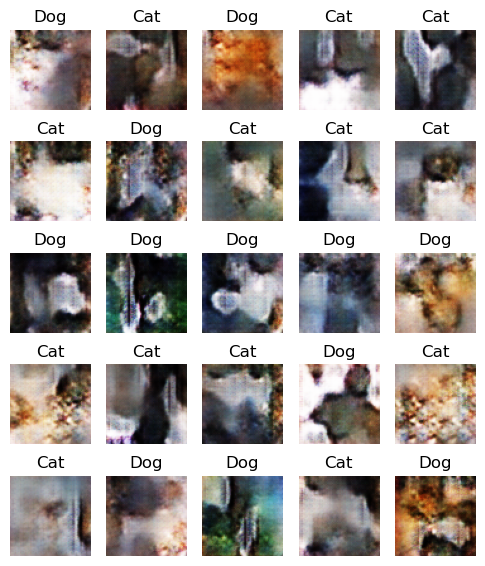

  0%|          | 0/176 [00:00<?, ?batch/s]

[Epoch 29/48]
	G_Trn_Loss: 2.9339	D_Trn_Loss: 0.7046	D_Trn_Real: 0.7354	D_Trn_Fake: 0.5617	D_Trn_Acc: 84.99% 
	G_Val_Loss: 1.0124	D_Val_Loss: 1.0452	D_Val_Real: 0.7354	D_Val_Fake: 0.5617	D_Val_Acc: 74.24%


  0%|          | 0/176 [00:00<?, ?batch/s]

[Epoch 30/48]
	G_Trn_Loss: 2.9675	D_Trn_Loss: 0.7555	D_Trn_Real: 0.4379	D_Trn_Fake: 0.7833	D_Trn_Acc: 83.41% 
	G_Val_Loss: 1.7831	D_Val_Loss: 1.2521	D_Val_Real: 0.4379	D_Val_Fake: 0.7833	D_Val_Acc: 65.96%


  0%|          | 0/176 [00:00<?, ?batch/s]

[Epoch 31/48]
	G_Trn_Loss: 2.8578	D_Trn_Loss: 0.6858	D_Trn_Real: 0.3929	D_Trn_Fake: 0.8004	D_Trn_Acc: 86.61% 
	G_Val_Loss: 1.8881	D_Val_Loss: 1.3540	D_Val_Real: 0.3929	D_Val_Fake: 0.8004	D_Val_Acc: 62.14%


  0%|          | 0/176 [00:00<?, ?batch/s]

[Epoch 32/48]
	G_Trn_Loss: 2.8028	D_Trn_Loss: 0.6805	D_Trn_Real: 0.4364	D_Trn_Fake: 0.8253	D_Trn_Acc: 86.57% 
	G_Val_Loss: 2.1049	D_Val_Loss: 1.2263	D_Val_Real: 0.4364	D_Val_Fake: 0.8253	D_Val_Acc: 67.42%


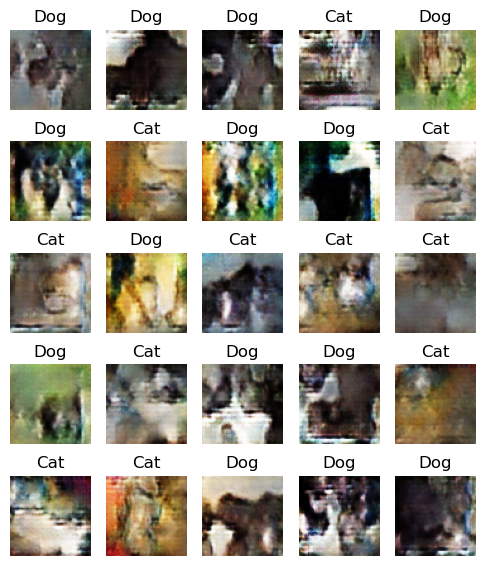

  0%|          | 0/176 [00:00<?, ?batch/s]

[Epoch 33/48]
	G_Trn_Loss: 2.9800	D_Trn_Loss: 0.7013	D_Trn_Real: 0.5297	D_Trn_Fake: 0.6345	D_Trn_Acc: 84.75% 
	G_Val_Loss: 1.1980	D_Val_Loss: 1.2641	D_Val_Real: 0.5297	D_Val_Fake: 0.6345	D_Val_Acc: 64.80%


  0%|          | 0/176 [00:00<?, ?batch/s]

[Epoch 34/48]
	G_Trn_Loss: 3.0263	D_Trn_Loss: 0.7589	D_Trn_Real: 0.4278	D_Trn_Fake: 0.7968	D_Trn_Acc: 83.26% 
	G_Val_Loss: 1.8531	D_Val_Loss: 1.2555	D_Val_Real: 0.4278	D_Val_Fake: 0.7968	D_Val_Acc: 65.28%


  0%|          | 0/176 [00:00<?, ?batch/s]

[Epoch 35/48]
	G_Trn_Loss: 2.8024	D_Trn_Loss: 0.6882	D_Trn_Real: 0.6500	D_Trn_Fake: 0.5583	D_Trn_Acc: 85.59% 
	G_Val_Loss: 0.9674	D_Val_Loss: 1.1701	D_Val_Real: 0.6500	D_Val_Fake: 0.5583	D_Val_Acc: 69.87%


  0%|          | 0/176 [00:00<?, ?batch/s]

[Epoch 36/48]
	G_Trn_Loss: 2.6732	D_Trn_Loss: 0.6988	D_Trn_Real: 0.4814	D_Trn_Fake: 0.7456	D_Trn_Acc: 85.55% 
	G_Val_Loss: 1.6101	D_Val_Loss: 1.2049	D_Val_Real: 0.4814	D_Val_Fake: 0.7456	D_Val_Acc: 67.32%


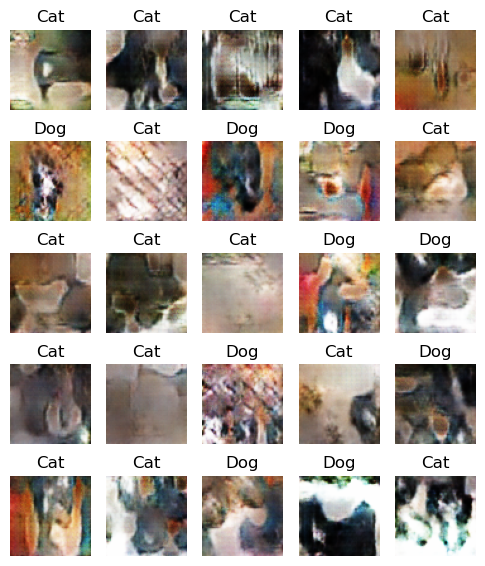

  0%|          | 0/176 [00:00<?, ?batch/s]

[Epoch 37/48]
	G_Trn_Loss: 2.8073	D_Trn_Loss: 0.7672	D_Trn_Real: 0.3538	D_Trn_Fake: 0.8015	D_Trn_Acc: 84.18% 
	G_Val_Loss: 1.8772	D_Val_Loss: 1.5242	D_Val_Real: 0.3538	D_Val_Fake: 0.8015	D_Val_Acc: 60.00%


  0%|          | 0/176 [00:00<?, ?batch/s]

[Epoch 38/48]
	G_Trn_Loss: 2.8108	D_Trn_Loss: 0.6619	D_Trn_Real: 0.4746	D_Trn_Fake: 0.7164	D_Trn_Acc: 87.50% 
	G_Val_Loss: 1.4801	D_Val_Loss: 1.2463	D_Val_Real: 0.4746	D_Val_Fake: 0.7164	D_Val_Acc: 65.40%


  0%|          | 0/176 [00:00<?, ?batch/s]

[Epoch 39/48]
	G_Trn_Loss: 2.9264	D_Trn_Loss: 0.6111	D_Trn_Real: 0.1858	D_Trn_Fake: 0.9058	D_Trn_Acc: 87.51% 
	G_Val_Loss: 2.8637	D_Val_Loss: 2.1901	D_Val_Real: 0.1858	D_Val_Fake: 0.9058	D_Val_Acc: 52.40%


  0%|          | 0/176 [00:00<?, ?batch/s]

[Epoch 40/48]
	G_Trn_Loss: 2.9761	D_Trn_Loss: 0.6602	D_Trn_Real: 0.4382	D_Trn_Fake: 0.7265	D_Trn_Acc: 86.07% 
	G_Val_Loss: 1.5194	D_Val_Loss: 1.3343	D_Val_Real: 0.4382	D_Val_Fake: 0.7265	D_Val_Acc: 63.94%


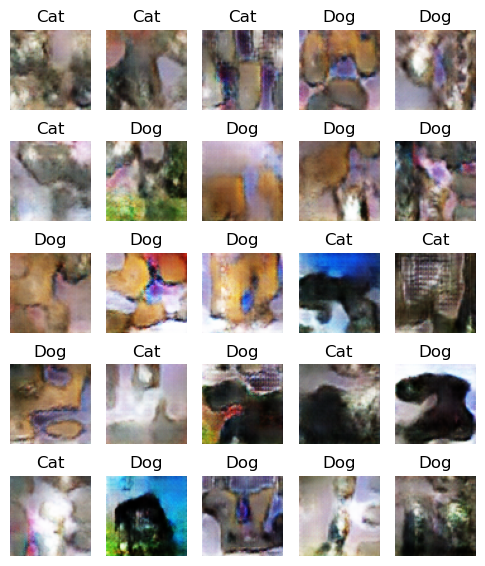

  0%|          | 0/176 [00:00<?, ?batch/s]

[Epoch 41/48]
	G_Trn_Loss: 3.0472	D_Trn_Loss: 0.6292	D_Trn_Real: 0.4623	D_Trn_Fake: 0.7111	D_Trn_Acc: 86.71% 
	G_Val_Loss: 1.4619	D_Val_Loss: 1.2813	D_Val_Real: 0.4623	D_Val_Fake: 0.7111	D_Val_Acc: 63.88%


  0%|          | 0/176 [00:00<?, ?batch/s]

[Epoch 42/48]
	G_Trn_Loss: 2.7595	D_Trn_Loss: 0.6642	D_Trn_Real: 0.4828	D_Trn_Fake: 0.7197	D_Trn_Acc: 87.83% 
	G_Val_Loss: 1.5331	D_Val_Loss: 1.2319	D_Val_Real: 0.4828	D_Val_Fake: 0.7197	D_Val_Acc: 66.87%


  0%|          | 0/176 [00:00<?, ?batch/s]

[Epoch 43/48]
	G_Trn_Loss: 2.8690	D_Trn_Loss: 0.6605	D_Trn_Real: 0.6376	D_Trn_Fake: 0.5548	D_Trn_Acc: 86.35% 
	G_Val_Loss: 0.9683	D_Val_Loss: 1.2285	D_Val_Real: 0.6376	D_Val_Fake: 0.5548	D_Val_Acc: 67.13%


  0%|          | 0/176 [00:00<?, ?batch/s]

[Epoch 44/48]
	G_Trn_Loss: 2.8393	D_Trn_Loss: 0.6345	D_Trn_Real: 0.6390	D_Trn_Fake: 0.5799	D_Trn_Acc: 86.66% 
	G_Val_Loss: 1.0090	D_Val_Loss: 1.1371	D_Val_Real: 0.6390	D_Val_Fake: 0.5799	D_Val_Acc: 69.66%


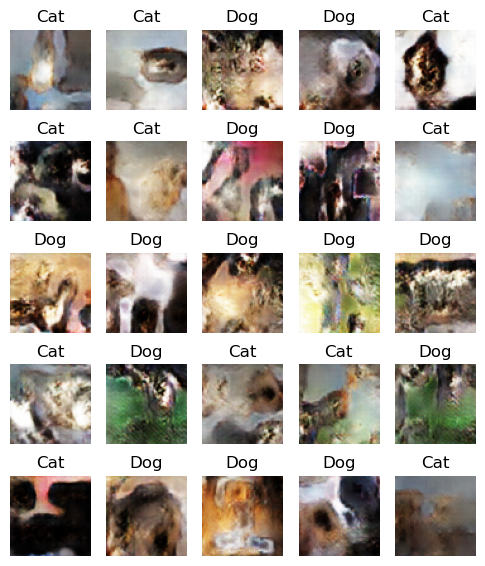

  0%|          | 0/176 [00:00<?, ?batch/s]

[Epoch 45/48]
	G_Trn_Loss: 2.7744	D_Trn_Loss: 0.7313	D_Trn_Real: 0.6922	D_Trn_Fake: 0.4964	D_Trn_Acc: 85.97% 
	G_Val_Loss: 0.8213	D_Val_Loss: 1.2529	D_Val_Real: 0.6922	D_Val_Fake: 0.4964	D_Val_Acc: 65.32%


  0%|          | 0/176 [00:00<?, ?batch/s]

[Epoch 46/48]
	G_Trn_Loss: 2.6782	D_Trn_Loss: 0.5949	D_Trn_Real: 0.4548	D_Trn_Fake: 0.7189	D_Trn_Acc: 88.65% 
	G_Val_Loss: 1.5011	D_Val_Loss: 1.2868	D_Val_Real: 0.4548	D_Val_Fake: 0.7189	D_Val_Acc: 64.08%


  0%|          | 0/176 [00:00<?, ?batch/s]

[Epoch 47/48]
	G_Trn_Loss: 2.7615	D_Trn_Loss: 0.6114	D_Trn_Real: 0.5145	D_Trn_Fake: 0.7124	D_Trn_Acc: 87.62% 
	G_Val_Loss: 1.4376	D_Val_Loss: 1.1392	D_Val_Real: 0.5145	D_Val_Fake: 0.7124	D_Val_Acc: 69.72%


  0%|          | 0/176 [00:00<?, ?batch/s]

[Epoch 48/48]
	G_Trn_Loss: 2.8127	D_Trn_Loss: 0.5890	D_Trn_Real: 0.7313	D_Trn_Fake: 0.5103	D_Trn_Acc: 88.92% 
	G_Val_Loss: 0.8464	D_Val_Loss: 1.1229	D_Val_Real: 0.7313	D_Val_Fake: 0.5103	D_Val_Acc: 69.63%


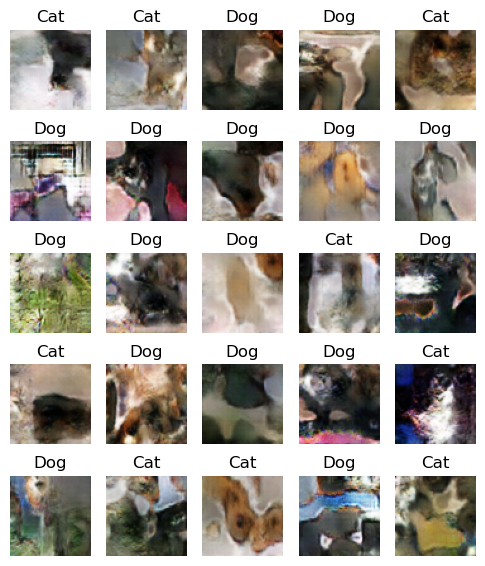

In [39]:
g_stats, d_stats = train(
    generator,
    discriminator,
    train_loader,
    val_loader,
    g_optimizer,
    d_optimizer,
    criterion,
    device,
    num_classes=num_classes,
    epochs=epochs,
    plot_frequency=4,
    label_mapper=dogscats_mapper,
)

## Extra - [Muffins vs Chihuahuas](https://www.kaggle.com/datasets/samuelcortinhas/muffin-vs-chihuahua-image-classification)

In [ ]:
import os
dogs_muffins_path = '/pgeoprj2/ciag2024/dados/GAN/dogs_muffins'

Number of samples: 4733
Sample shape: torch.Size([3, 64, 64])


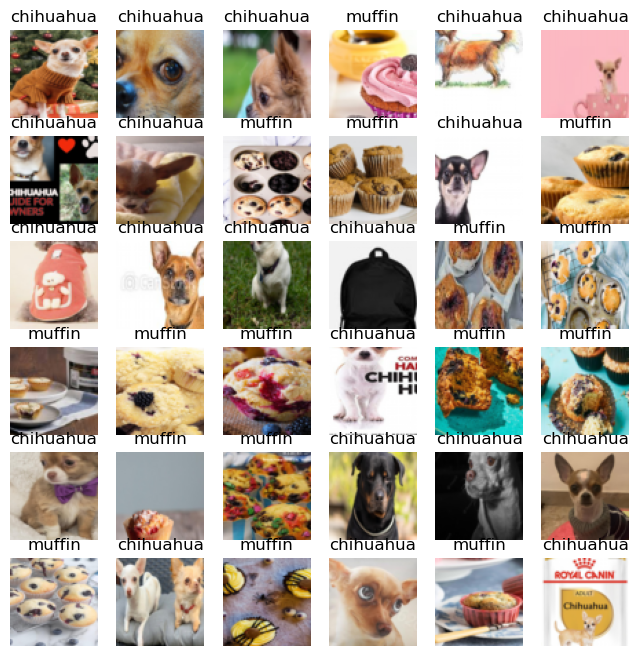

Number of samples: 1184
Sample shape: torch.Size([3, 64, 64])


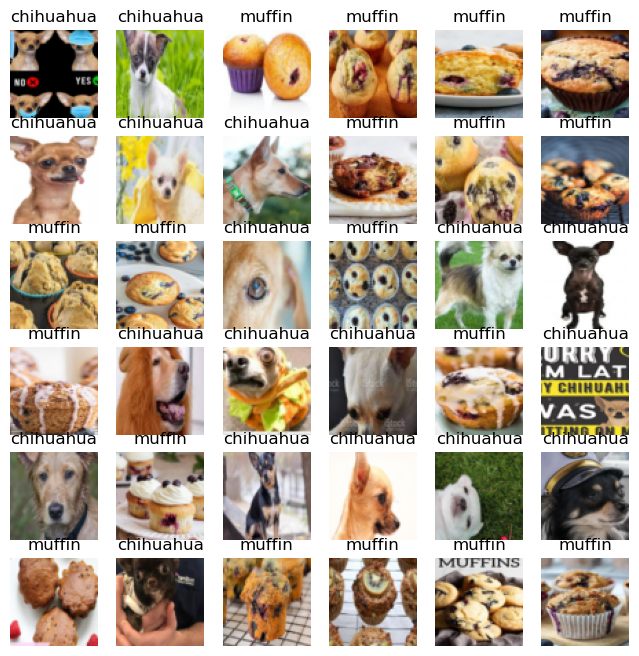

In [44]:
muffins_dataset_train = ImageFolder(
    os.path.join(dogs_muffins_path, 'train'),
    transform=transforms.Compose(
        [
            transforms.ToImage(),
            transforms.ToDtype(torch.float32, scale=True),
            # center crop images to 64x64 so they are closer to the camera
            transforms.Resize((96, 96)),
            transforms.RandomCrop(64),
            transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
        ]
    ),
)

muffins_dataset_test = ImageFolder(
    os.path.join(dogs_muffins_path, 'test'),
    transform=transforms.Compose(
        [
            transforms.ToImage(),
            transforms.ToDtype(torch.float32, scale=True),
            # center crop images to 64x64 so they are closer to the camera
            transforms.Resize((96, 96)),
            transforms.CenterCrop(64),
            transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
        ]
    ),
)

muffin_mapper = DatasetLabelMapper(muffins_dataset_train)

plot_dataset(muffins_dataset_train, n_cols=6, n_rows=6, denormalize=True, figsize=(8, 8), label_decoder=muffin_mapper)
plot_dataset(muffins_dataset_test, n_cols=6, n_rows=6, denormalize=True, figsize=(8, 8), label_decoder=muffin_mapper)

In [51]:
# Separando em dataset de treino e validação
train_loader = DataLoader(
    muffins_dataset_train, batch_size=128, shuffle=True, num_workers=2,
)
val_loader = DataLoader(
    muffins_dataset_test, batch_size=128, shuffle=False, num_workers=1,
)

In [52]:
epochs = 48
latent_dim = 120
num_classes = len(dogsvcats_dataset.classes)
dataset_dim = 3
embedding_size = 8
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

generator = EmbeddingGenerator(latent_dim, output_dim=dataset_dim, embedding_size=embedding_size, n_classes=num_classes)
discriminator = EmbeddingDiscriminator(in_channels=dataset_dim, embedding_size=embedding_size, n_classes=num_classes)

g_optimizer = torch.optim.Adam(generator.parameters(), lr=0.0002, betas=(0.5, 0.999))
d_optimizer = torch.optim.Adam(
    discriminator.parameters(), lr=0.0002, betas=(0.5, 0.999)
)
criterion = nn.BCELoss()

  0%|          | 0/37 [00:00<?, ?batch/s]

[Epoch 1/48]
	G_Trn_Loss: 7.2017	D_Trn_Loss: 0.4391	D_Trn_Real: 0.1618	D_Trn_Fake: 0.9988	D_Trn_Acc: 92.46% 
	G_Val_Loss: 7.4201	D_Val_Loss: 2.8699	D_Val_Real: 0.1618	D_Val_Fake: 0.9988	D_Val_Acc: 54.41%


  0%|          | 0/37 [00:00<?, ?batch/s]

[Epoch 2/48]
	G_Trn_Loss: 6.9060	D_Trn_Loss: 0.6355	D_Trn_Real: 0.3750	D_Trn_Fake: 0.7299	D_Trn_Acc: 86.08% 
	G_Val_Loss: 1.4516	D_Val_Loss: 1.4709	D_Val_Real: 0.3750	D_Val_Fake: 0.7299	D_Val_Acc: 59.02%


  0%|          | 0/37 [00:00<?, ?batch/s]

[Epoch 3/48]
	G_Trn_Loss: 3.1066	D_Trn_Loss: 0.9120	D_Trn_Real: 0.2699	D_Trn_Fake: 0.8702	D_Trn_Acc: 76.75% 
	G_Val_Loss: 2.1778	D_Val_Loss: 1.6487	D_Val_Real: 0.2699	D_Val_Fake: 0.8702	D_Val_Acc: 55.16%


  0%|          | 0/37 [00:00<?, ?batch/s]

[Epoch 4/48]
	G_Trn_Loss: 2.6779	D_Trn_Loss: 0.8658	D_Trn_Real: 0.6719	D_Trn_Fake: 0.6445	D_Trn_Acc: 80.41% 
	G_Val_Loss: 1.1586	D_Val_Loss: 0.9351	D_Val_Real: 0.6719	D_Val_Fake: 0.6445	D_Val_Acc: 80.16%


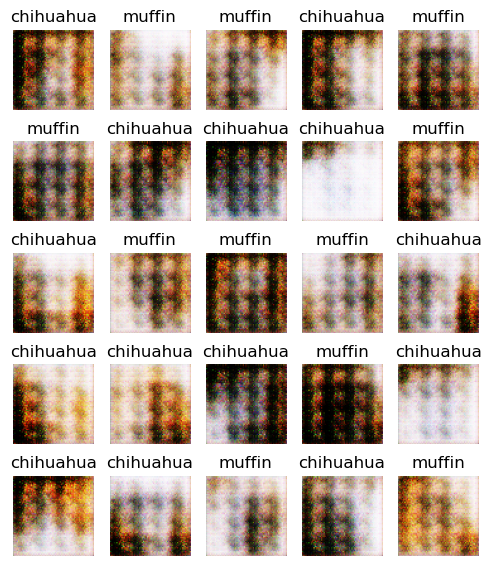

  0%|          | 0/37 [00:00<?, ?batch/s]

[Epoch 5/48]
	G_Trn_Loss: 2.1994	D_Trn_Loss: 1.0124	D_Trn_Real: 0.6072	D_Trn_Fake: 0.5535	D_Trn_Acc: 74.92% 
	G_Val_Loss: 0.8454	D_Val_Loss: 1.1605	D_Val_Real: 0.6072	D_Val_Fake: 0.5535	D_Val_Acc: 70.70%


  0%|          | 0/37 [00:00<?, ?batch/s]

[Epoch 6/48]
	G_Trn_Loss: 2.3010	D_Trn_Loss: 1.0759	D_Trn_Real: 0.4525	D_Trn_Fake: 0.5250	D_Trn_Acc: 73.30% 
	G_Val_Loss: 0.7993	D_Val_Loss: 1.5995	D_Val_Real: 0.4525	D_Val_Fake: 0.5250	D_Val_Acc: 47.38%


  0%|          | 0/37 [00:00<?, ?batch/s]

[Epoch 7/48]
	G_Trn_Loss: 2.3937	D_Trn_Loss: 0.9050	D_Trn_Real: 0.3892	D_Trn_Fake: 0.5929	D_Trn_Acc: 79.54% 
	G_Val_Loss: 0.9582	D_Val_Loss: 1.7103	D_Val_Real: 0.3892	D_Val_Fake: 0.5929	D_Val_Acc: 52.54%


  0%|          | 0/37 [00:00<?, ?batch/s]

[Epoch 8/48]
	G_Trn_Loss: 2.6300	D_Trn_Loss: 0.9578	D_Trn_Real: 0.5633	D_Trn_Fake: 0.6382	D_Trn_Acc: 78.11% 
	G_Val_Loss: 1.1270	D_Val_Loss: 1.1064	D_Val_Real: 0.5633	D_Val_Fake: 0.6382	D_Val_Acc: 73.52%


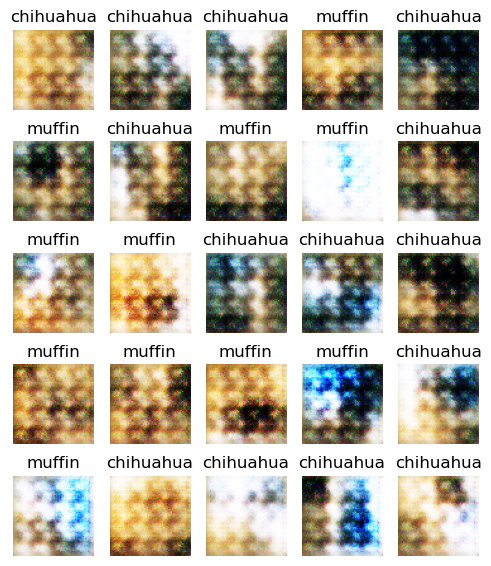

  0%|          | 0/37 [00:00<?, ?batch/s]

[Epoch 9/48]
	G_Trn_Loss: 2.8023	D_Trn_Loss: 0.8205	D_Trn_Real: 0.5657	D_Trn_Fake: 0.5281	D_Trn_Acc: 82.56% 
	G_Val_Loss: 0.7911	D_Val_Loss: 1.3001	D_Val_Real: 0.5657	D_Val_Fake: 0.5281	D_Val_Acc: 61.95%


  0%|          | 0/37 [00:00<?, ?batch/s]

[Epoch 10/48]
	G_Trn_Loss: 3.0948	D_Trn_Loss: 0.8123	D_Trn_Real: 0.3112	D_Trn_Fake: 0.7295	D_Trn_Acc: 83.59% 
	G_Val_Loss: 1.4239	D_Val_Loss: 1.6484	D_Val_Real: 0.3112	D_Val_Fake: 0.7295	D_Val_Acc: 54.22%


  0%|          | 0/37 [00:00<?, ?batch/s]

[Epoch 11/48]
	G_Trn_Loss: 2.8246	D_Trn_Loss: 0.8292	D_Trn_Real: 0.1808	D_Trn_Fake: 0.9076	D_Trn_Acc: 79.73% 
	G_Val_Loss: 2.6296	D_Val_Loss: 2.0573	D_Val_Real: 0.1808	D_Val_Fake: 0.9076	D_Val_Acc: 51.09%


  0%|          | 0/37 [00:00<?, ?batch/s]

[Epoch 12/48]
	G_Trn_Loss: 3.1923	D_Trn_Loss: 0.8639	D_Trn_Real: 0.5205	D_Trn_Fake: 0.6295	D_Trn_Acc: 80.04% 
	G_Val_Loss: 1.0897	D_Val_Loss: 1.2308	D_Val_Real: 0.5205	D_Val_Fake: 0.6295	D_Val_Acc: 66.52%


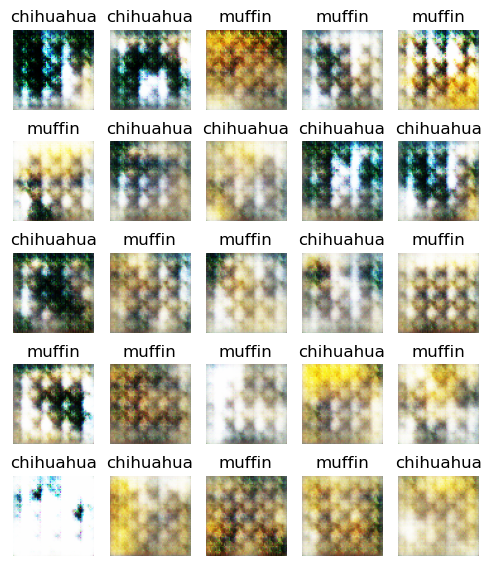

  0%|          | 0/37 [00:00<?, ?batch/s]

[Epoch 13/48]
	G_Trn_Loss: 2.9926	D_Trn_Loss: 0.6610	D_Trn_Real: 0.5756	D_Trn_Fake: 0.3910	D_Trn_Acc: 87.12% 
	G_Val_Loss: 0.5343	D_Val_Loss: 1.6485	D_Val_Real: 0.5756	D_Val_Fake: 0.3910	D_Val_Acc: 44.57%


  0%|          | 0/37 [00:00<?, ?batch/s]

[Epoch 14/48]
	G_Trn_Loss: 3.3432	D_Trn_Loss: 0.6318	D_Trn_Real: 0.2164	D_Trn_Fake: 0.7886	D_Trn_Acc: 87.57% 
	G_Val_Loss: 1.7249	D_Val_Loss: 2.0763	D_Val_Real: 0.2164	D_Val_Fake: 0.7886	D_Val_Acc: 51.76%


  0%|          | 0/37 [00:00<?, ?batch/s]

[Epoch 15/48]
	G_Trn_Loss: 3.2103	D_Trn_Loss: 0.7525	D_Trn_Real: 0.4748	D_Trn_Fake: 0.4685	D_Trn_Acc: 84.24% 
	G_Val_Loss: 0.6869	D_Val_Loss: 1.7519	D_Val_Real: 0.4748	D_Val_Fake: 0.4685	D_Val_Acc: 44.96%


  0%|          | 0/37 [00:00<?, ?batch/s]

[Epoch 16/48]
	G_Trn_Loss: 3.0117	D_Trn_Loss: 0.8960	D_Trn_Real: 0.5316	D_Trn_Fake: 0.8062	D_Trn_Acc: 80.87% 
	G_Val_Loss: 1.9679	D_Val_Loss: 1.0298	D_Val_Real: 0.5316	D_Val_Fake: 0.8062	D_Val_Acc: 74.88%


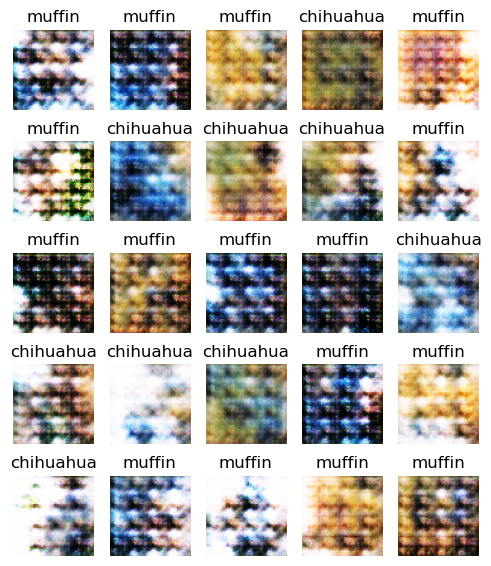

  0%|          | 0/37 [00:00<?, ?batch/s]

[Epoch 17/48]
	G_Trn_Loss: 2.8529	D_Trn_Loss: 0.7949	D_Trn_Real: 0.4715	D_Trn_Fake: 0.6058	D_Trn_Acc: 83.02% 
	G_Val_Loss: 1.0432	D_Val_Loss: 1.3896	D_Val_Real: 0.4715	D_Val_Fake: 0.6058	D_Val_Acc: 56.21%


  0%|          | 0/37 [00:00<?, ?batch/s]

[Epoch 18/48]
	G_Trn_Loss: 2.9529	D_Trn_Loss: 0.7889	D_Trn_Real: 0.1473	D_Trn_Fake: 0.8412	D_Trn_Acc: 82.83% 
	G_Val_Loss: 2.0619	D_Val_Loss: 2.4762	D_Val_Real: 0.1473	D_Val_Fake: 0.8412	D_Val_Acc: 50.82%


  0%|          | 0/37 [00:00<?, ?batch/s]

[Epoch 19/48]
	G_Trn_Loss: 2.8077	D_Trn_Loss: 0.8002	D_Trn_Real: 0.5667	D_Trn_Fake: 0.6814	D_Trn_Acc: 82.48% 
	G_Val_Loss: 1.3194	D_Val_Loss: 1.1008	D_Val_Real: 0.5667	D_Val_Fake: 0.6814	D_Val_Acc: 72.27%


  0%|          | 0/37 [00:00<?, ?batch/s]

[Epoch 20/48]
	G_Trn_Loss: 2.7316	D_Trn_Loss: 0.8133	D_Trn_Real: 0.3893	D_Trn_Fake: 0.7922	D_Trn_Acc: 84.21% 
	G_Val_Loss: 1.7209	D_Val_Loss: 1.3432	D_Val_Real: 0.3893	D_Val_Fake: 0.7922	D_Val_Acc: 63.12%


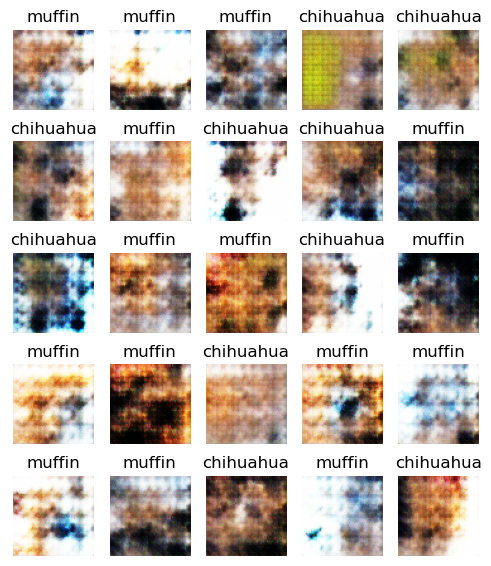

  0%|          | 0/37 [00:00<?, ?batch/s]

[Epoch 21/48]
	G_Trn_Loss: 3.2093	D_Trn_Loss: 0.8407	D_Trn_Real: 0.2458	D_Trn_Fake: 0.8191	D_Trn_Acc: 82.77% 
	G_Val_Loss: 1.8990	D_Val_Loss: 1.9724	D_Val_Real: 0.2458	D_Val_Fake: 0.8191	D_Val_Acc: 55.08%


  0%|          | 0/37 [00:00<?, ?batch/s]

[Epoch 22/48]
	G_Trn_Loss: 3.0815	D_Trn_Loss: 0.8598	D_Trn_Real: 0.3185	D_Trn_Fake: 0.7768	D_Trn_Acc: 80.59% 
	G_Val_Loss: 1.7662	D_Val_Loss: 1.6420	D_Val_Real: 0.3185	D_Val_Fake: 0.7768	D_Val_Acc: 56.64%


  0%|          | 0/37 [00:00<?, ?batch/s]

[Epoch 23/48]
	G_Trn_Loss: 3.0223	D_Trn_Loss: 0.8067	D_Trn_Real: 0.5372	D_Trn_Fake: 0.5625	D_Trn_Acc: 81.29% 
	G_Val_Loss: 0.9178	D_Val_Loss: 1.3562	D_Val_Real: 0.5372	D_Val_Fake: 0.5625	D_Val_Acc: 61.56%


  0%|          | 0/37 [00:00<?, ?batch/s]

[Epoch 24/48]
	G_Trn_Loss: 3.3513	D_Trn_Loss: 0.8822	D_Trn_Real: 0.2839	D_Trn_Fake: 0.8654	D_Trn_Acc: 78.85% 
	G_Val_Loss: 2.2950	D_Val_Loss: 1.7487	D_Val_Real: 0.2839	D_Val_Fake: 0.8654	D_Val_Acc: 56.80%


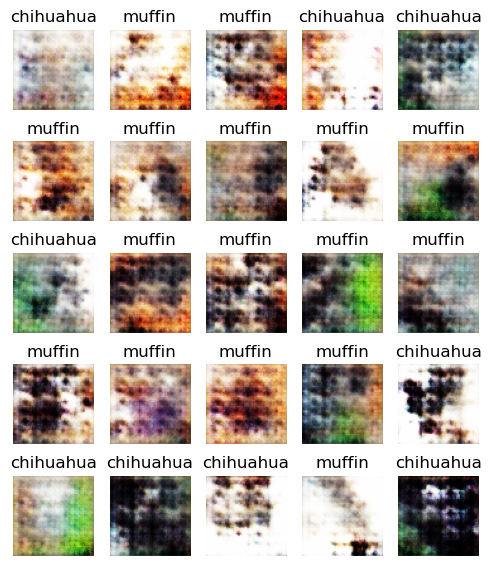

  0%|          | 0/37 [00:00<?, ?batch/s]

[Epoch 25/48]
	G_Trn_Loss: 3.2146	D_Trn_Loss: 0.8546	D_Trn_Real: 0.3382	D_Trn_Fake: 0.8309	D_Trn_Acc: 79.97% 
	G_Val_Loss: 1.9979	D_Val_Loss: 1.5073	D_Val_Real: 0.3382	D_Val_Fake: 0.8309	D_Val_Acc: 60.23%


  0%|          | 0/37 [00:00<?, ?batch/s]

[Epoch 26/48]
	G_Trn_Loss: 3.0078	D_Trn_Loss: 0.7691	D_Trn_Real: 0.5260	D_Trn_Fake: 0.5453	D_Trn_Acc: 84.37% 
	G_Val_Loss: 0.9439	D_Val_Loss: 1.4707	D_Val_Real: 0.5260	D_Val_Fake: 0.5453	D_Val_Acc: 55.66%


  0%|          | 0/37 [00:00<?, ?batch/s]

[Epoch 27/48]
	G_Trn_Loss: 3.1103	D_Trn_Loss: 0.8779	D_Trn_Real: 0.5644	D_Trn_Fake: 0.5994	D_Trn_Acc: 81.32% 
	G_Val_Loss: 1.0711	D_Val_Loss: 1.2915	D_Val_Real: 0.5644	D_Val_Fake: 0.5994	D_Val_Acc: 65.55%


  0%|          | 0/37 [00:00<?, ?batch/s]

[Epoch 28/48]
	G_Trn_Loss: 3.1772	D_Trn_Loss: 0.8623	D_Trn_Real: 0.5456	D_Trn_Fake: 0.8059	D_Trn_Acc: 79.40% 
	G_Val_Loss: 1.8599	D_Val_Loss: 0.9423	D_Val_Real: 0.5456	D_Val_Fake: 0.8059	D_Val_Acc: 77.38%


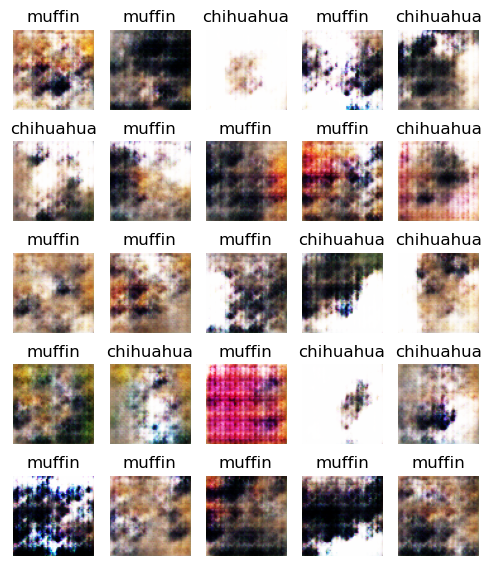

  0%|          | 0/37 [00:00<?, ?batch/s]

[Epoch 29/48]
	G_Trn_Loss: 2.8433	D_Trn_Loss: 0.8667	D_Trn_Real: 0.4098	D_Trn_Fake: 0.6138	D_Trn_Acc: 82.21% 
	G_Val_Loss: 1.0786	D_Val_Loss: 1.6157	D_Val_Real: 0.4098	D_Val_Fake: 0.6138	D_Val_Acc: 53.59%


  0%|          | 0/37 [00:00<?, ?batch/s]

[Epoch 30/48]
	G_Trn_Loss: 2.9005	D_Trn_Loss: 0.7412	D_Trn_Real: 0.4007	D_Trn_Fake: 0.7490	D_Trn_Acc: 85.06% 
	G_Val_Loss: 1.5289	D_Val_Loss: 1.4240	D_Val_Real: 0.4007	D_Val_Fake: 0.7490	D_Val_Acc: 64.14%


  0%|          | 0/37 [00:00<?, ?batch/s]

[Epoch 31/48]
	G_Trn_Loss: 2.9693	D_Trn_Loss: 0.7855	D_Trn_Real: 0.5243	D_Trn_Fake: 0.7618	D_Trn_Acc: 83.06% 
	G_Val_Loss: 1.5896	D_Val_Loss: 1.0441	D_Val_Real: 0.5243	D_Val_Fake: 0.7618	D_Val_Acc: 74.88%


  0%|          | 0/37 [00:00<?, ?batch/s]

[Epoch 32/48]
	G_Trn_Loss: 3.1653	D_Trn_Loss: 0.9339	D_Trn_Real: 0.5189	D_Trn_Fake: 0.7514	D_Trn_Acc: 78.10% 
	G_Val_Loss: 1.5216	D_Val_Loss: 1.0771	D_Val_Real: 0.5189	D_Val_Fake: 0.7514	D_Val_Acc: 73.95%


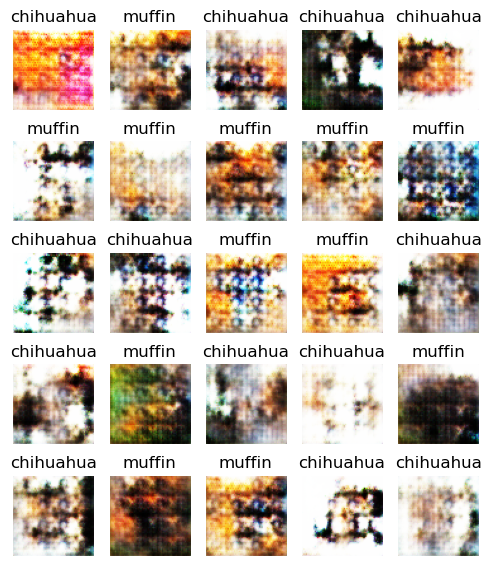

  0%|          | 0/37 [00:00<?, ?batch/s]

[Epoch 33/48]
	G_Trn_Loss: 3.1126	D_Trn_Loss: 0.8221	D_Trn_Real: 0.3881	D_Trn_Fake: 0.8018	D_Trn_Acc: 81.31% 
	G_Val_Loss: 1.8398	D_Val_Loss: 1.3617	D_Val_Real: 0.3881	D_Val_Fake: 0.8018	D_Val_Acc: 62.66%


  0%|          | 0/37 [00:00<?, ?batch/s]

[Epoch 34/48]
	G_Trn_Loss: 3.0489	D_Trn_Loss: 0.8088	D_Trn_Real: 0.3743	D_Trn_Fake: 0.5791	D_Trn_Acc: 83.96% 
	G_Val_Loss: 0.9514	D_Val_Loss: 1.7482	D_Val_Real: 0.3743	D_Val_Fake: 0.5791	D_Val_Acc: 47.97%


  0%|          | 0/37 [00:00<?, ?batch/s]

[Epoch 35/48]
	G_Trn_Loss: 3.3587	D_Trn_Loss: 0.8175	D_Trn_Real: 0.5107	D_Trn_Fake: 0.8222	D_Trn_Acc: 82.97% 
	G_Val_Loss: 2.0008	D_Val_Loss: 1.0434	D_Val_Real: 0.5107	D_Val_Fake: 0.8222	D_Val_Acc: 74.34%


  0%|          | 0/37 [00:00<?, ?batch/s]

[Epoch 36/48]
	G_Trn_Loss: 3.1205	D_Trn_Loss: 0.7178	D_Trn_Real: 0.6829	D_Trn_Fake: 0.5381	D_Trn_Acc: 85.49% 
	G_Val_Loss: 0.8838	D_Val_Loss: 1.1582	D_Val_Real: 0.6829	D_Val_Fake: 0.5381	D_Val_Acc: 69.88%


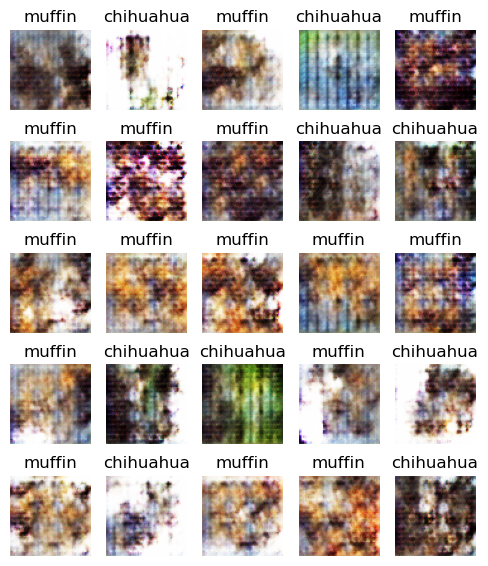

  0%|          | 0/37 [00:00<?, ?batch/s]

[Epoch 37/48]
	G_Trn_Loss: 3.6525	D_Trn_Loss: 0.7867	D_Trn_Real: 0.5977	D_Trn_Fake: 0.8148	D_Trn_Acc: 82.45% 
	G_Val_Loss: 2.1082	D_Val_Loss: 0.8438	D_Val_Real: 0.5977	D_Val_Fake: 0.8148	D_Val_Acc: 80.51%


  0%|          | 0/37 [00:00<?, ?batch/s]

[Epoch 38/48]
	G_Trn_Loss: 3.3221	D_Trn_Loss: 0.6715	D_Trn_Real: 0.7420	D_Trn_Fake: 0.4326	D_Trn_Acc: 89.36% 
	G_Val_Loss: 0.6672	D_Val_Loss: 1.3682	D_Val_Real: 0.7420	D_Val_Fake: 0.4326	D_Val_Acc: 61.45%


  0%|          | 0/37 [00:00<?, ?batch/s]

[Epoch 39/48]
	G_Trn_Loss: 3.4379	D_Trn_Loss: 0.7317	D_Trn_Real: 0.6515	D_Trn_Fake: 0.7521	D_Trn_Acc: 83.63% 
	G_Val_Loss: 1.5898	D_Val_Loss: 0.8074	D_Val_Real: 0.6515	D_Val_Fake: 0.7521	D_Val_Acc: 85.20%


  0%|          | 0/37 [00:00<?, ?batch/s]

[Epoch 40/48]
	G_Trn_Loss: 3.8851	D_Trn_Loss: 0.7388	D_Trn_Real: 0.6051	D_Trn_Fake: 0.7470	D_Trn_Acc: 84.20% 
	G_Val_Loss: 1.6816	D_Val_Loss: 0.9593	D_Val_Real: 0.6051	D_Val_Fake: 0.7470	D_Val_Acc: 78.59%


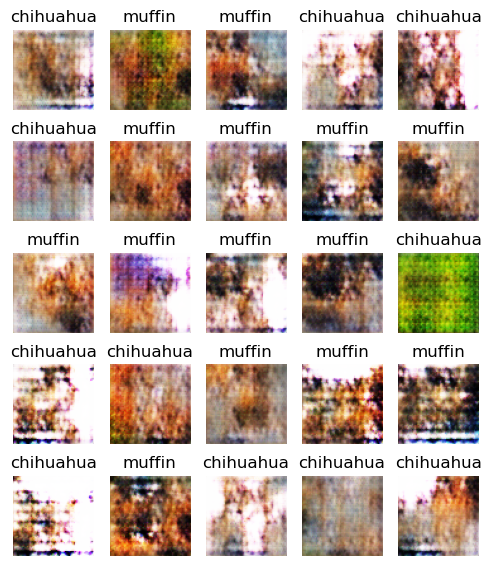

  0%|          | 0/37 [00:00<?, ?batch/s]

[Epoch 41/48]
	G_Trn_Loss: 3.4519	D_Trn_Loss: 0.6493	D_Trn_Real: 0.6470	D_Trn_Fake: 0.5697	D_Trn_Acc: 87.11% 
	G_Val_Loss: 0.9946	D_Val_Loss: 1.1674	D_Val_Real: 0.6470	D_Val_Fake: 0.5697	D_Val_Acc: 68.24%


  0%|          | 0/37 [00:00<?, ?batch/s]

[Epoch 42/48]
	G_Trn_Loss: 3.3285	D_Trn_Loss: 0.7553	D_Trn_Real: 0.4991	D_Trn_Fake: 0.6527	D_Trn_Acc: 83.52% 
	G_Val_Loss: 1.2539	D_Val_Loss: 1.3089	D_Val_Real: 0.4991	D_Val_Fake: 0.6527	D_Val_Acc: 63.01%


  0%|          | 0/37 [00:00<?, ?batch/s]

[Epoch 43/48]
	G_Trn_Loss: 3.3341	D_Trn_Loss: 0.7753	D_Trn_Real: 0.4501	D_Trn_Fake: 0.8829	D_Trn_Acc: 83.10% 
	G_Val_Loss: 2.5780	D_Val_Loss: 1.1267	D_Val_Real: 0.4501	D_Val_Fake: 0.8829	D_Val_Acc: 70.66%


  0%|          | 0/37 [00:00<?, ?batch/s]

[Epoch 44/48]
	G_Trn_Loss: 3.2707	D_Trn_Loss: 0.6923	D_Trn_Real: 0.2564	D_Trn_Fake: 0.9365	D_Trn_Acc: 86.29% 
	G_Val_Loss: 3.2417	D_Val_Loss: 1.7980	D_Val_Real: 0.2564	D_Val_Fake: 0.9365	D_Val_Acc: 56.84%


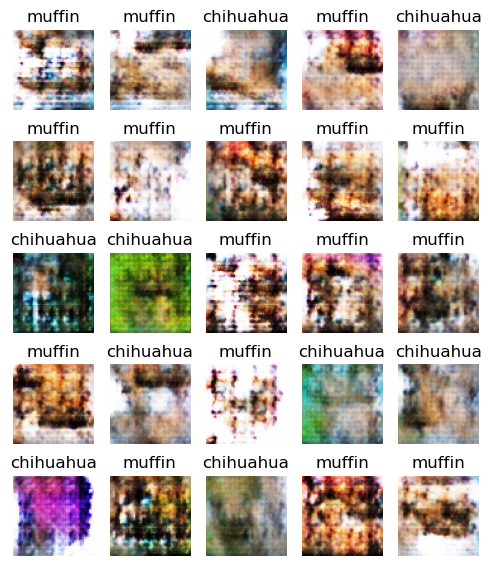

  0%|          | 0/37 [00:00<?, ?batch/s]

[Epoch 45/48]
	G_Trn_Loss: 3.4699	D_Trn_Loss: 0.8129	D_Trn_Real: 0.2919	D_Trn_Fake: 0.9547	D_Trn_Acc: 80.78% 
	G_Val_Loss: 3.6063	D_Val_Loss: 1.5932	D_Val_Real: 0.2919	D_Val_Fake: 0.9547	D_Val_Acc: 58.55%


  0%|          | 0/37 [00:00<?, ?batch/s]

[Epoch 46/48]
	G_Trn_Loss: 3.0243	D_Trn_Loss: 0.7130	D_Trn_Real: 0.5427	D_Trn_Fake: 0.6817	D_Trn_Acc: 85.61% 
	G_Val_Loss: 1.3258	D_Val_Loss: 1.1397	D_Val_Real: 0.5427	D_Val_Fake: 0.6817	D_Val_Acc: 71.02%


  0%|          | 0/37 [00:00<?, ?batch/s]

[Epoch 47/48]
	G_Trn_Loss: 3.2684	D_Trn_Loss: 0.7573	D_Trn_Real: 0.4901	D_Trn_Fake: 0.7282	D_Trn_Acc: 83.88% 
	G_Val_Loss: 1.5313	D_Val_Loss: 1.2212	D_Val_Real: 0.4901	D_Val_Fake: 0.7282	D_Val_Acc: 68.87%


  0%|          | 0/37 [00:00<?, ?batch/s]

[Epoch 48/48]
	G_Trn_Loss: 3.3923	D_Trn_Loss: 0.7722	D_Trn_Real: 0.2055	D_Trn_Fake: 0.9055	D_Trn_Acc: 83.11% 
	G_Val_Loss: 2.7077	D_Val_Loss: 2.0877	D_Val_Real: 0.2055	D_Val_Fake: 0.9055	D_Val_Acc: 54.57%


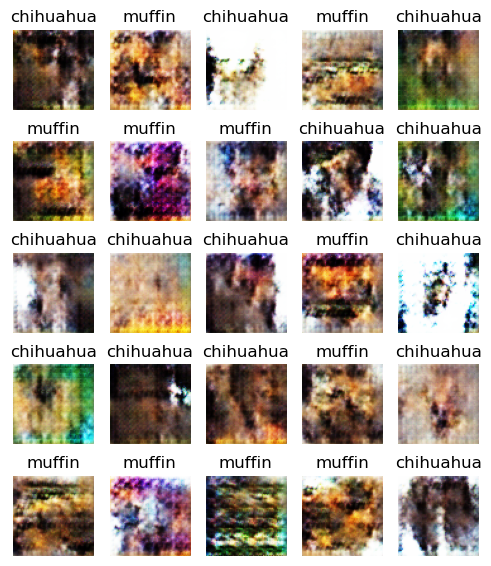

In [53]:
g_stats, d_stats = train(
    generator,
    discriminator,
    train_loader,
    val_loader,
    g_optimizer,
    d_optimizer,
    criterion,
    device,
    num_classes=num_classes,
    epochs=epochs,
    plot_frequency=4,
    label_mapper=muffin_mapper,
)